# Pediatric Sepsis Challenge

Challenge description: https://sepsis.ubc.ca/research/current-research-projects/pediatric-sepsis-data-challenge

Repository: https://github.com/Kamaleswaran-Lab/The-2024-Pediatric-Sepsis-Challenge/tree/main

Forum: https://groups.google.com/g/2024-pediatric-sepsis-data-challenge

In [1]:
# Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
# Load the data
raw_data = pd.read_csv('../SyntheticData_training.csv')

In [3]:
# Head of the dataset
raw_data.head()

,studyid_adm,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,...,cookloc_adm,lightfuel_adm,tobacco_adm,bednet_adm,hctpretransfusion_adm,hivstatus_adm,malariastatuspos_adm,lengthadm,caregiver_adm_new,inhospital_mortality
0,1,16.8,79.8,11.6,150.0,130.0,23.0,92.0,54.0,36.3,...,In a separate building/building space used as ...,Electric bulbs (national grid),Never,Always,Yes,HIV negative,No,2,Mother,0
1,2,46.1,93.0,13.6,151.0,115.0,35.0,72.0,42.0,36.8,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,Yes,5,Mother,0
2,3,7.9,68.2,8.2,148.0,150.0,56.0,94.0,51.0,37.2,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,No,4,Mother,0
3,4,38.2,95.0,12.0,138.0,134.0,38.0,94.0,57.0,37.6,...,In the house where you sleep,Electric bulbs (national grid),Never,Always,NaN,HIV negative,Yes,5,Mother,0
4,5,16.1,83.0,12.0,165.0,163.0,61.0,107.0,73.0,38.7,...,Outdoors in the open,Electric bulbs (national grid),Never,Sometimes,Yes,HIV negative,Yes,7,Mother,0


In [4]:
# Dataset information
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Columns: 140 entries, studyid_adm to inhospital_mortality
dtypes: float64(23), int64(3), object(114)
memory usage: 2.9+ MB


The data dictionary describe the same amount of features describred in this dataset. However, The dictionary contains 2 Discrete and 113 Categorical.

### Datatypes

Let's fix some datatypes in the dataset:
- studyid_adm is Float but correct would be integer. Actually this column it's not necessary.
- the output is float but it's a categorical column.

In [5]:
# To keep available the raw_data, let's create a clean_data df.
clean_data = raw_data

In [6]:
# Change datatype
clean_data.drop(columns=['studyid_adm'], inplace=True)

In [7]:
# Sanity check
clean_data

,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,spo2site1_pc_oxi_adm,...,cookloc_adm,lightfuel_adm,tobacco_adm,bednet_adm,hctpretransfusion_adm,hivstatus_adm,malariastatuspos_adm,lengthadm,caregiver_adm_new,inhospital_mortality
0,16.8,79.8,11.6,150.0,130.0,23.0,92.0,54.0,36.3,99.0,...,In a separate building/building space used as ...,Electric bulbs (national grid),Never,Always,Yes,HIV negative,No,2,Mother,0
1,46.1,93.0,13.6,151.0,115.0,35.0,72.0,42.0,36.8,92.0,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,Yes,5,Mother,0
2,7.9,68.2,8.2,148.0,150.0,56.0,94.0,51.0,37.2,99.0,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,No,4,Mother,0
3,38.2,95.0,12.0,138.0,134.0,38.0,94.0,57.0,37.6,98.0,...,In the house where you sleep,Electric bulbs (national grid),Never,Always,NaN,HIV negative,Yes,5,Mother,0
4,16.1,83.0,12.0,165.0,163.0,61.0,107.0,73.0,38.7,90.0,...,Outdoors in the open,Electric bulbs (national grid),Never,Sometimes,Yes,HIV negative,Yes,7,Mother,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2681,20.1,98.2,10.0,135.0,163.0,61.0,103.0,54.0,39.6,98.0,...,Outdoors in the open,Solar powered bulbs,Never,Always,Yes,HIV negative,No,3,Mother,0
2682,26.8,82.3,10.0,140.0,115.0,37.0,83.0,50.0,37.1,96.0,...,Outdoors in the open,Electric bulbs (national grid),Never,Sometimes,NaN,HIV negative,No,3,Mother,0
2683,14.6,82.4,12.7,145.0,150.0,40.0,93.0,35.0,38.5,98.0,...,In a separate building/building space used as ...,Electric bulbs (national grid),Never,Always,Yes,HIV negative,Yes,2,Mother,0
2684,9.5,67.5,7.5,130.0,145.0,26.0,88.0,52.0,37.3,99.0,...,In a separate building/building space used as ...,Solar powered bulbs,Never,Always,Yes,HIV negative,No,4,Mother,0


In [8]:
# Change datatype
clean_data['inhospital_mortality'] = clean_data['inhospital_mortality'].astype('object')

In [9]:
# Sanity check
print(clean_data['inhospital_mortality'].dtypes)

object


### Removing Interventions columns

This columns are strong predictors and complex to collect. No authorized to be included in modeling.
They describe antibiotics administered in the patient admission.

In [10]:
# Defining the columns to eliminate from the clean_data df.
columns_to_drop = clean_data.columns[clean_data.columns.str.contains('admitabx_adm_')]
columns_to_drop

Index(['admitabx_adm___1', 'admitabx_adm___2', 'admitabx_adm___3',
       'admitabx_adm___4', 'admitabx_adm___5', 'admitabx_adm___6',
       'admitabx_adm___7', 'admitabx_adm___8', 'admitabx_adm___9',
       'admitabx_adm___10', 'admitabx_adm___11', 'admitabx_adm___12',
       'admitabx_adm___13', 'admitabx_adm___14', 'admitabx_adm___15',
       'admitabx_adm___16', 'admitabx_adm___17', 'admitabx_adm___18',
       'admitabx_adm___19', 'admitabx_adm___20', 'admitabx_adm___21'],
      dtype='object')

In [11]:
clean_data = clean_data.drop(columns=columns_to_drop)

In [12]:
#Sanity check
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Columns: 118 entries, agecalc_adm to inhospital_mortality
dtypes: float64(23), int64(1), object(94)
memory usage: 2.4+ MB


**Be aware that 'lengthadm' Length of admission is an outcome column. It is the total days the hospitalization was.It is an outcome column and needs to be eliminated as well. **

In [13]:
clean_data.drop(columns=['lengthadm'], inplace = True)

In [14]:
#Sanity check
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Columns: 117 entries, agecalc_adm to inhospital_mortality
dtypes: float64(23), object(94)
memory usage: 2.4+ MB


### Data Exploration

#### Duplicates

In [15]:
# Duplicates
clean_data.duplicated().sum()

0

Good. No duplicates.

#### Missing values
I expect some missing values as described in the data dictionary.

In [16]:
# Filter the DataFrame to include only columns with missing values
columns_with_missing = clean_data.columns[clean_data.isnull().any()]
df_with_missing = clean_data[columns_with_missing]

In [17]:
# Getting the percentage of missing data in columns with missing values
missing_percentage = df_with_missing.isnull().sum() / len(df_with_missing) * 100
missing_percentage.sort_values(ascending=False)

nonexclbreastfed_adm        96.909903
spo2other_adm               93.261355
lactate2_mmolpl_adm         82.539092
vaccmeaslessource_adm       35.219657
lactate_mmolpl_adm          17.274758
hematocrit_gpdl_adm         17.014147
momagefirstpreg_adm          8.339538
sqi2_perc_oxi_adm            7.706627
spo2site2_pc_oxi_adm         7.632167
vaccpneumocsource_adm        6.887565
vaccdptsource_adm            5.323902
sqi1_perc_oxi_adm            4.839911
hctpretransfusion_adm        1.600894
momageknown_adm              0.819062
momage_adm                   0.707372
height_cm_adm                0.521221
muac_mm_adm                  0.483991
glucose_mmolpl_adm           0.335071
weight_kg_adm                0.335071
momhiv_adm                   0.223380
rr_brpm_app_adm              0.186150
priorhosp_adm                0.186150
hivstatus_adm                0.186150
spo2site1_pc_oxi_adm         0.148920
spo2onoxy_adm                0.148920
badhealthduration_adm        0.148920
alivechildre

In [18]:
# Getting the total of missing data in columns with missing values
missing_percentage = df_with_missing.isnull().sum()
missing_percentage.sort_values(ascending=False)

nonexclbreastfed_adm        2603
spo2other_adm               2505
lactate2_mmolpl_adm         2217
vaccmeaslessource_adm        946
lactate_mmolpl_adm           464
hematocrit_gpdl_adm          457
momagefirstpreg_adm          224
sqi2_perc_oxi_adm            207
spo2site2_pc_oxi_adm         205
vaccpneumocsource_adm        185
vaccdptsource_adm            143
sqi1_perc_oxi_adm            130
hctpretransfusion_adm         43
momageknown_adm               22
momage_adm                    19
height_cm_adm                 14
muac_mm_adm                   13
glucose_mmolpl_adm             9
weight_kg_adm                  9
momhiv_adm                     6
rr_brpm_app_adm                5
priorhosp_adm                  5
hivstatus_adm                  5
spo2site1_pc_oxi_adm           4
spo2onoxy_adm                  4
badhealthduration_adm          4
alivechildren_adm              4
bednet_adm                     3
lightfuel_adm                  3
caregiver_adm_new              3
households

##### Visualize the distributions

#### The outcome

In [19]:
clean_data['inhospital_mortality'].value_counts(normalize=True)

0    0.955696
1    0.044304
Name: inhospital_mortality, dtype: float64

~4.4% of the patients died. 

#### Visualize the categorical Columns

<div class="alert alert-block alert-info">
<b>NOTE:</b> Compare the distributions and categories in both outcome classes. 
</div>

In [20]:
def plot_categorical_with_subplots(column_name):
    # Calculate the count and percentage of 'inhospital_mortality' values for each category in the column
    category_counts = clean_data[column_name].value_counts()
    category_counts_inhospital_mortality = clean_data.groupby(column_name)['inhospital_mortality'].value_counts().unstack().fillna(0)
    
    # Percentages for the first plot
    category_percentages = (category_counts_inhospital_mortality.T / category_counts_inhospital_mortality.sum(axis=1)).T * 100
    
    # Figure with 2 subplots
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 1]})
    
    # Plot 1: Percentages
    category_percentages.plot(kind='bar', stacked=True, ax=axes[0])
    axes[0].set_title('Percentage of inhospital_mortality by {}'.format(column_name))
    axes[0].set_xlabel(column_name)
    axes[0].set_ylabel('Percentage')
    axes[0].legend(title='inhospital_mortality', loc='lower right')
    
    # Plot 2: Absolute counts
    category_counts_inhospital_mortality.plot(kind='bar', stacked=True, ax=axes[1])
    axes[1].set_title('Number of cases by inhospital_mortality for {}'.format(column_name))
    axes[1].set_xlabel(column_name)
    axes[1].set_ylabel('Number of Cases')
    axes[1].legend(title='inhospital_mortality', loc='lower right')
    
    # Adjust layout
    plt.tight_layout()
    plt.show()

Plotting for column: sex_adm


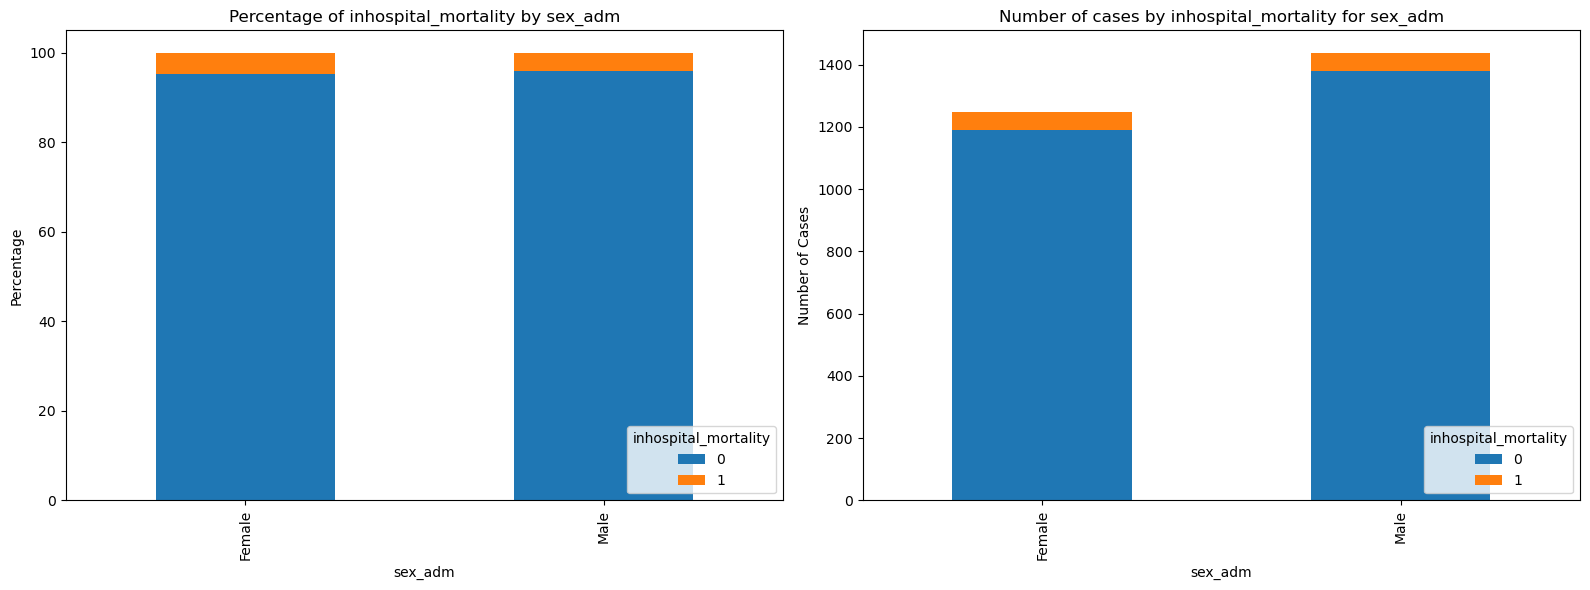

Plotting for column: spo2onoxy_adm


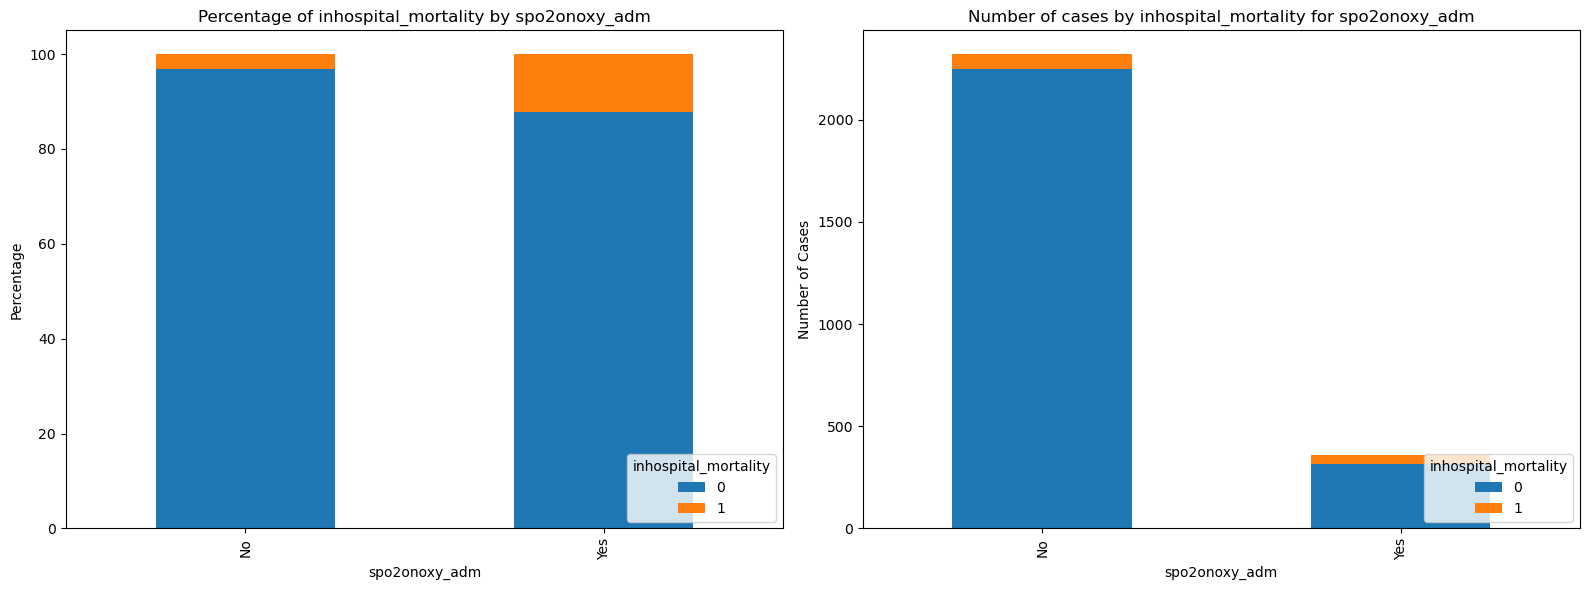

Plotting for column: oxygenavail_adm


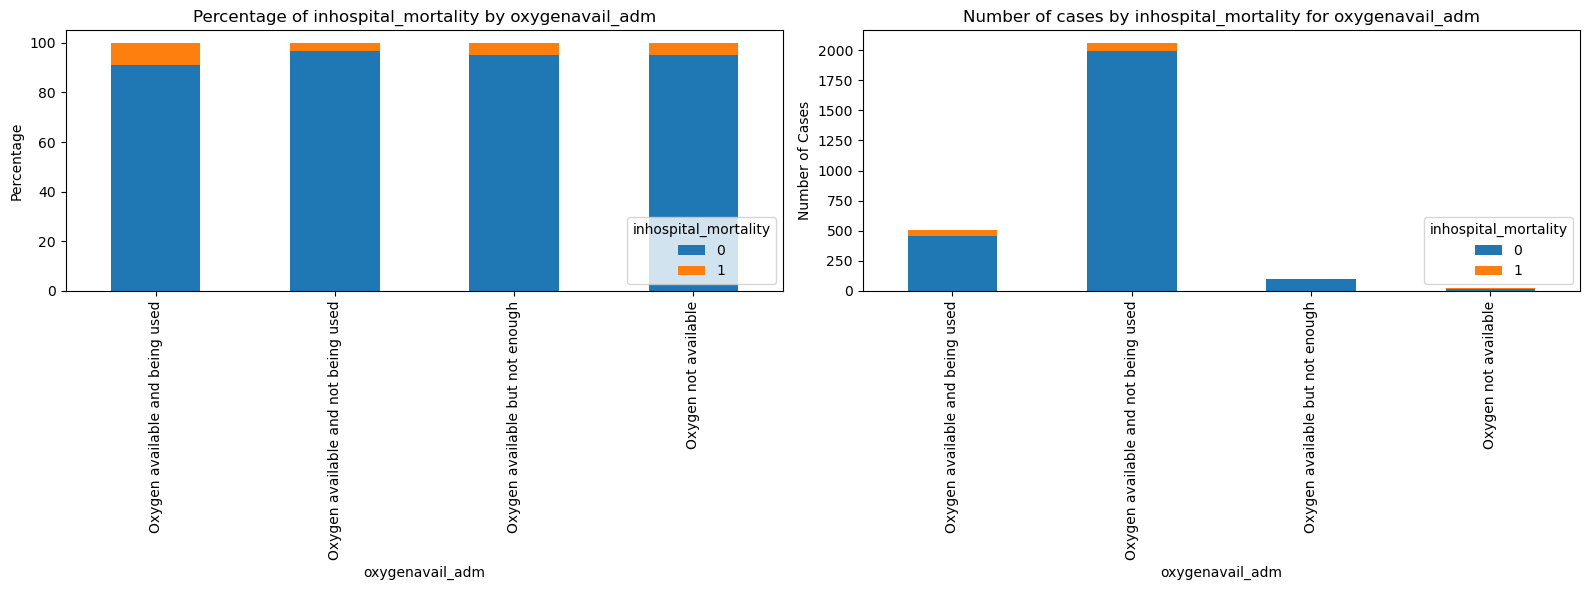

Plotting for column: respdistress_adm


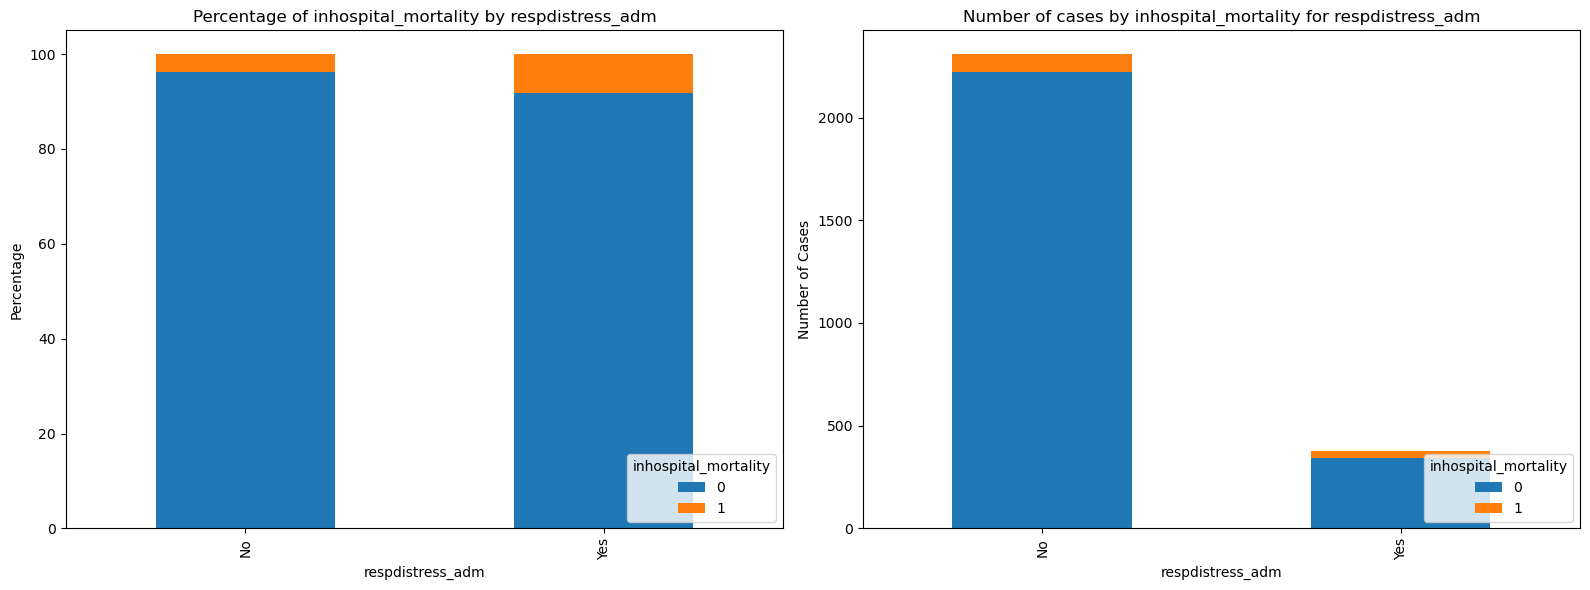

Plotting for column: caprefill_adm


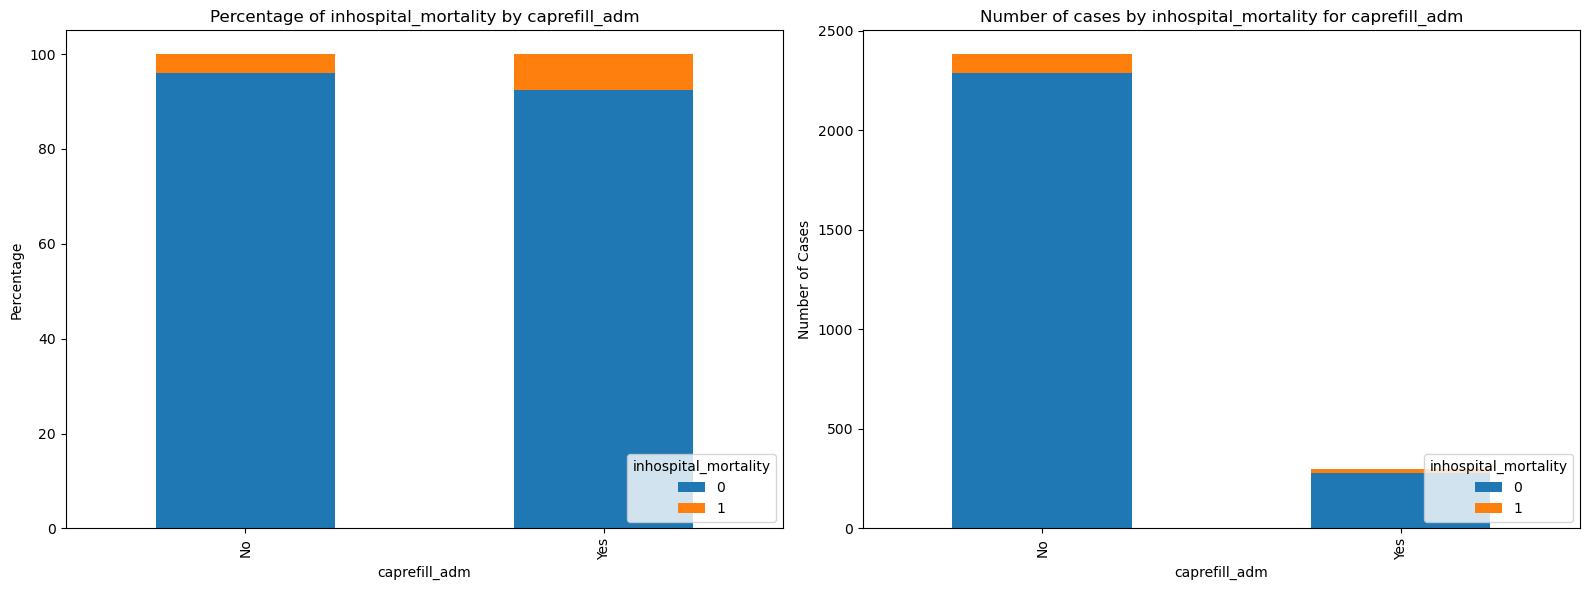

Plotting for column: bcseye_adm


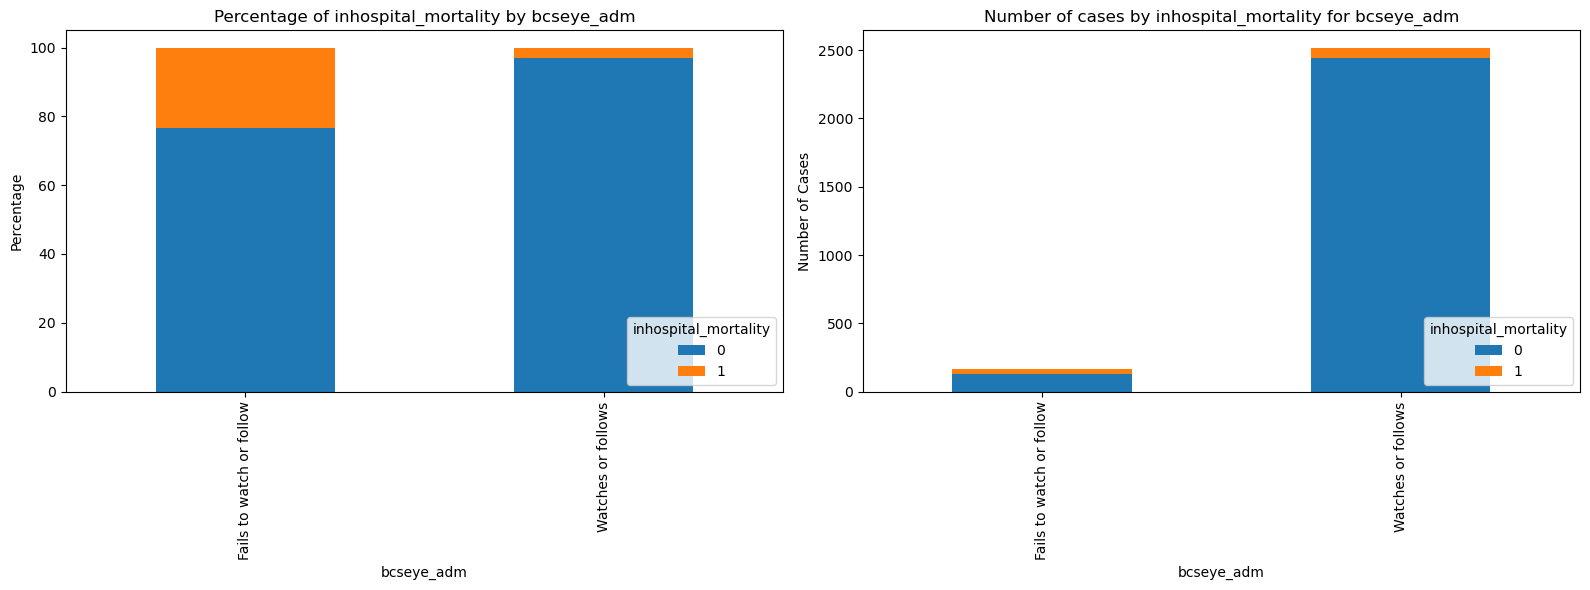

Plotting for column: bcsmotor_adm


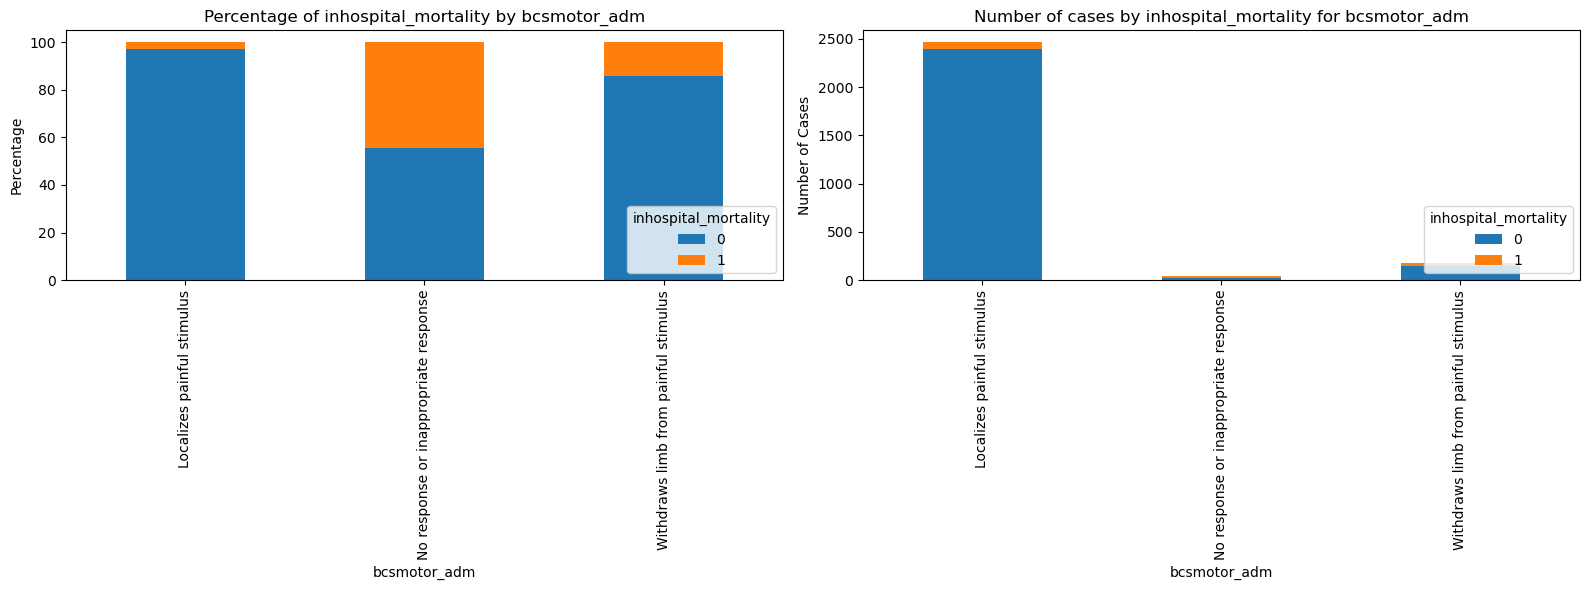

Plotting for column: bcsverbal_adm


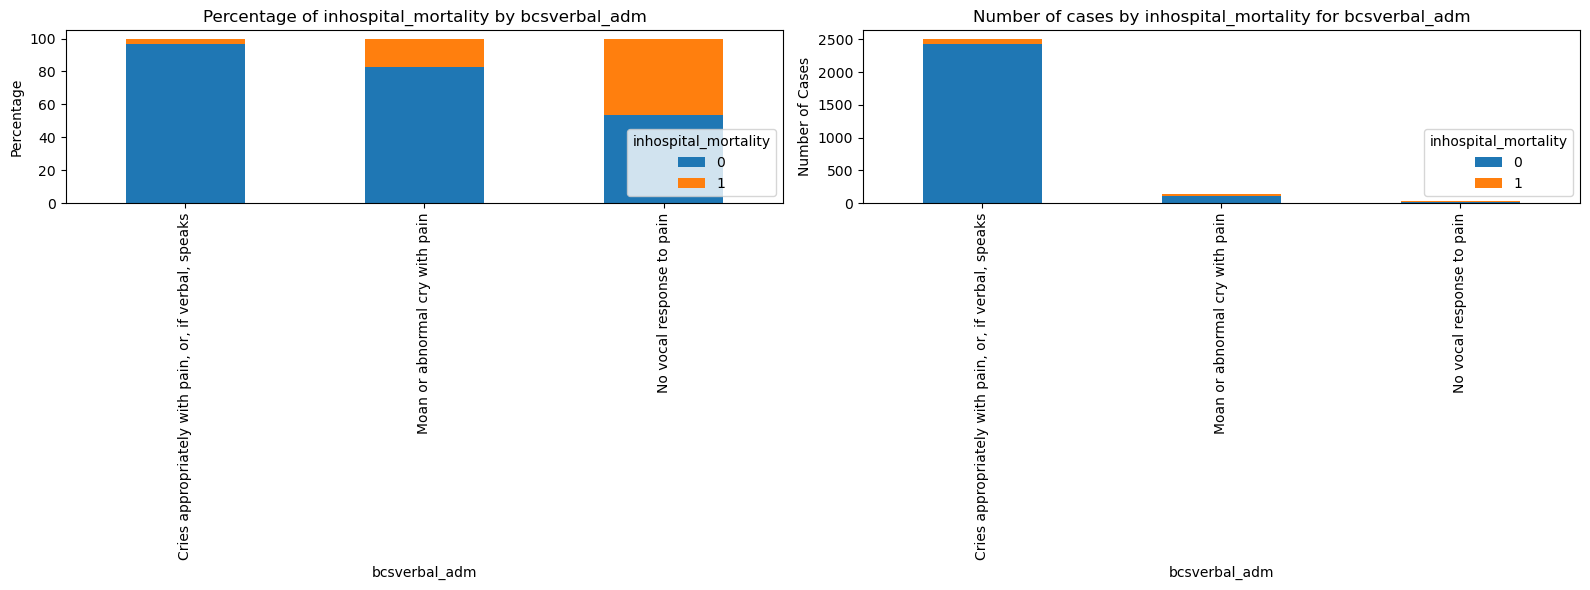

Plotting for column: bcgscar_adm


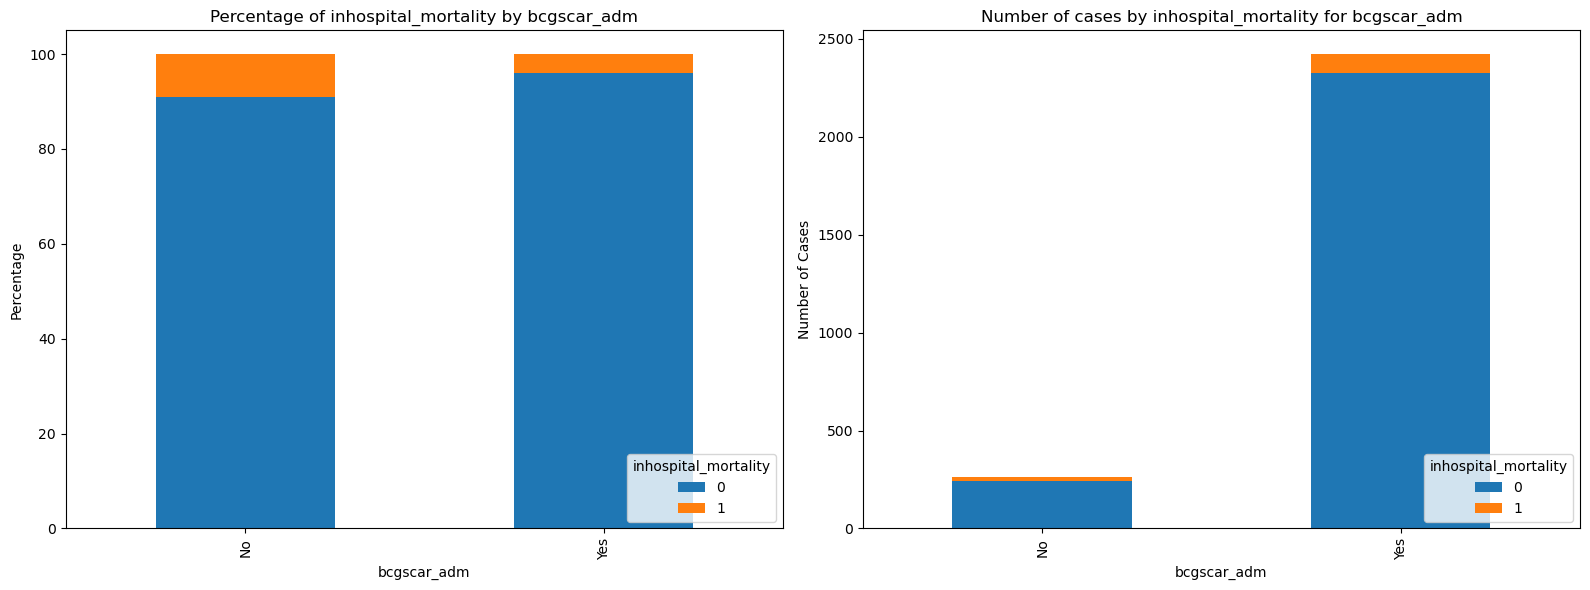

Plotting for column: vaccmeasles_adm


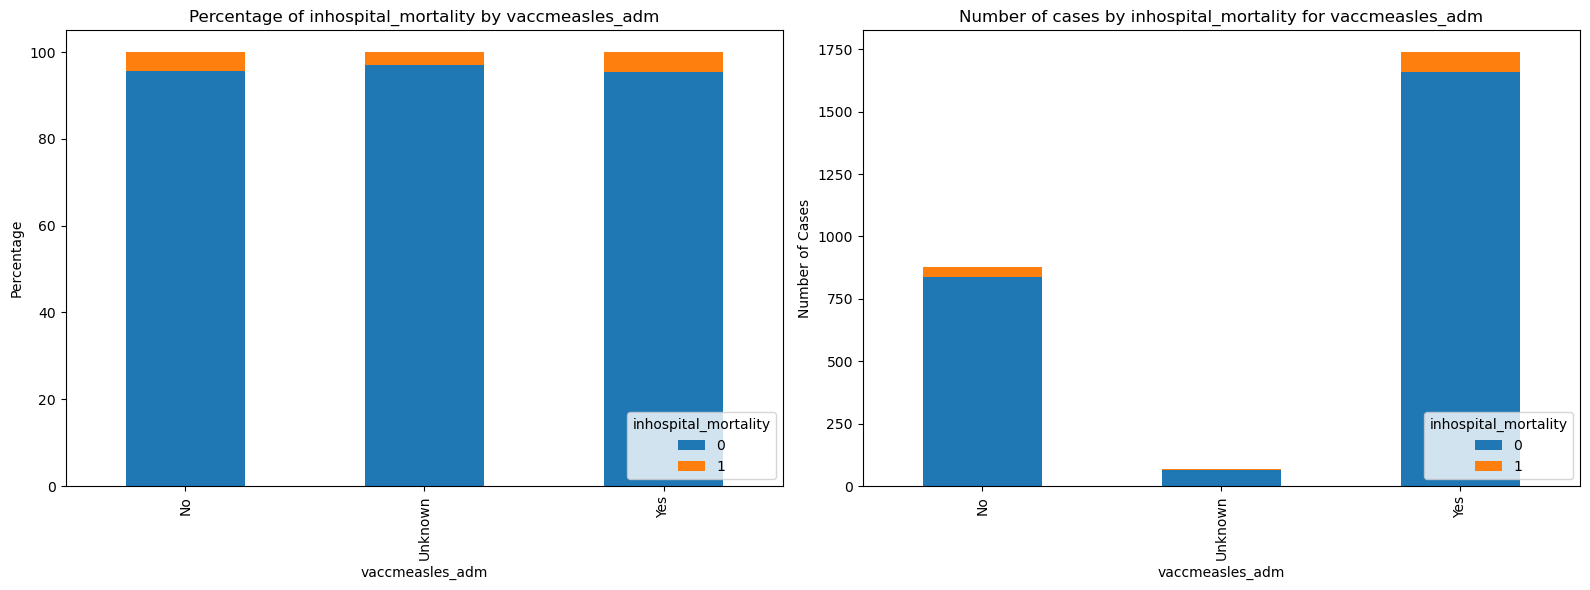

Plotting for column: vaccmeaslessource_adm


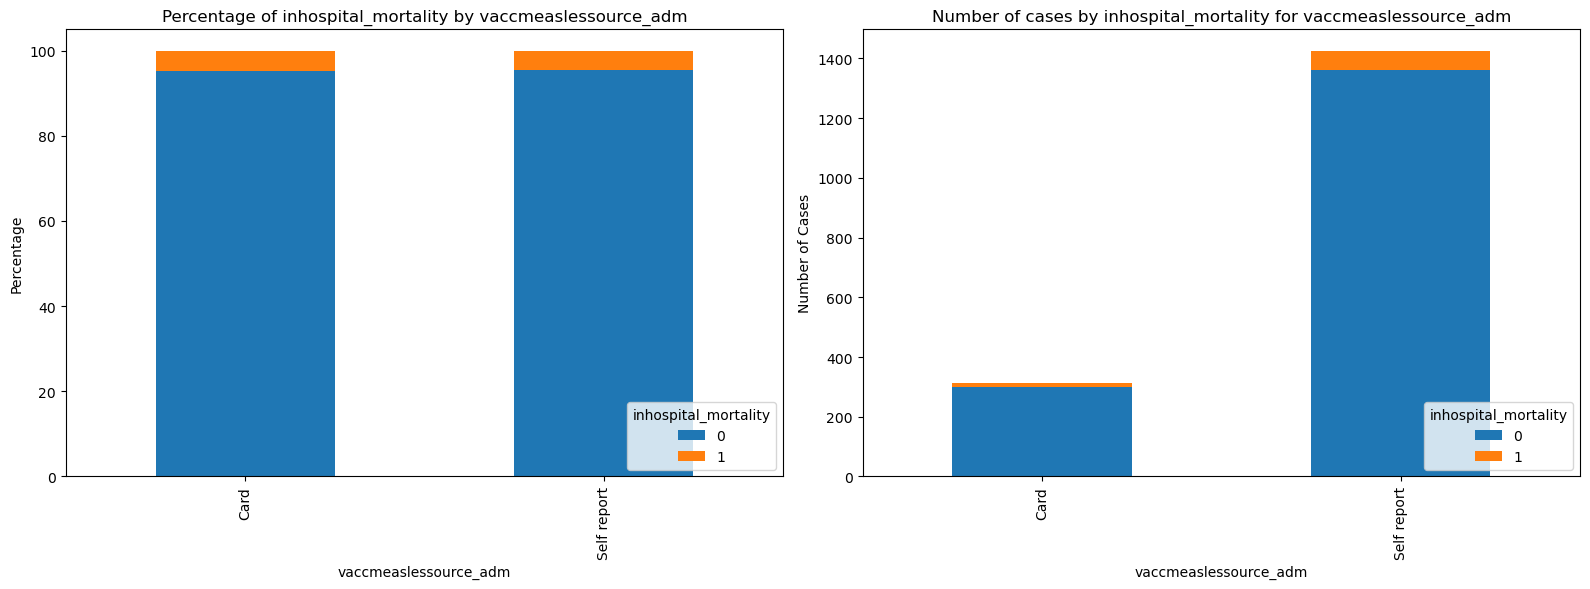

Plotting for column: vaccpneumoc_adm


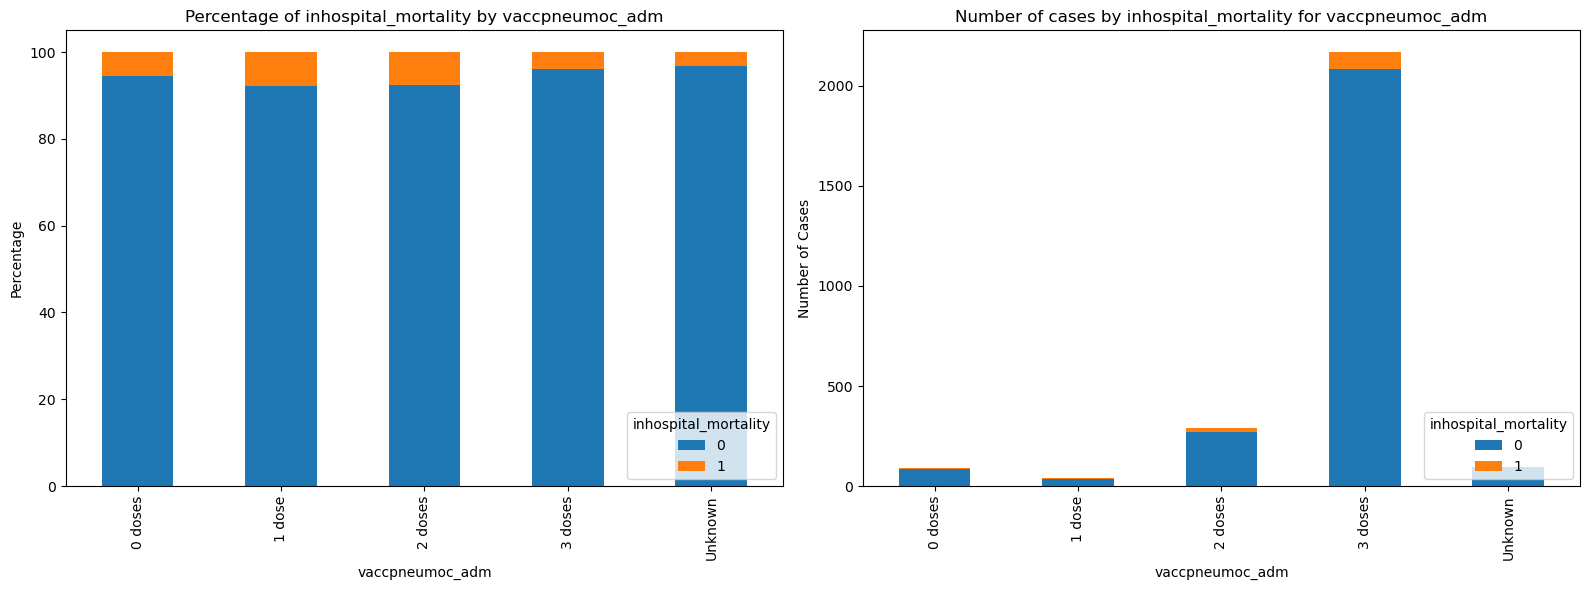

Plotting for column: vaccpneumocsource_adm


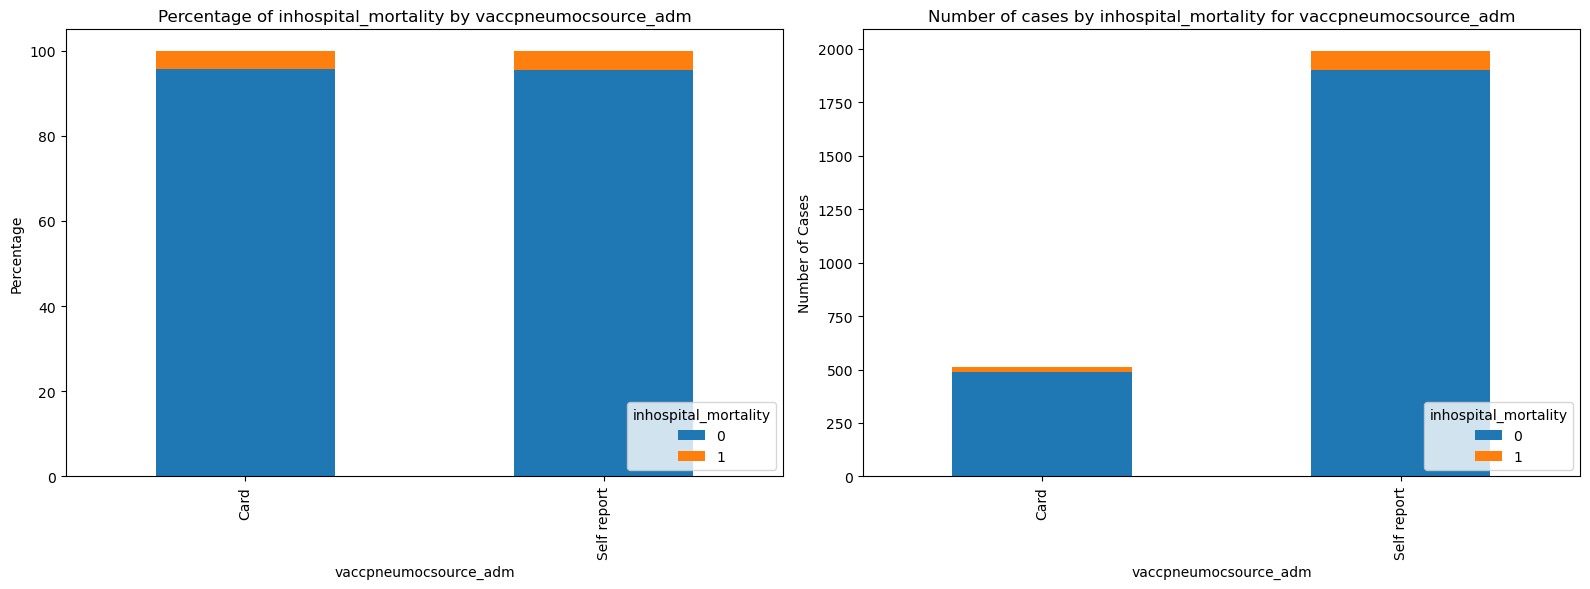

Plotting for column: vaccdpt_adm


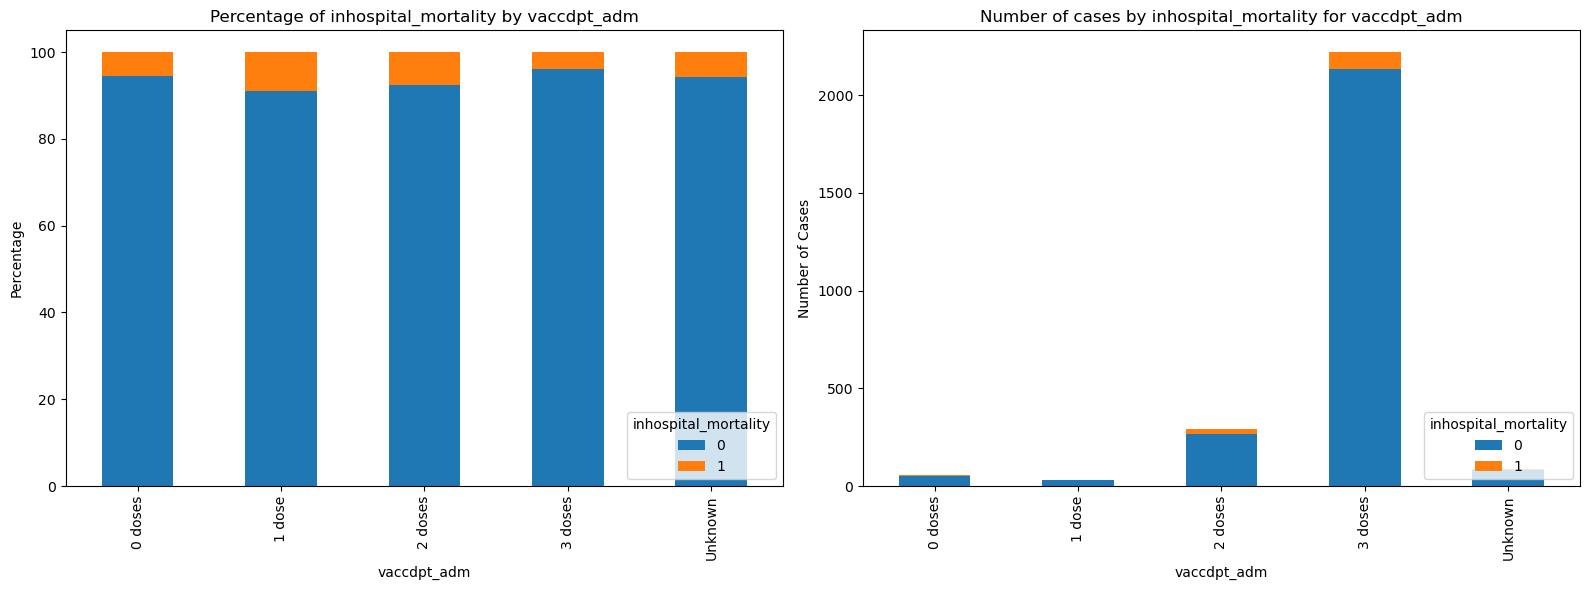

Plotting for column: vaccdptsource_adm


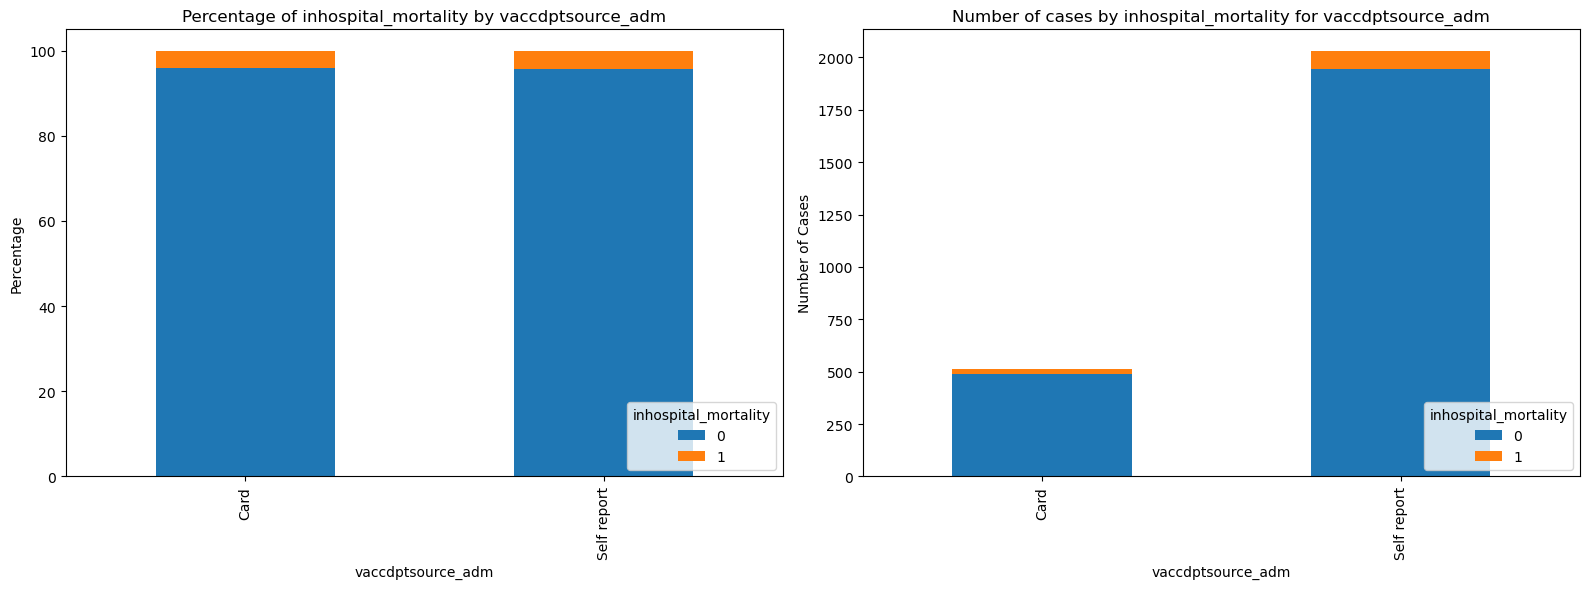

Plotting for column: priorweekabx_adm


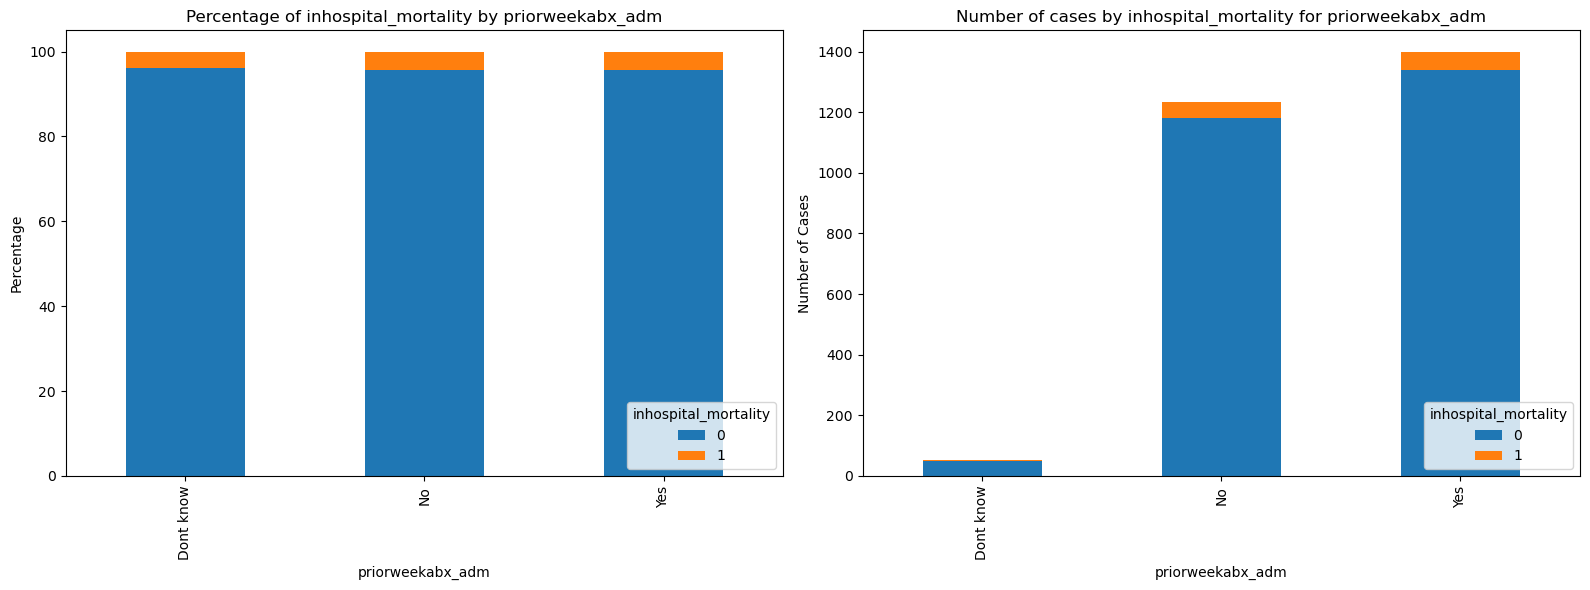

Plotting for column: priorweekantimal_adm


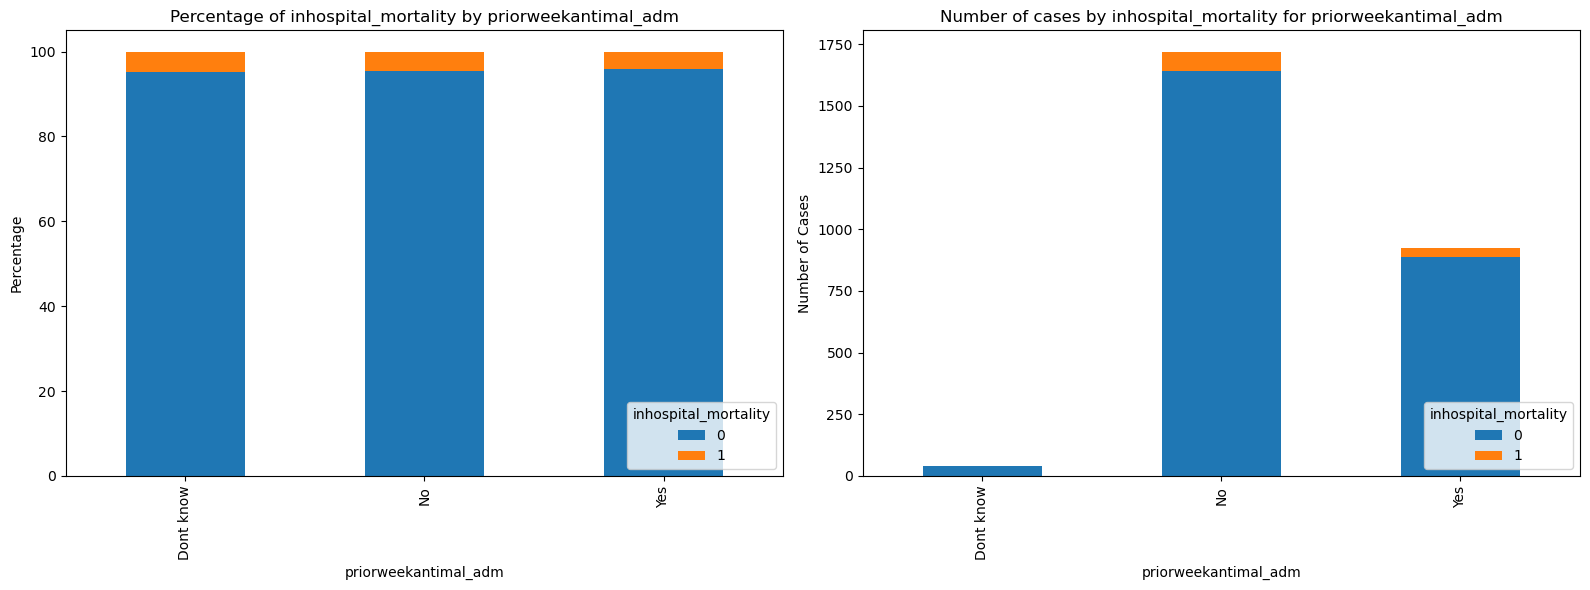

Plotting for column: symptoms_adm___1


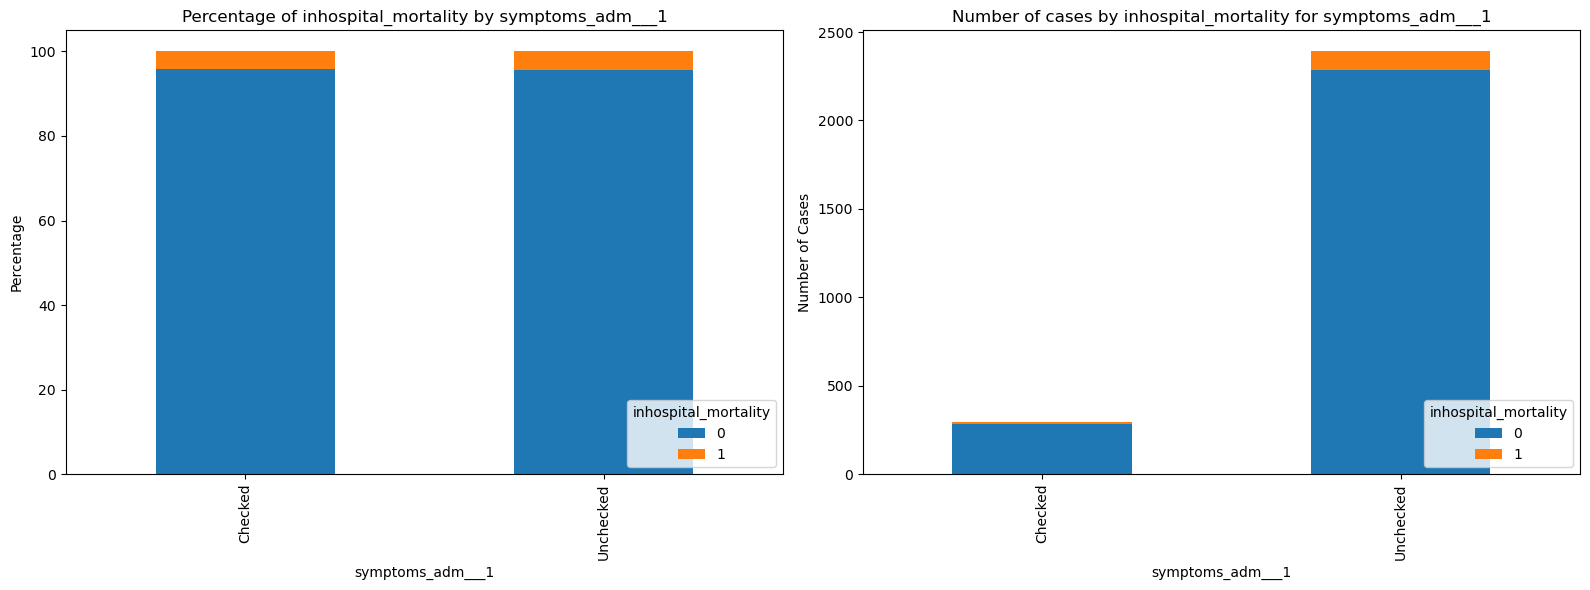

Plotting for column: symptoms_adm___2


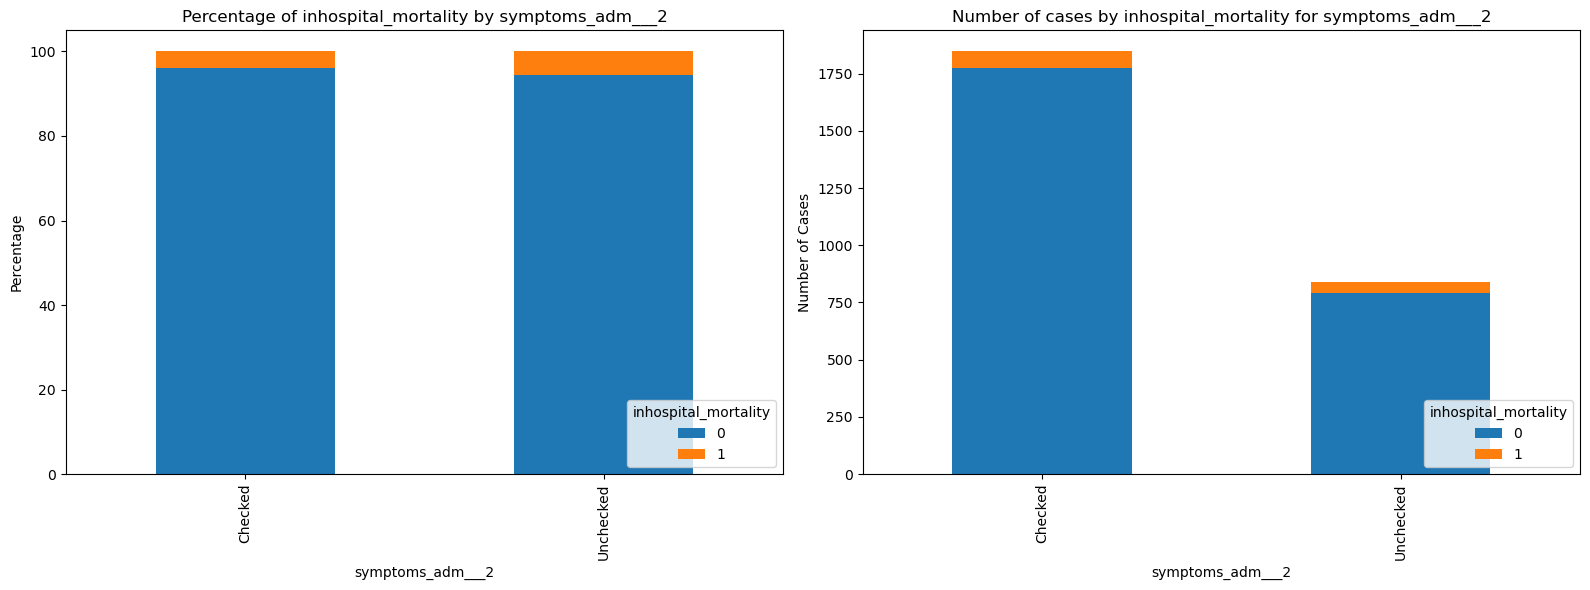

Plotting for column: symptoms_adm___3


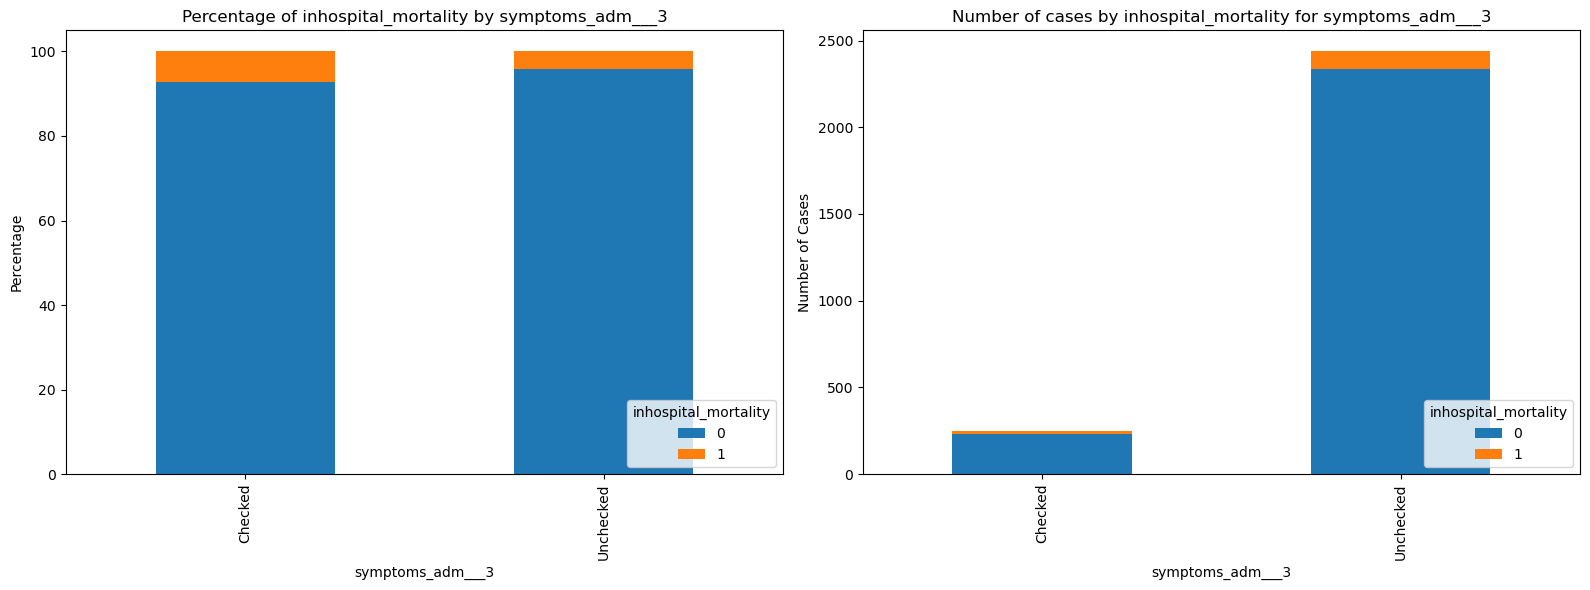

Plotting for column: symptoms_adm___4


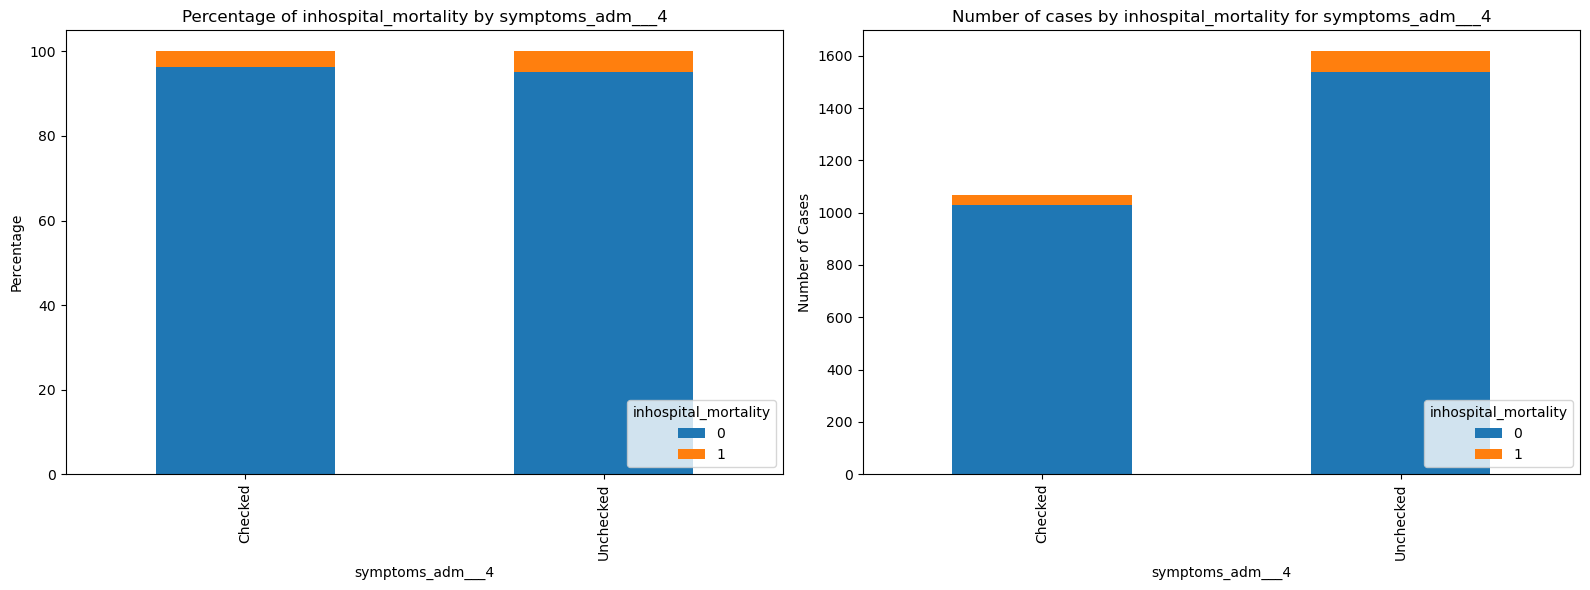

Plotting for column: symptoms_adm___5


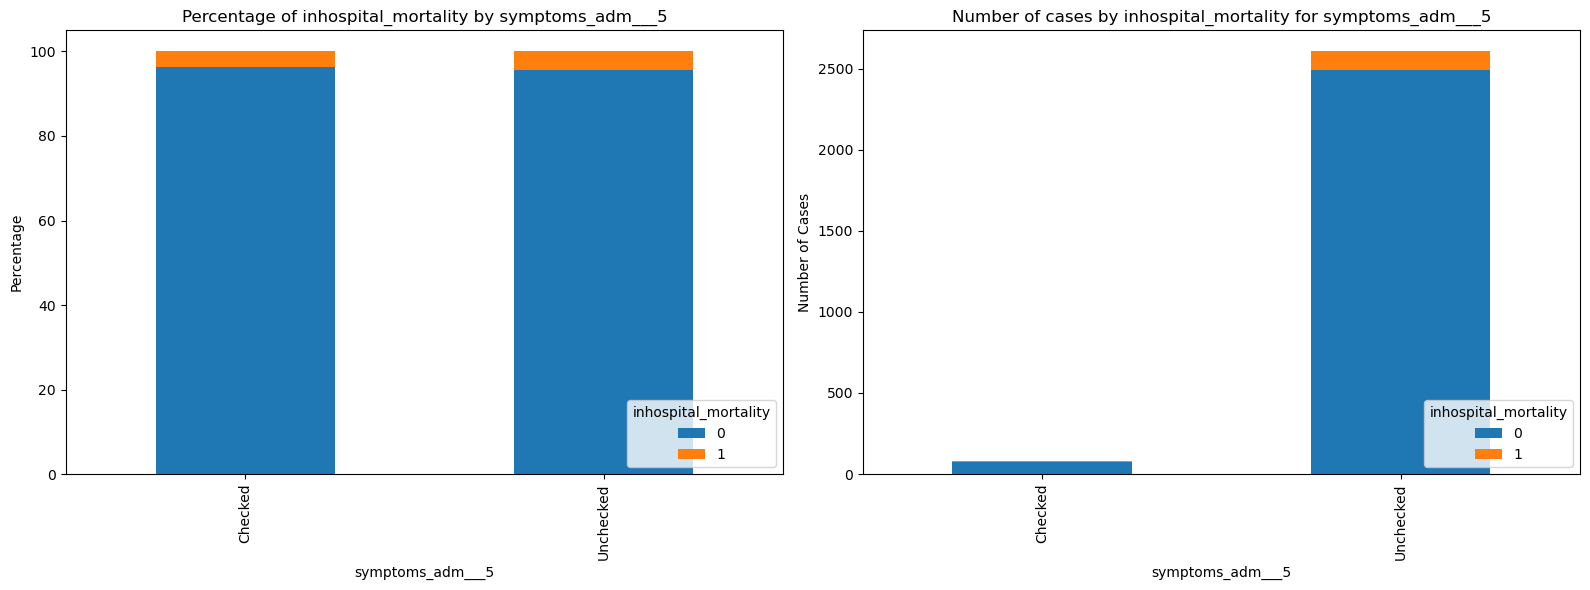

Plotting for column: symptoms_adm___6


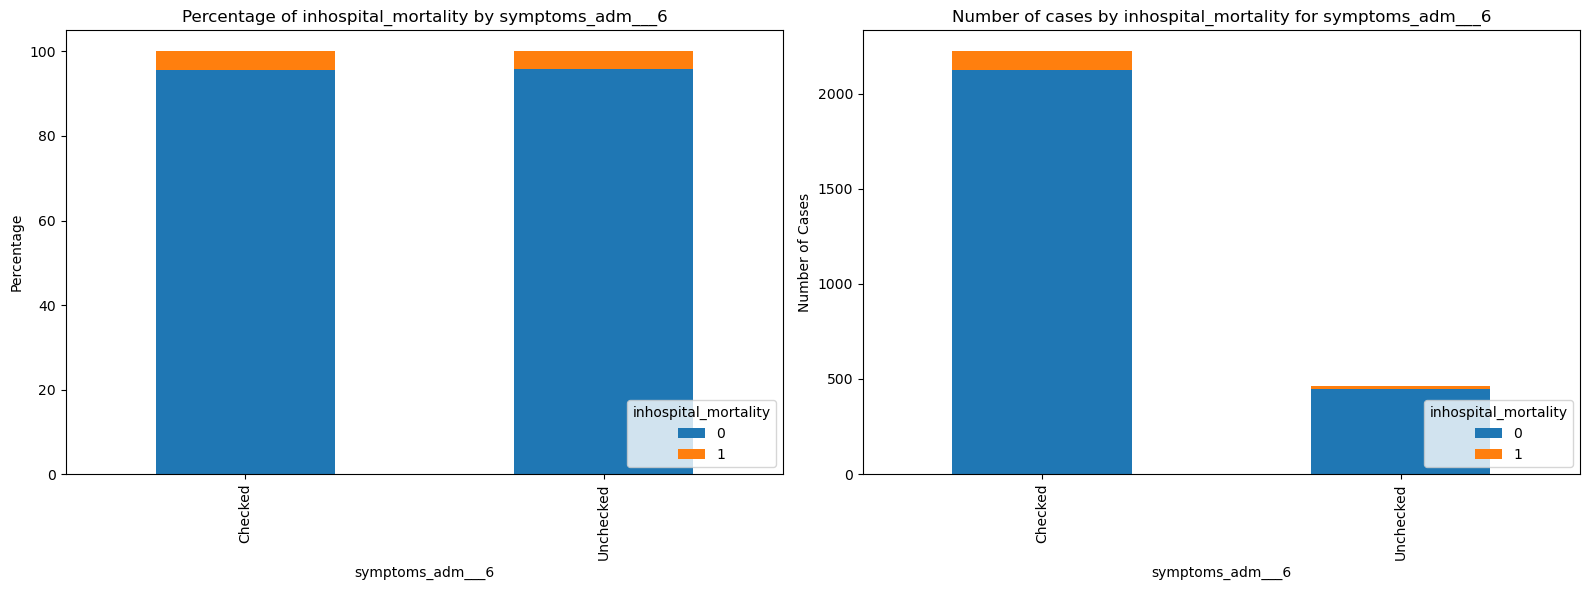

Plotting for column: symptoms_adm___7


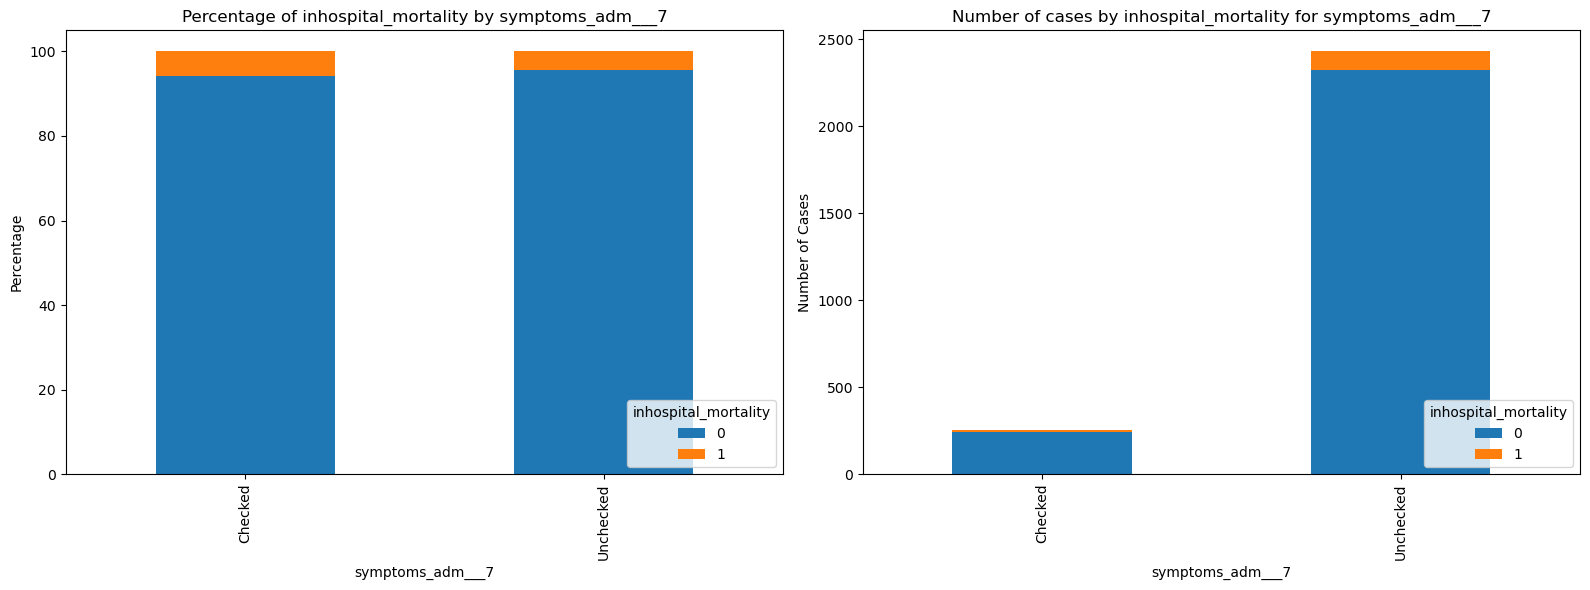

Plotting for column: symptoms_adm___8


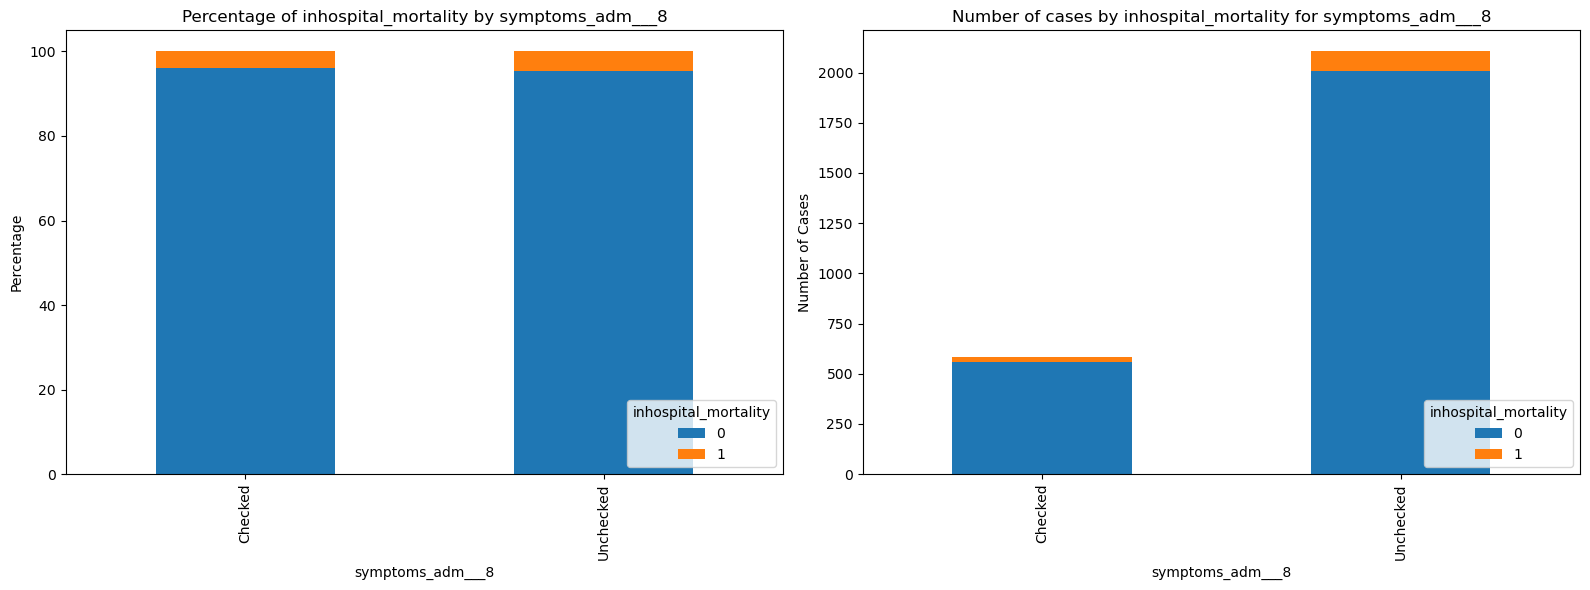

Plotting for column: symptoms_adm___9


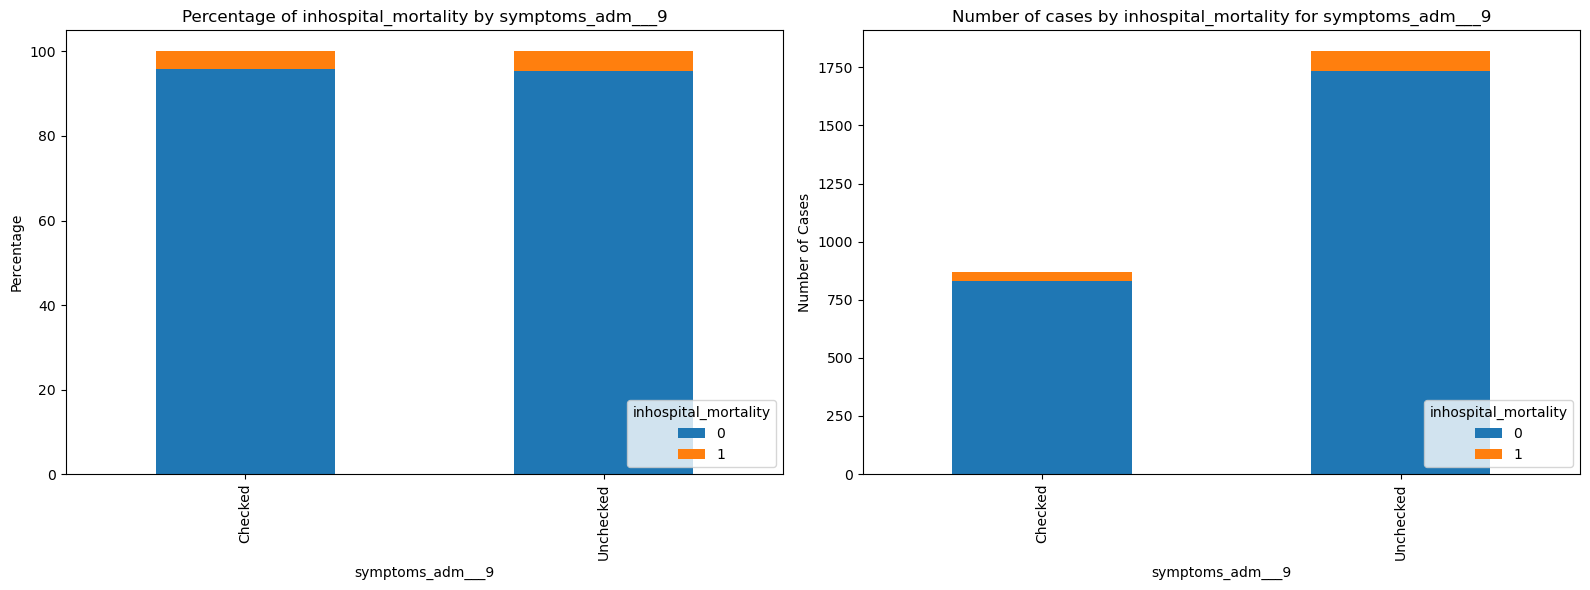

Plotting for column: symptoms_adm___10


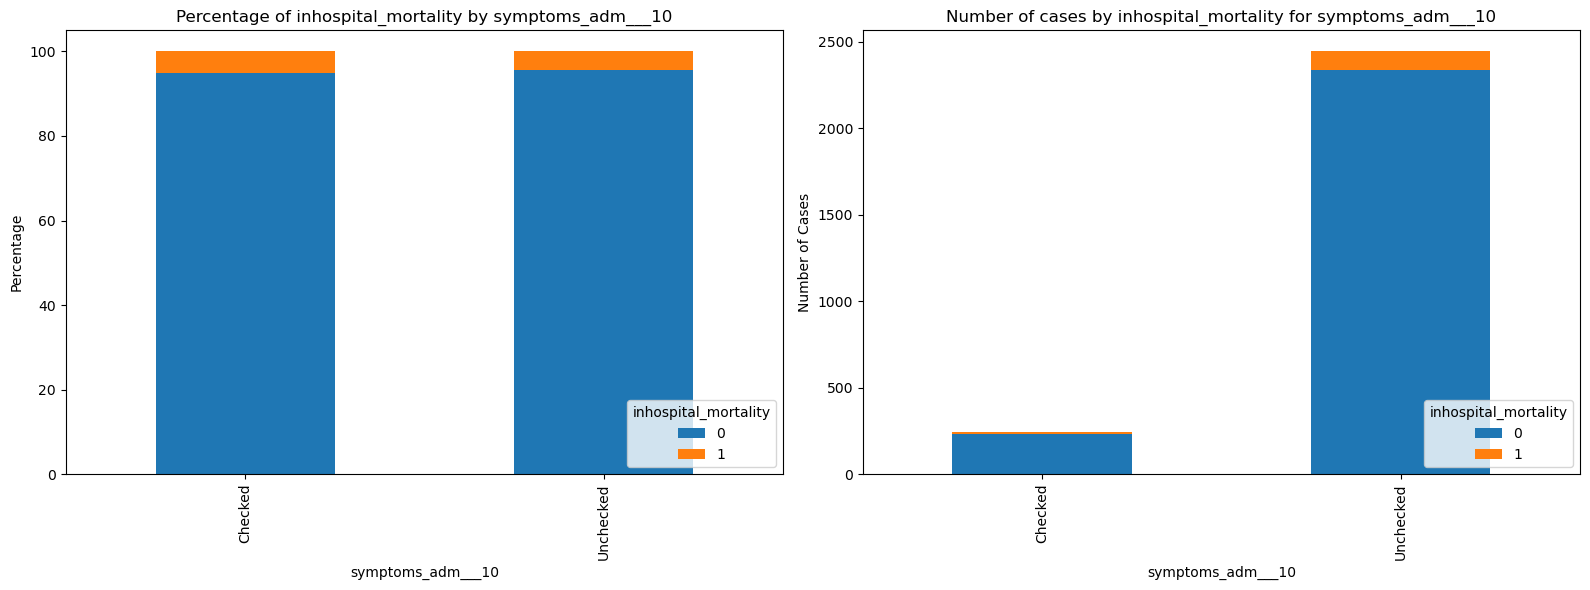

Plotting for column: symptoms_adm___11


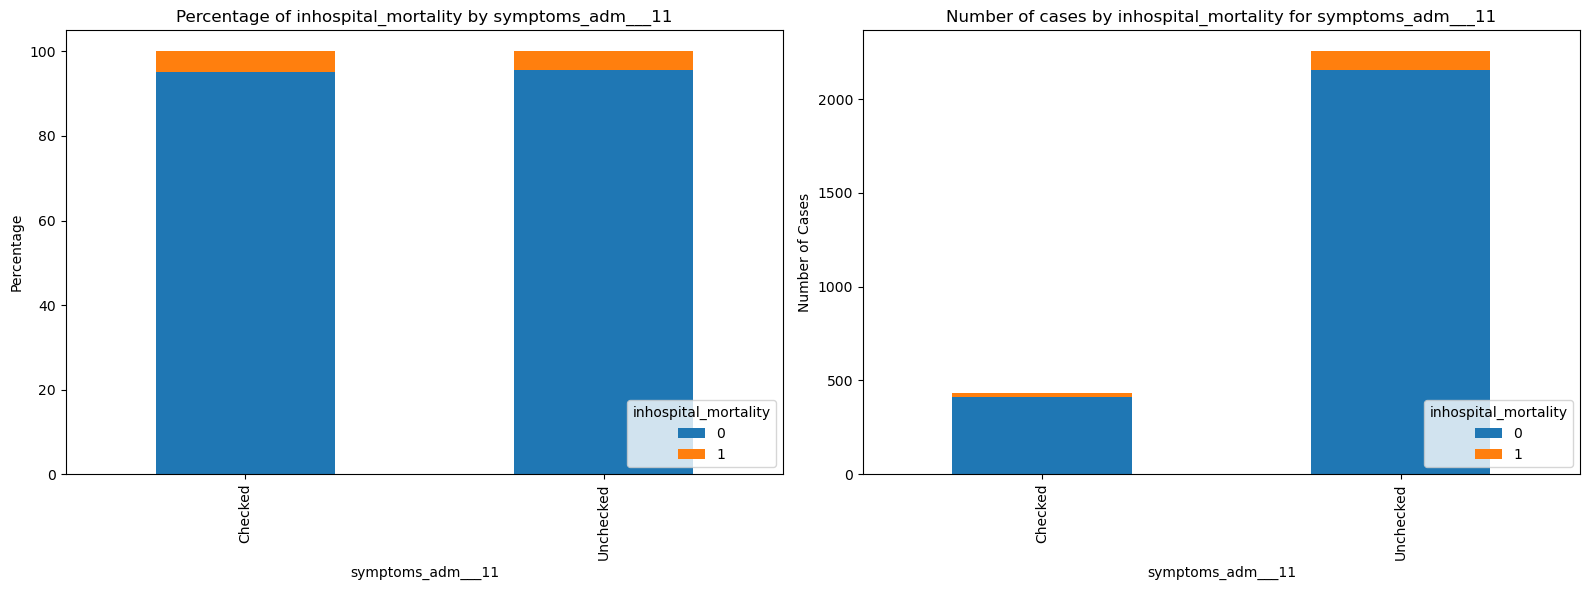

Plotting for column: symptoms_adm___12


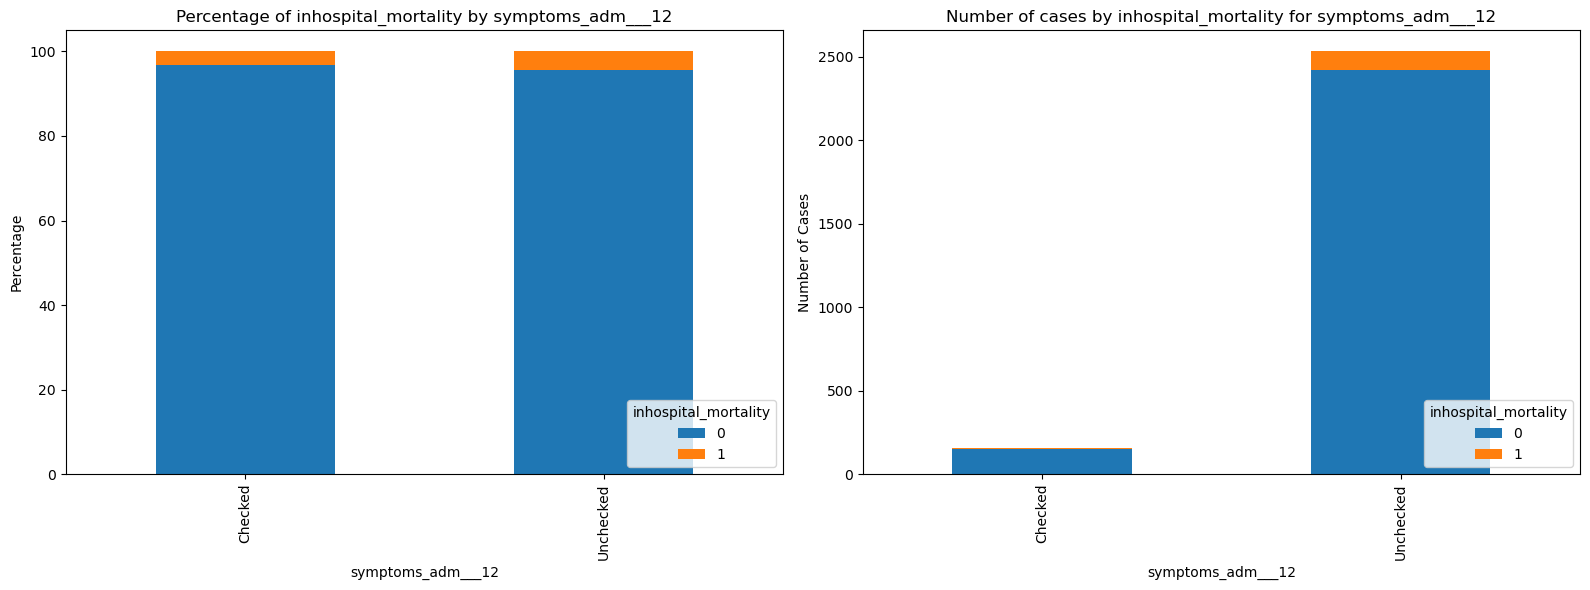

Plotting for column: symptoms_adm___13


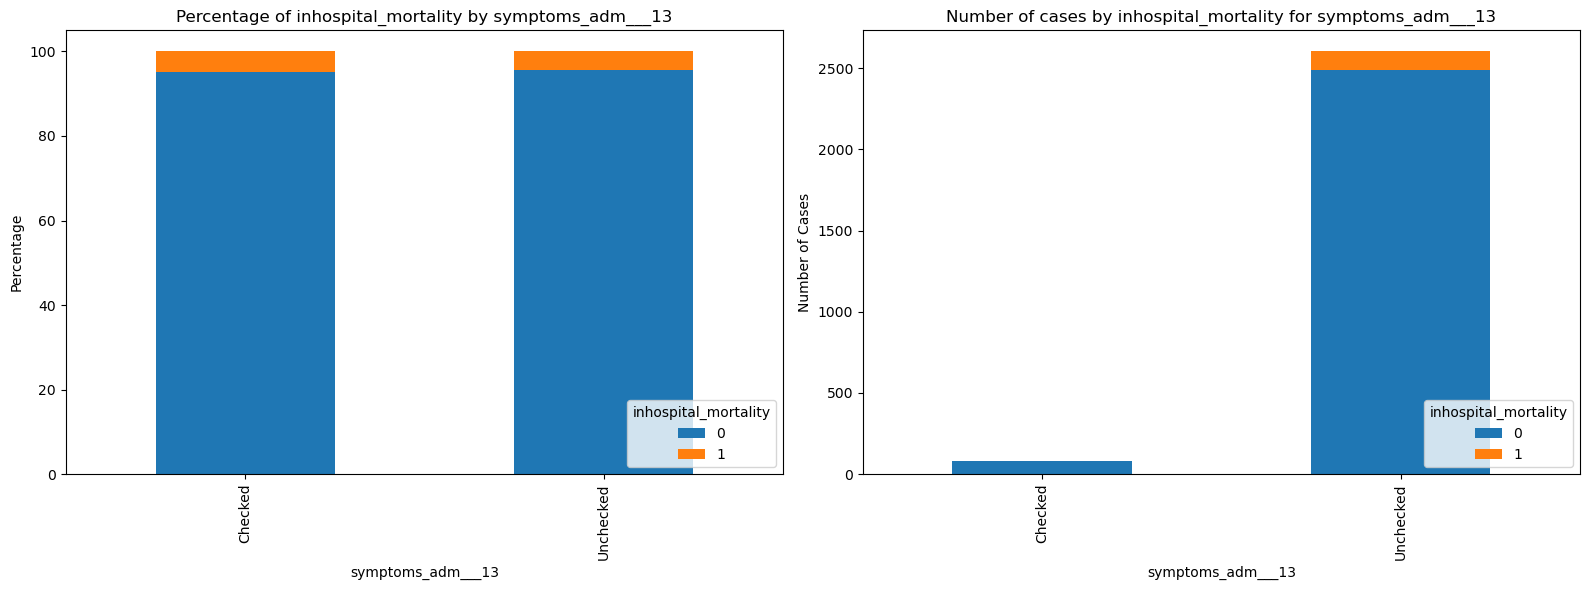

Plotting for column: symptoms_adm___14


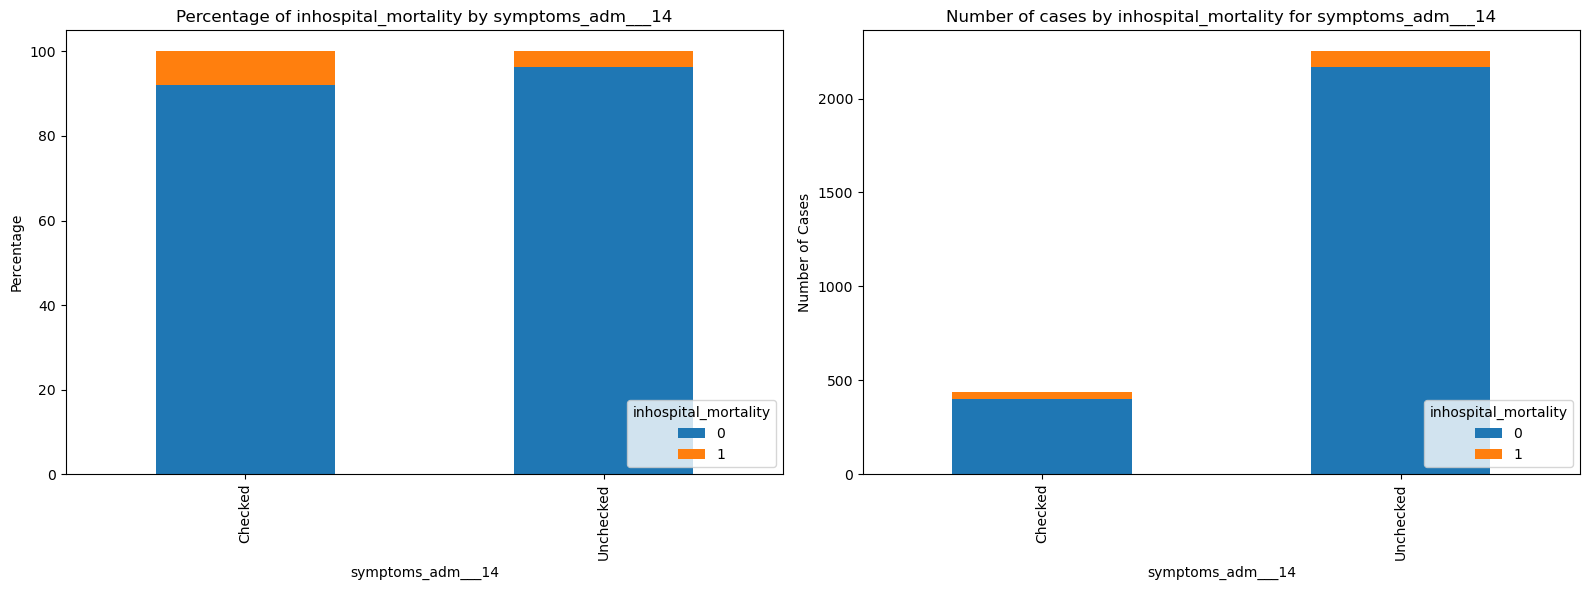

Plotting for column: symptoms_adm___15


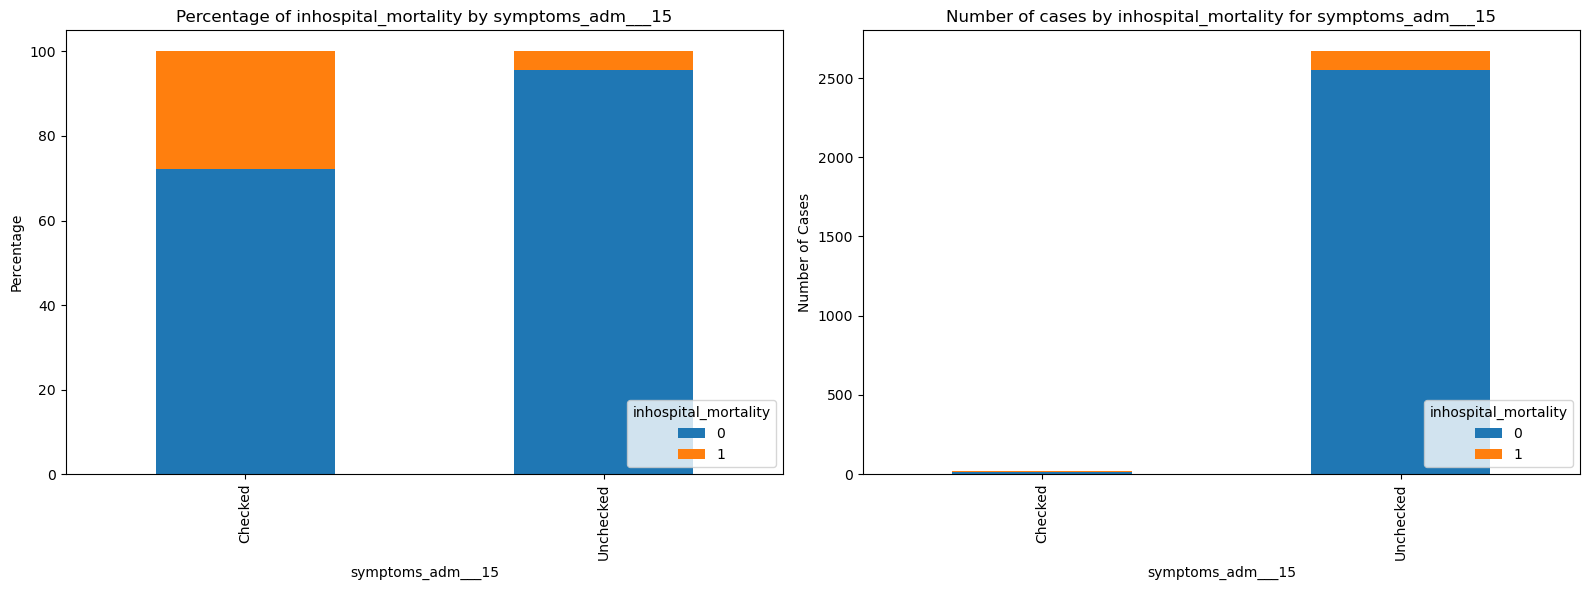

Plotting for column: symptoms_adm___16


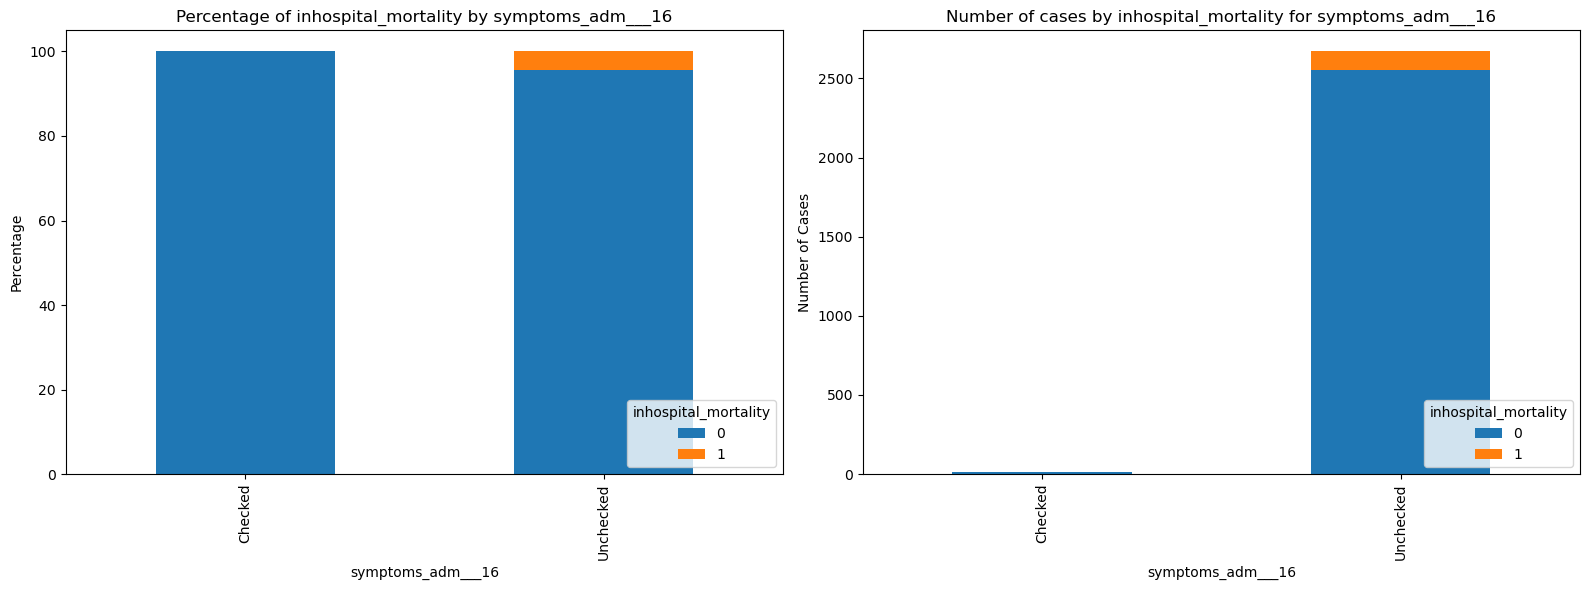

Plotting for column: symptoms_adm___17


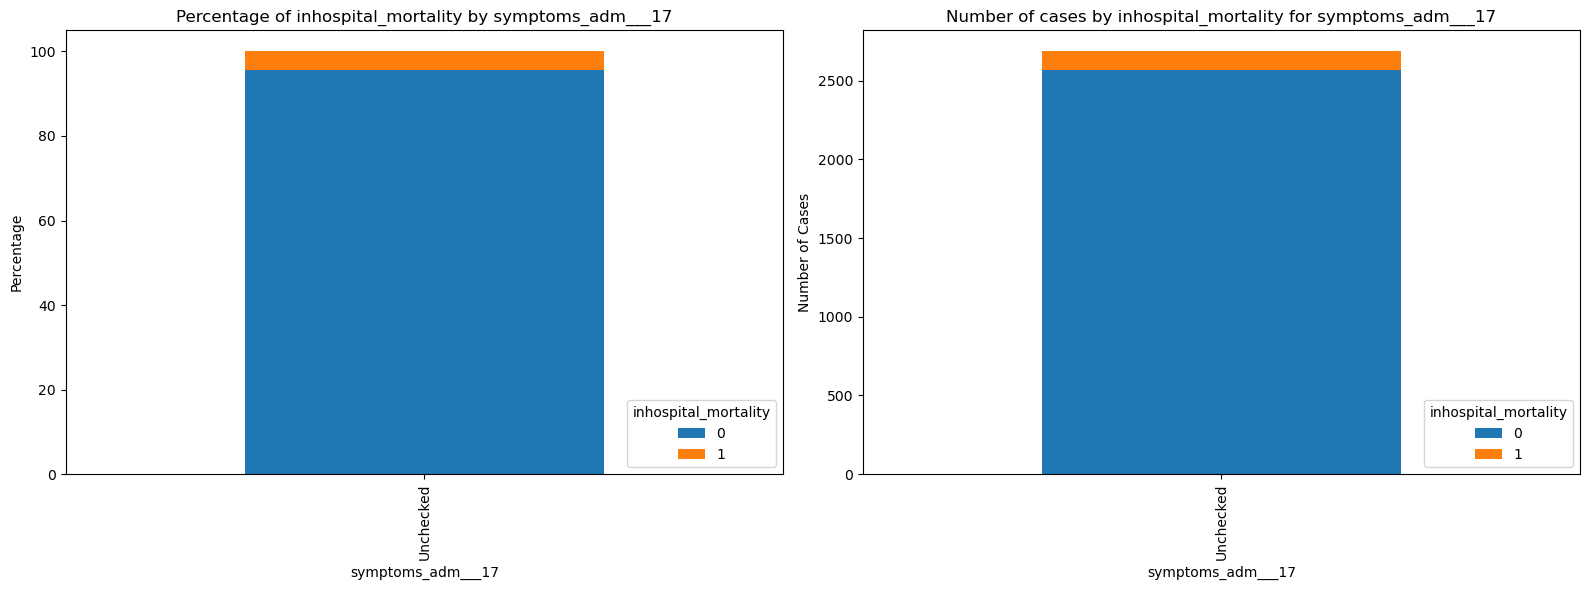

Plotting for column: symptoms_adm___18


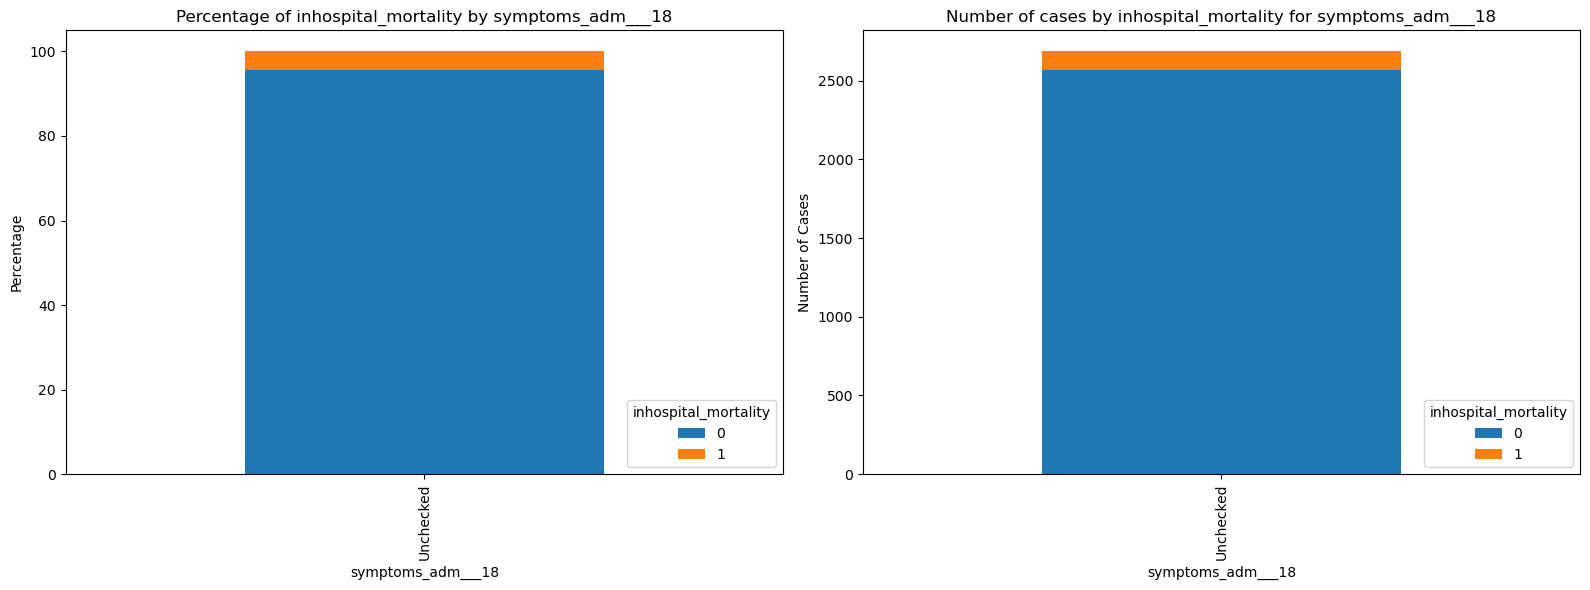

Plotting for column: comorbidity_adm___1


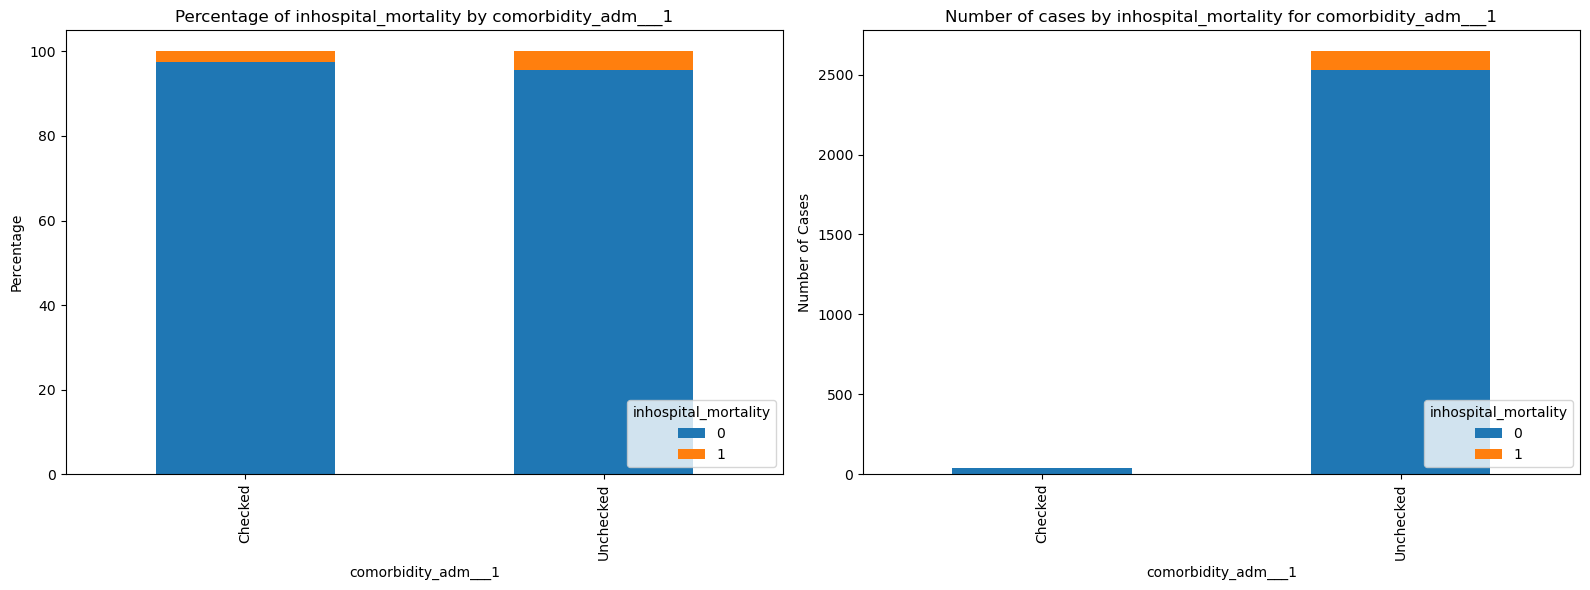

Plotting for column: comorbidity_adm___2


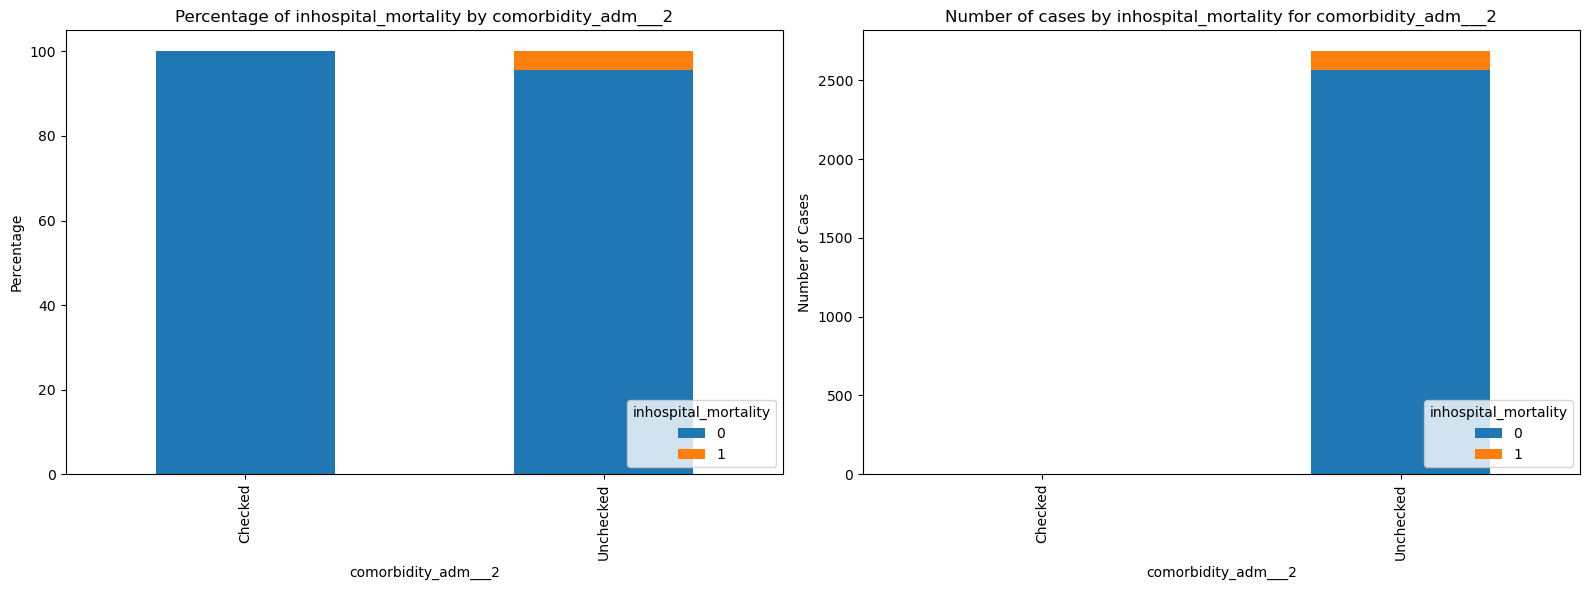

Plotting for column: comorbidity_adm___3


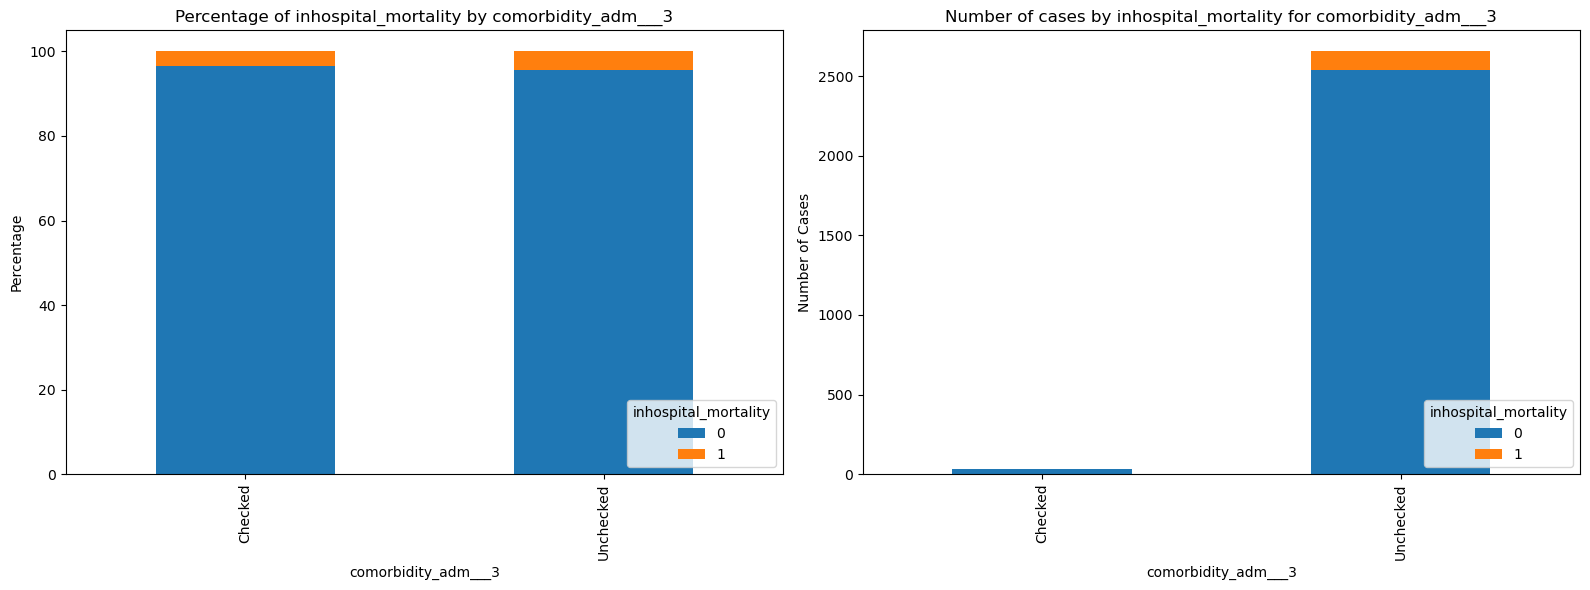

Plotting for column: comorbidity_adm___4


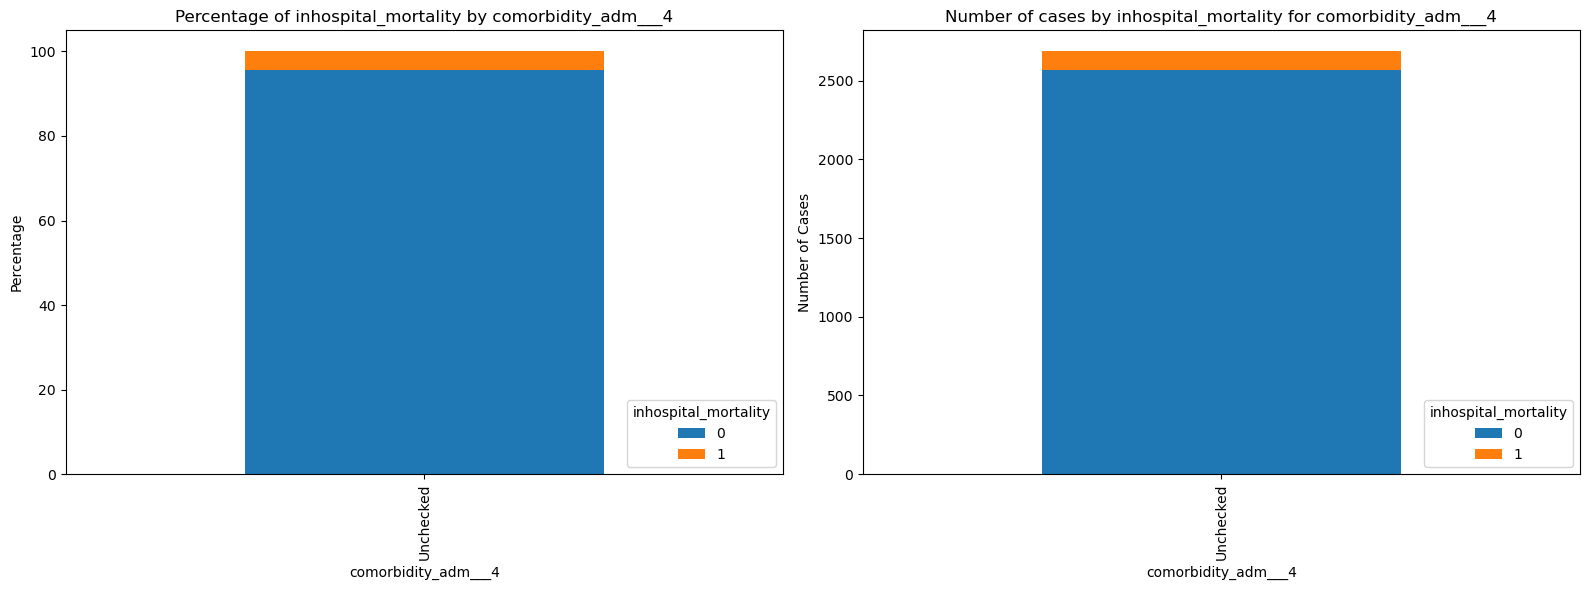

Plotting for column: comorbidity_adm___5


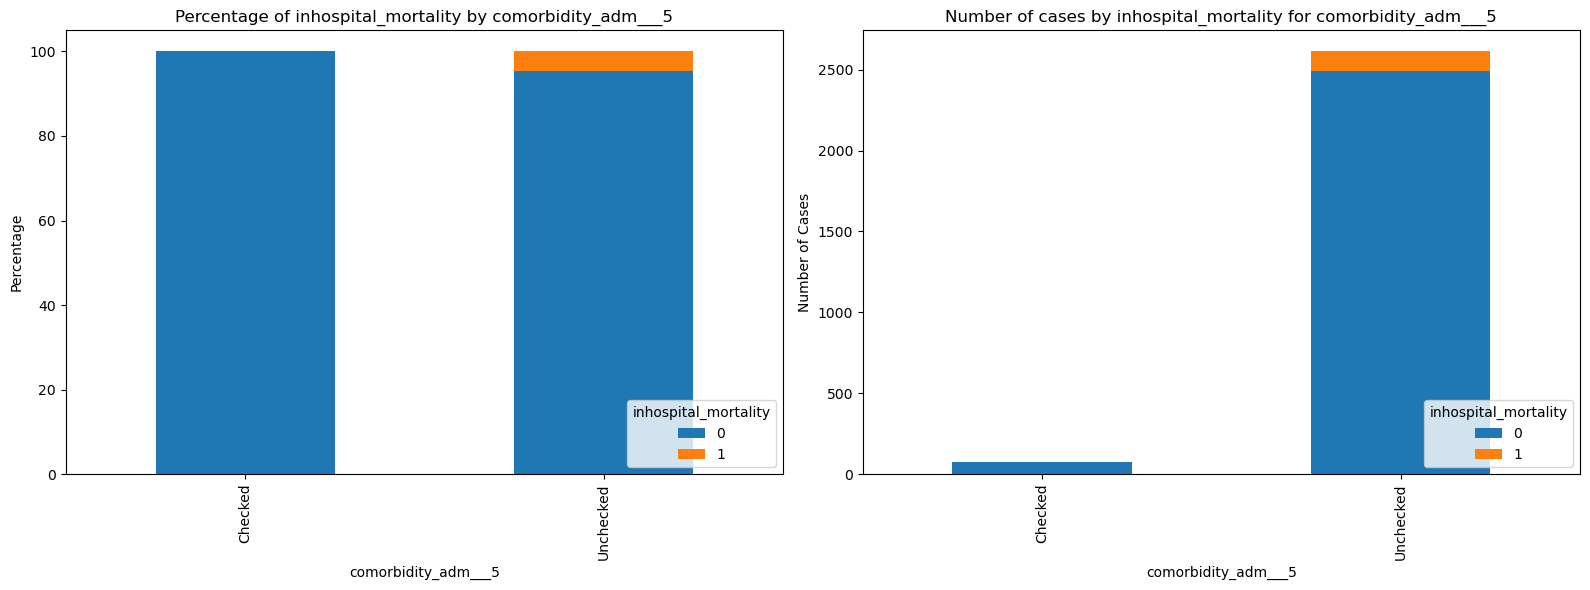

Plotting for column: comorbidity_adm___6


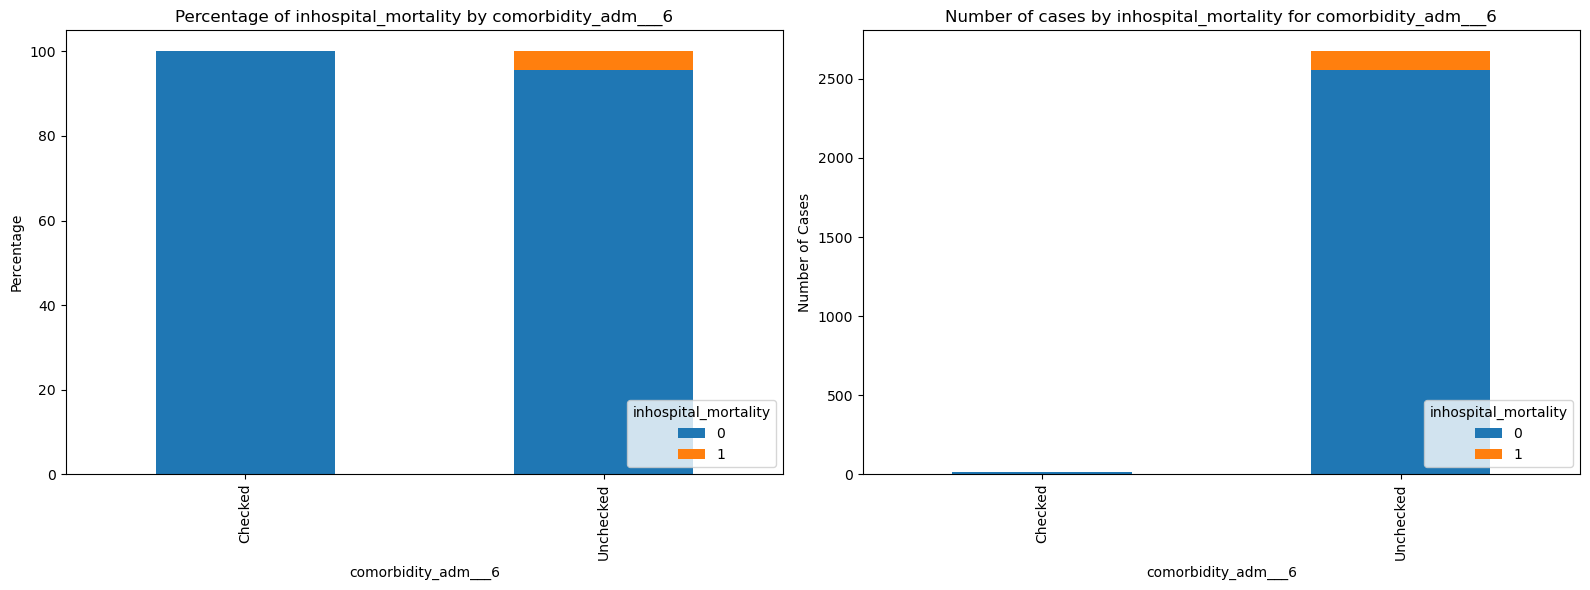

Plotting for column: comorbidity_adm___7


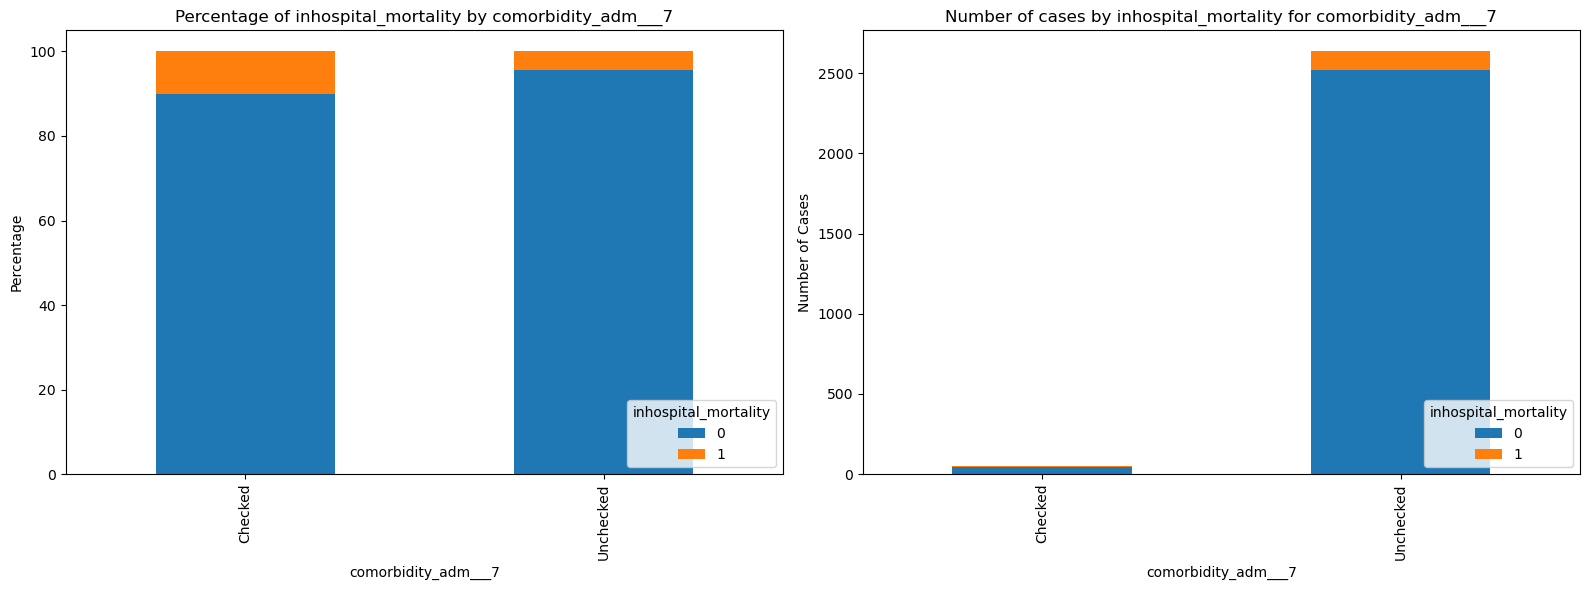

Plotting for column: comorbidity_adm___8


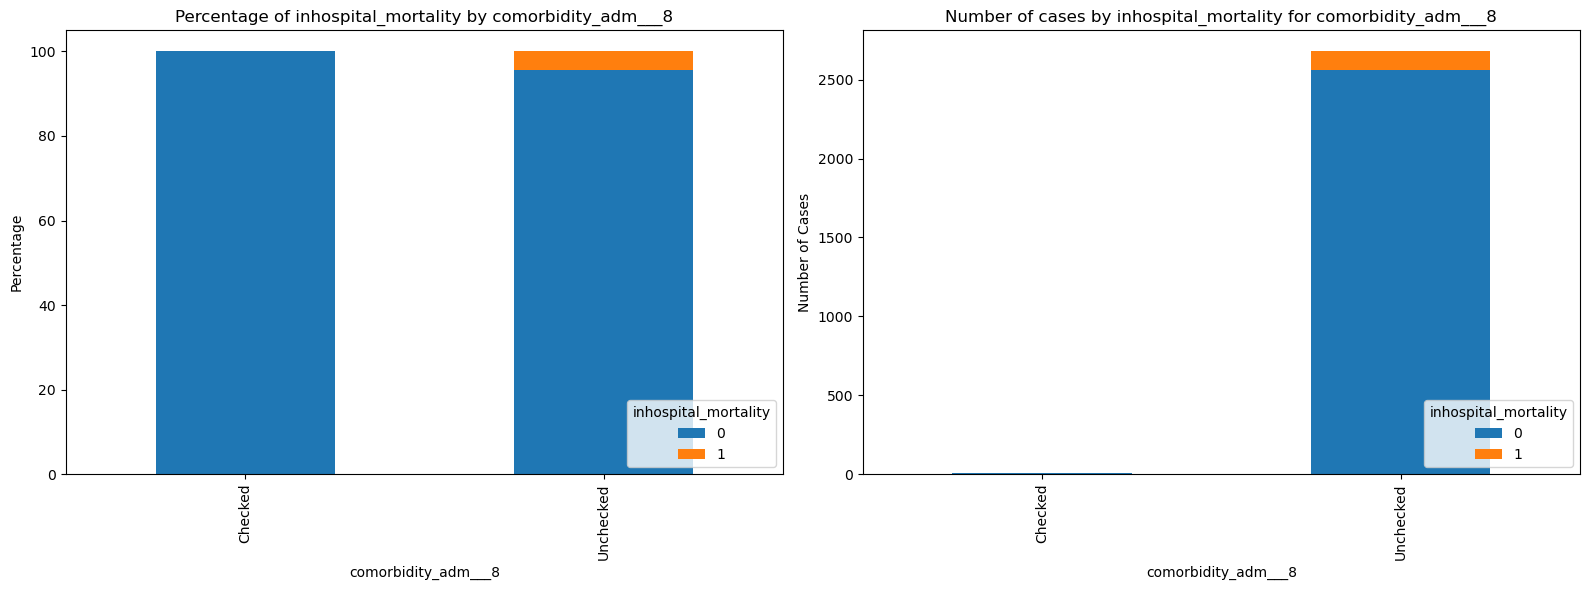

Plotting for column: comorbidity_adm___9


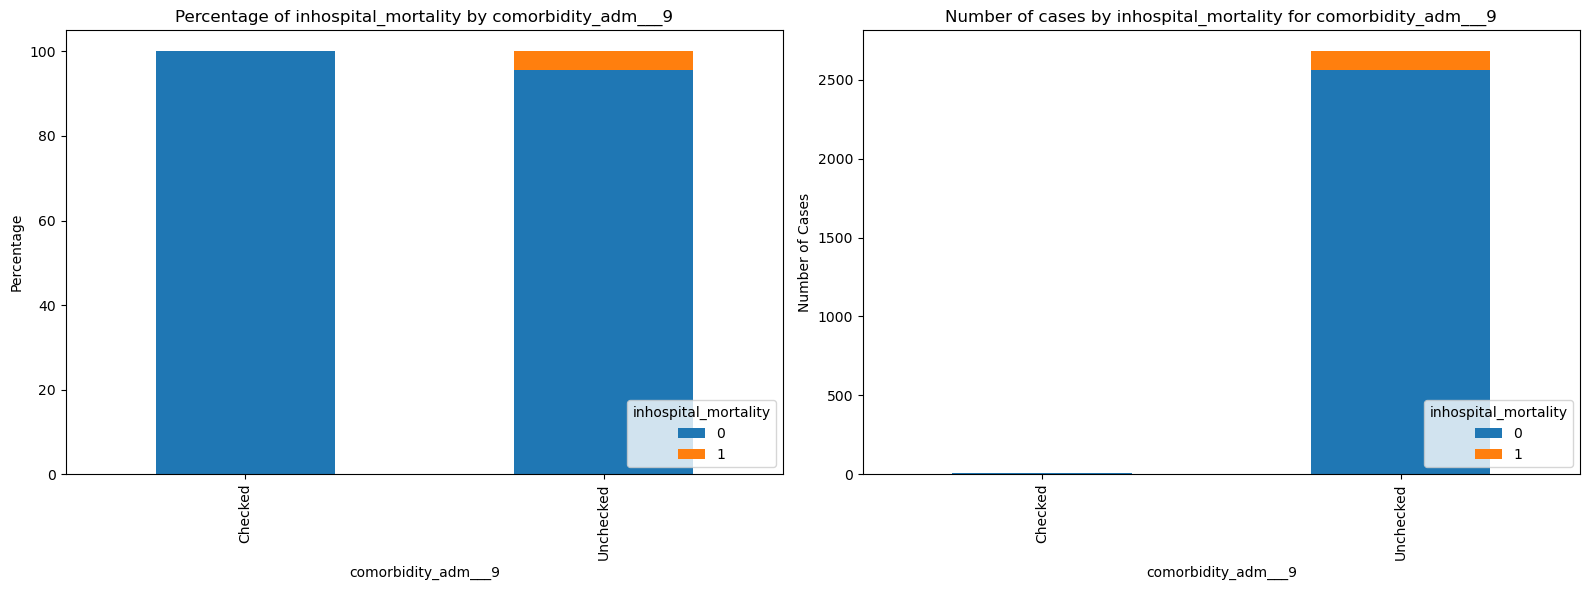

Plotting for column: comorbidity_adm___10


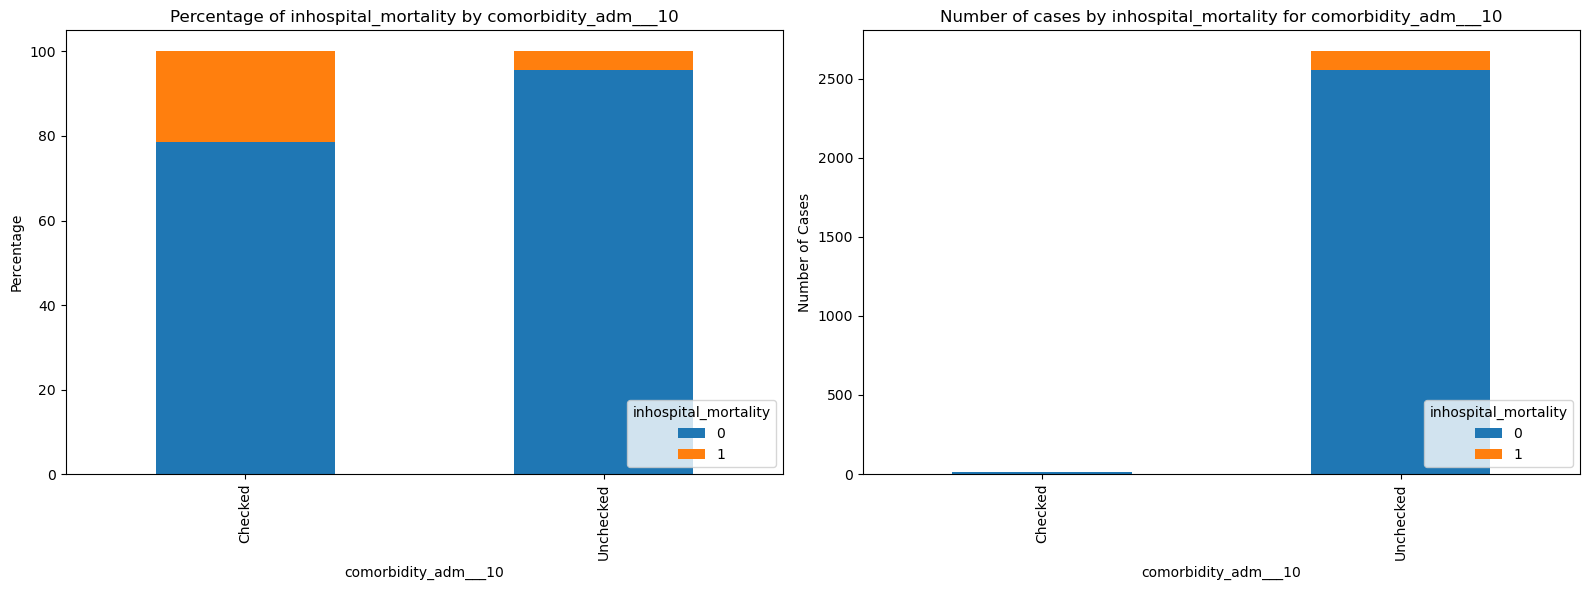

Plotting for column: comorbidity_adm___11


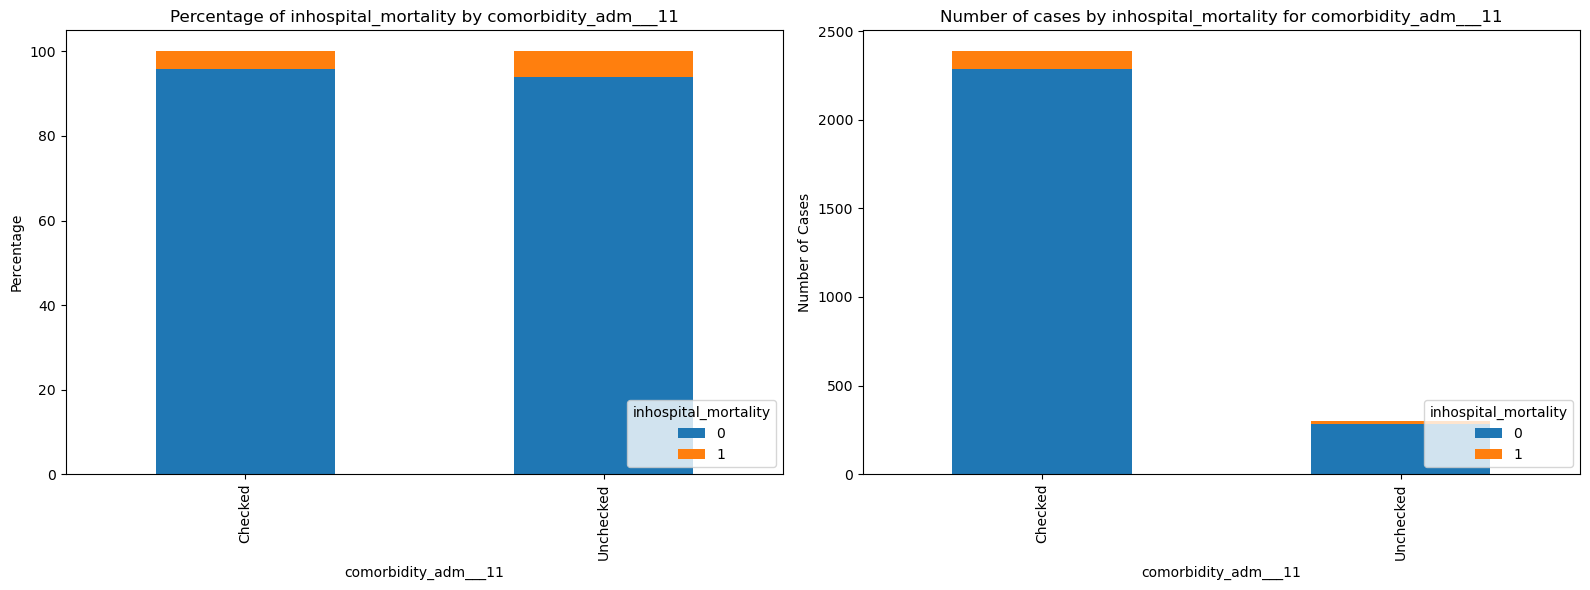

Plotting for column: comorbidity_adm___12


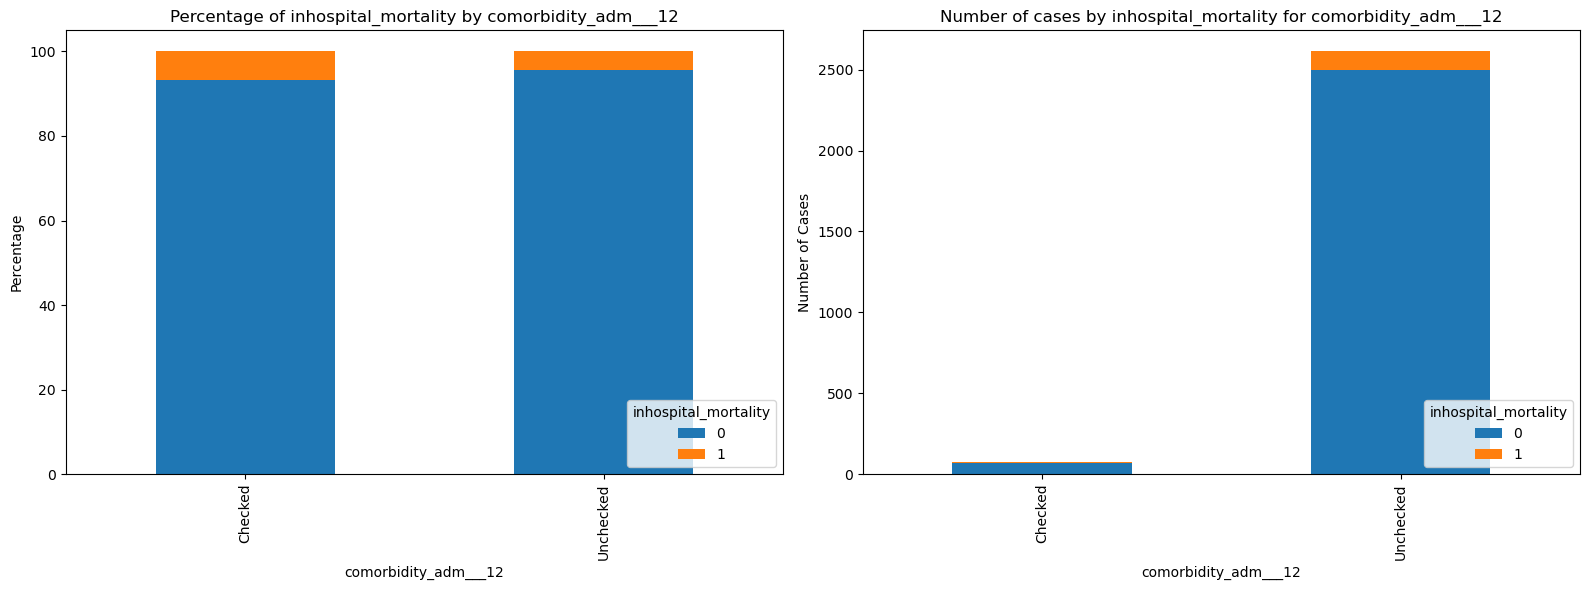

Plotting for column: priorhosp_adm


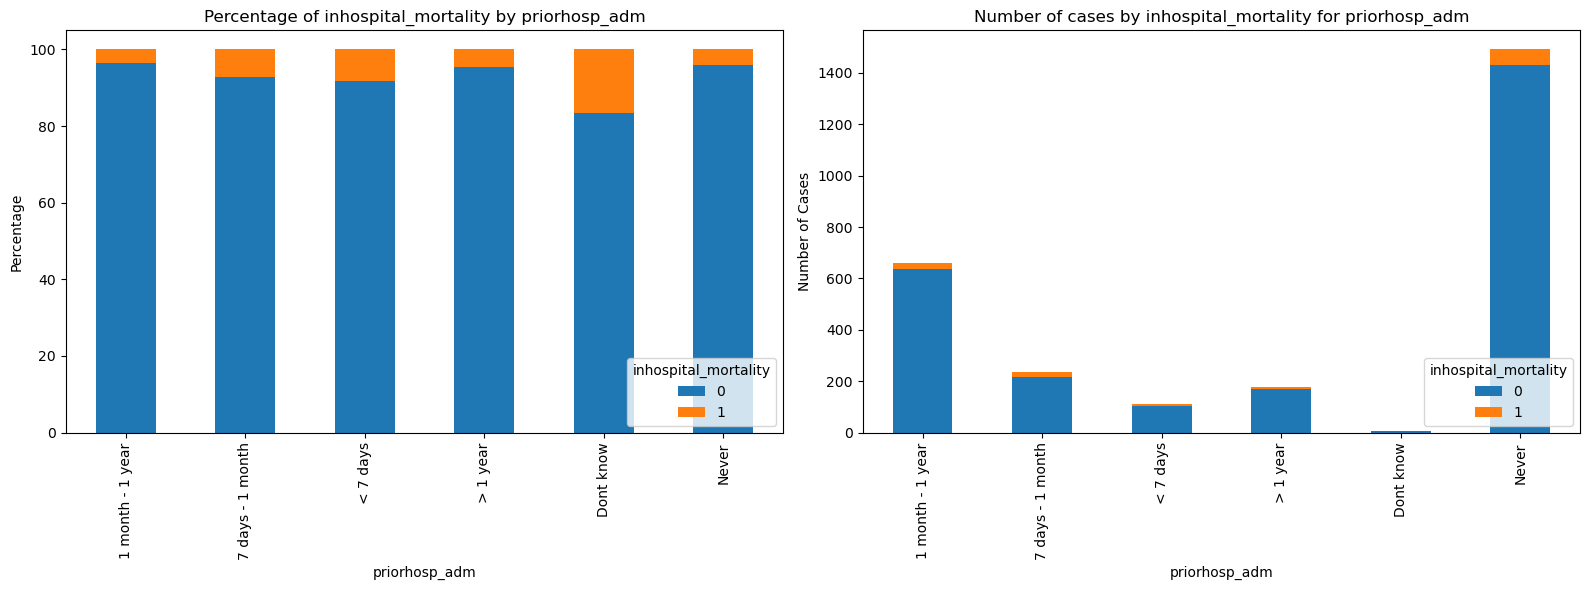

Plotting for column: prioryearwheeze_adm


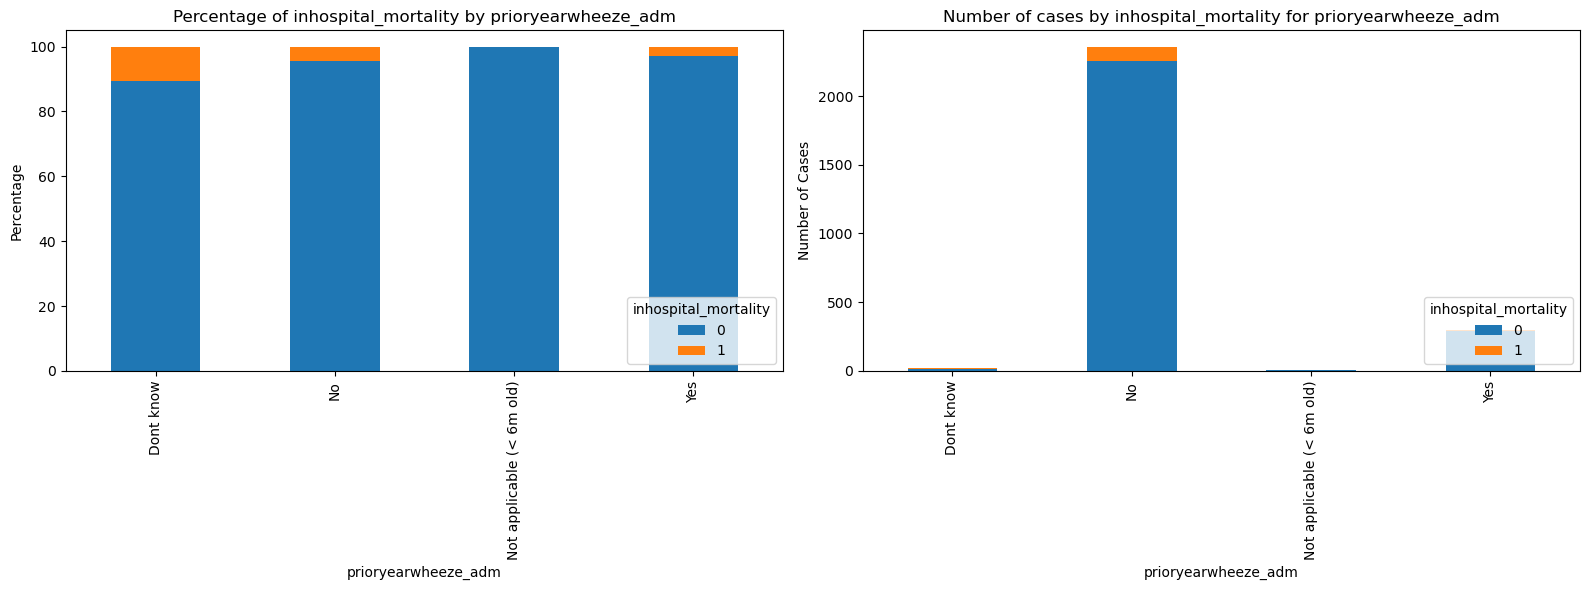

Plotting for column: prioryearcough_adm


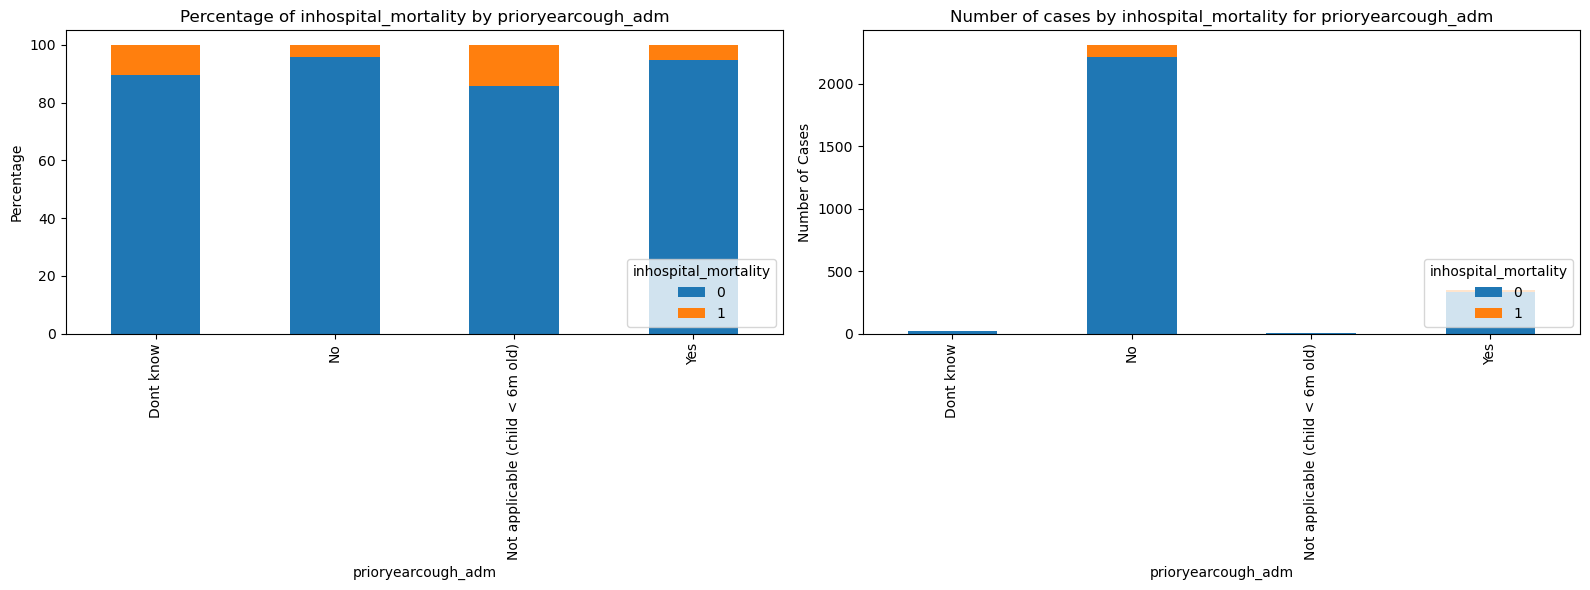

Plotting for column: diarrheaoften_adm


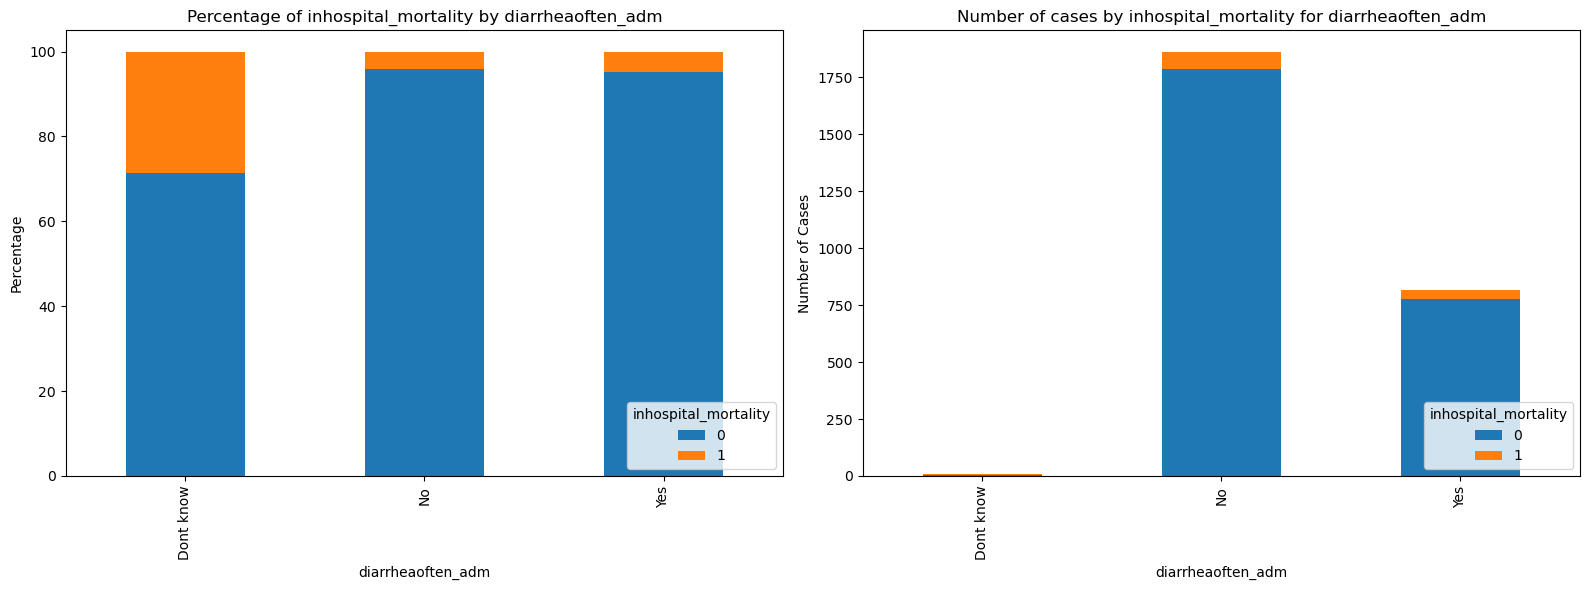

Plotting for column: tbcontact_adm


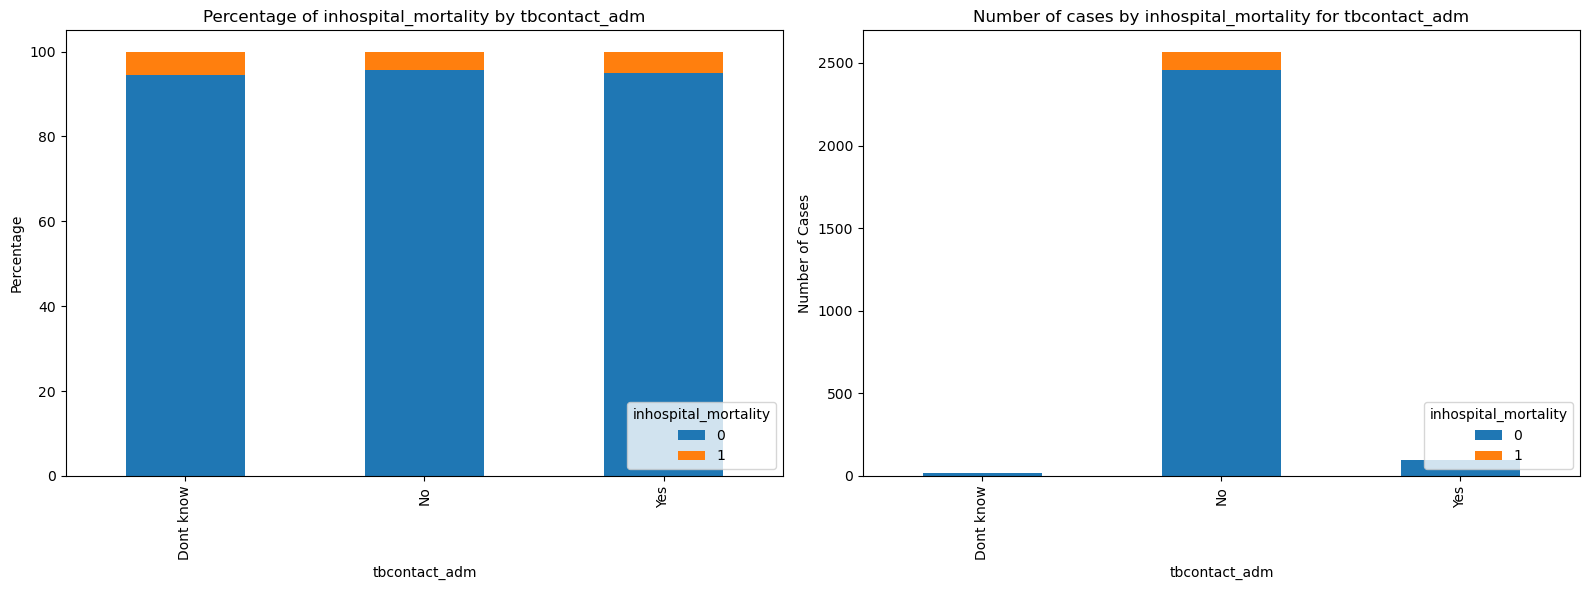

Plotting for column: feedingstatus_adm


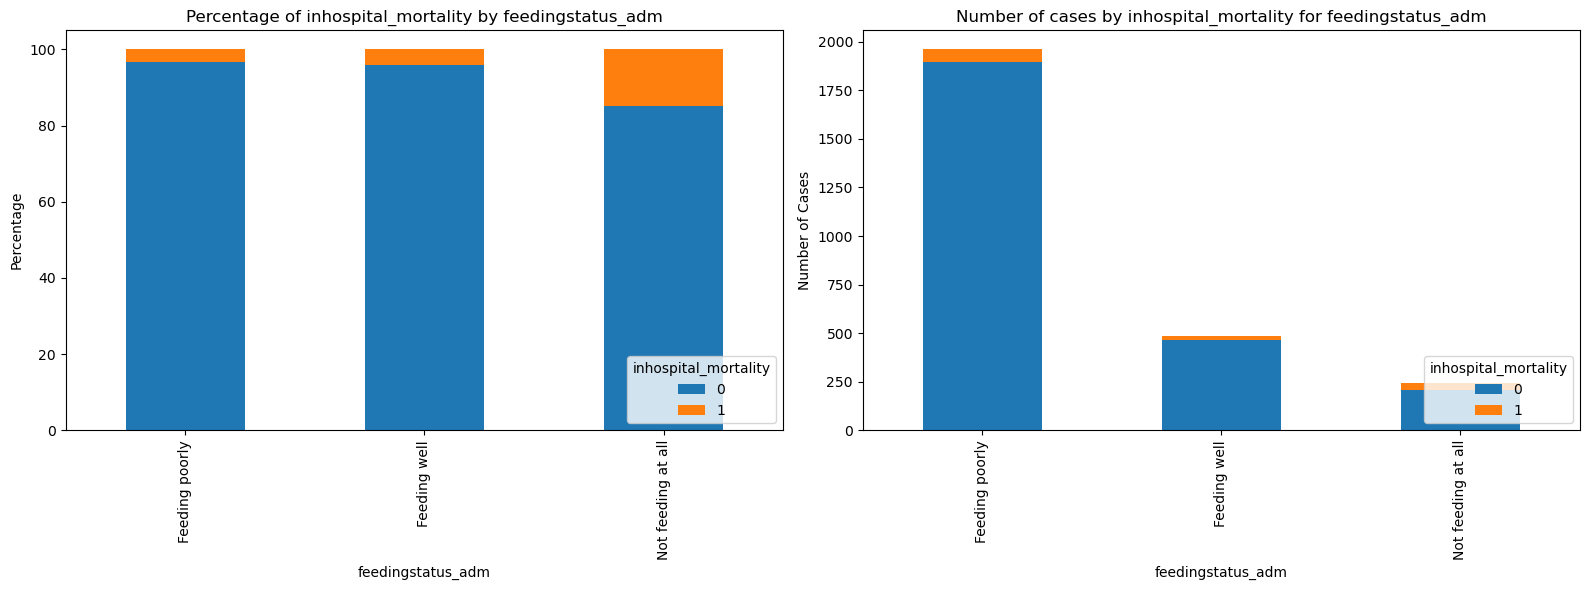

Plotting for column: exclbreastfed_adm


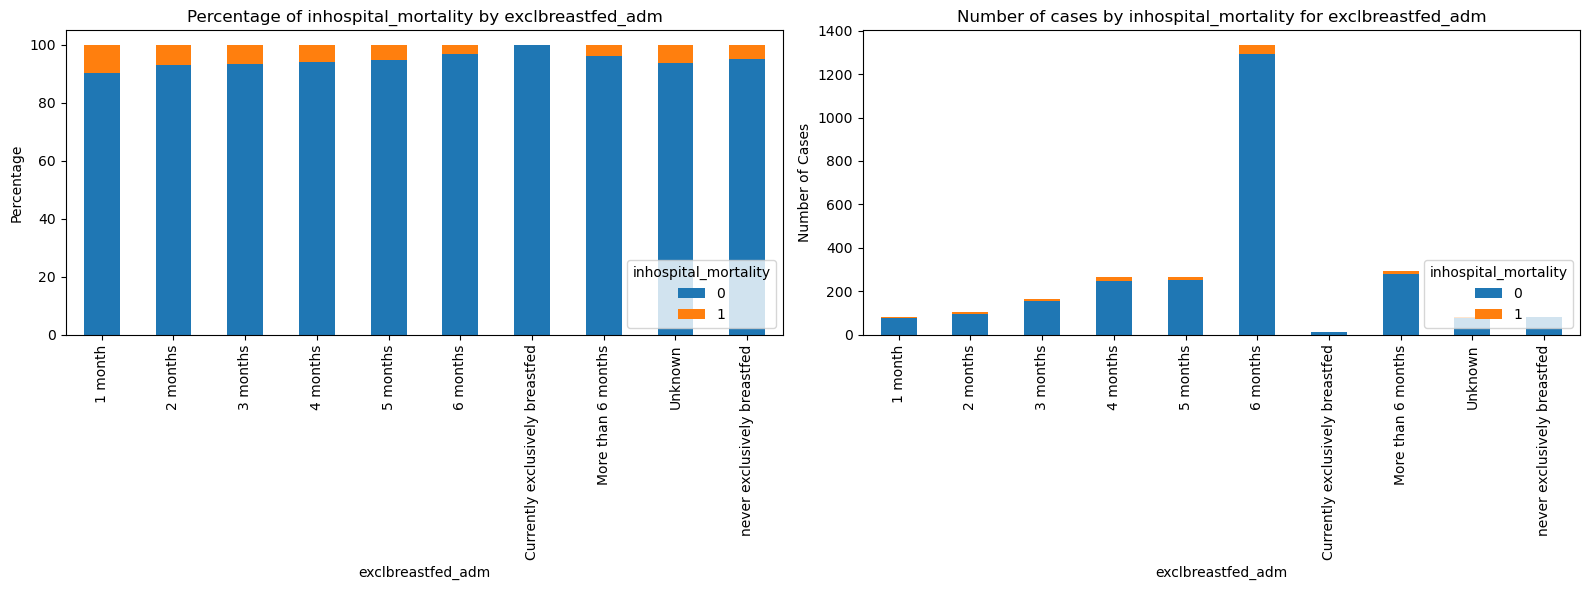

Plotting for column: nonexclbreastfed_adm


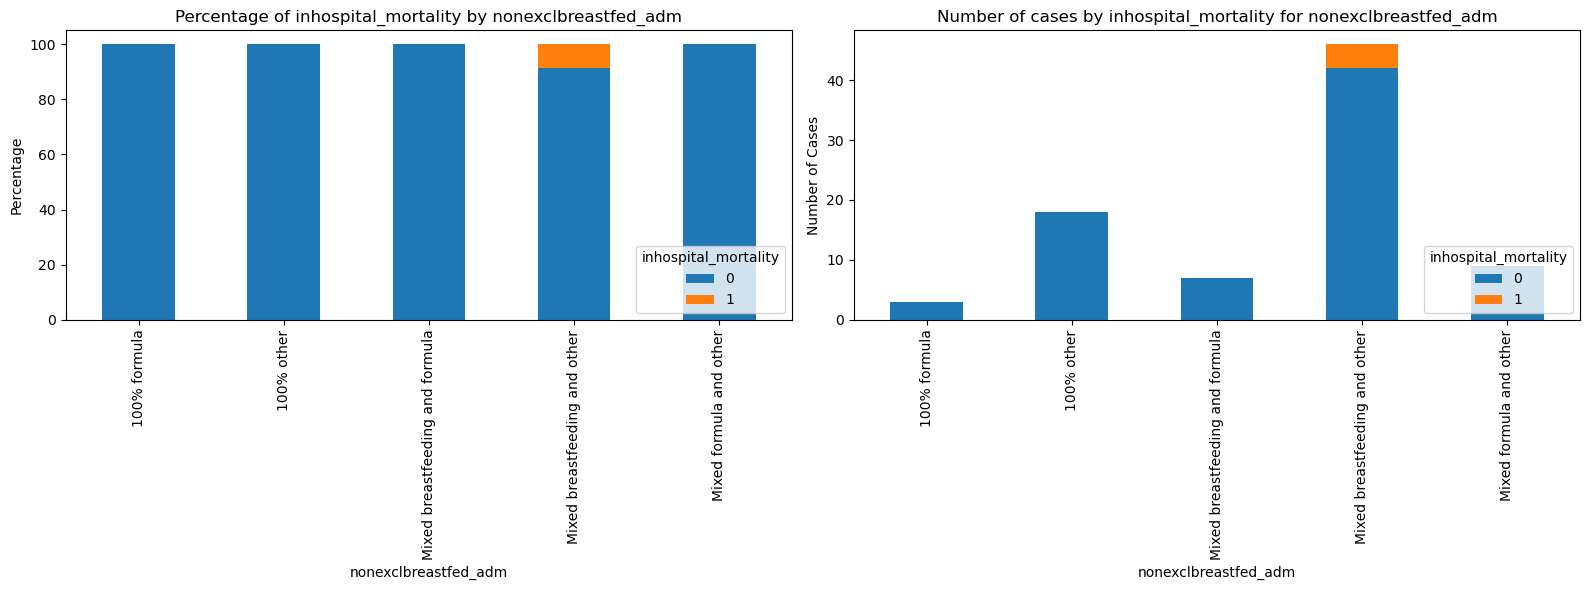

Plotting for column: totalbreastfed_adm


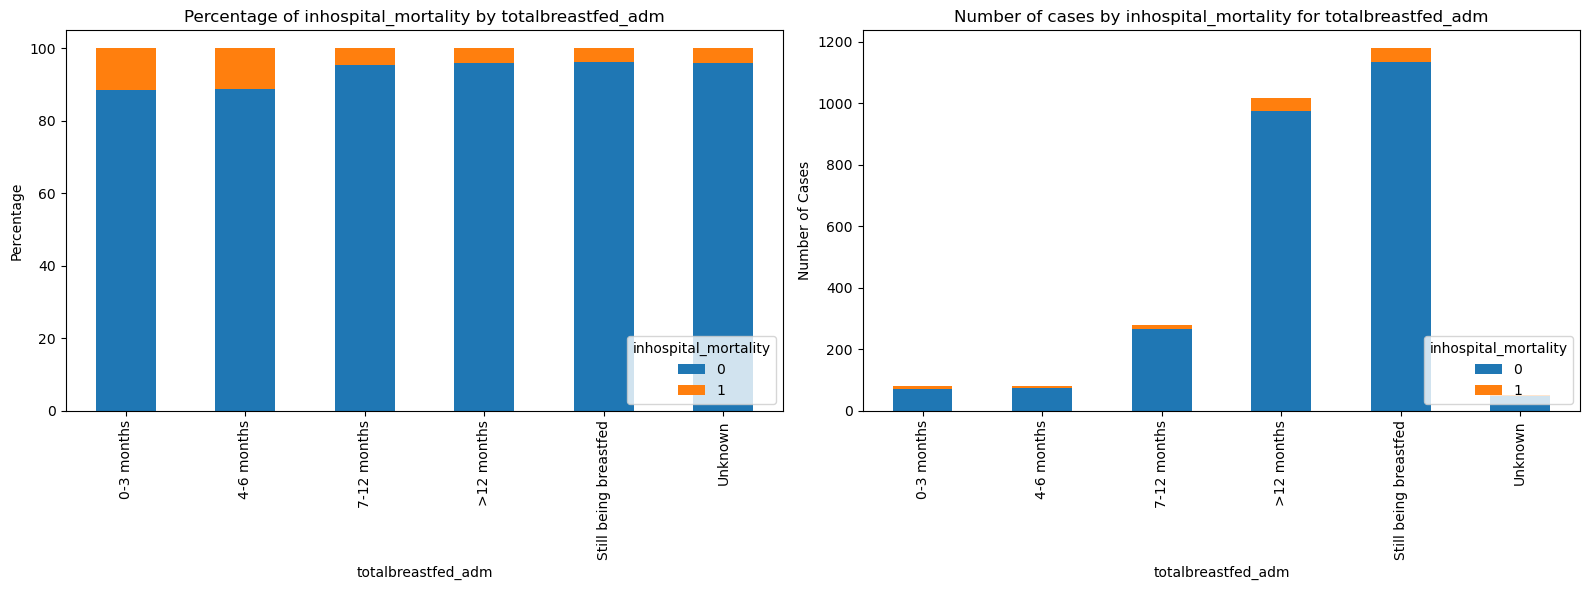

Plotting for column: deliveryloc_adm


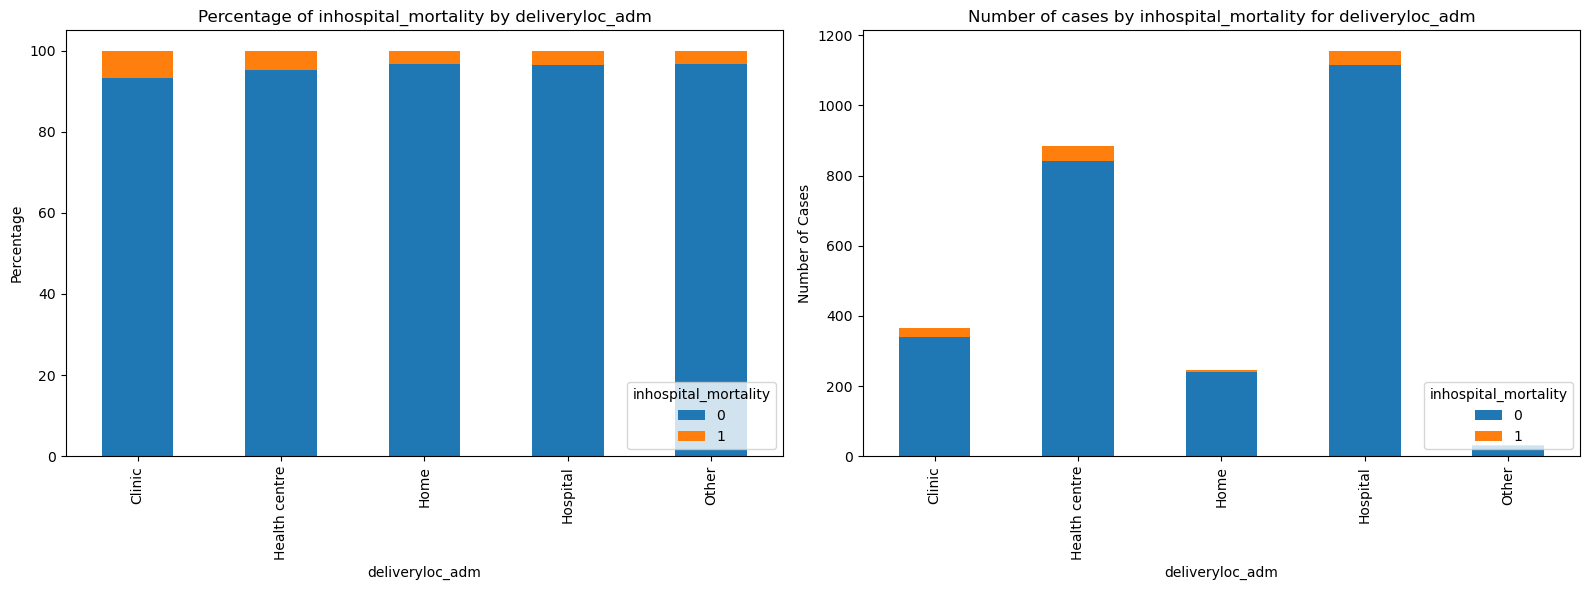

Plotting for column: birthattend_adm


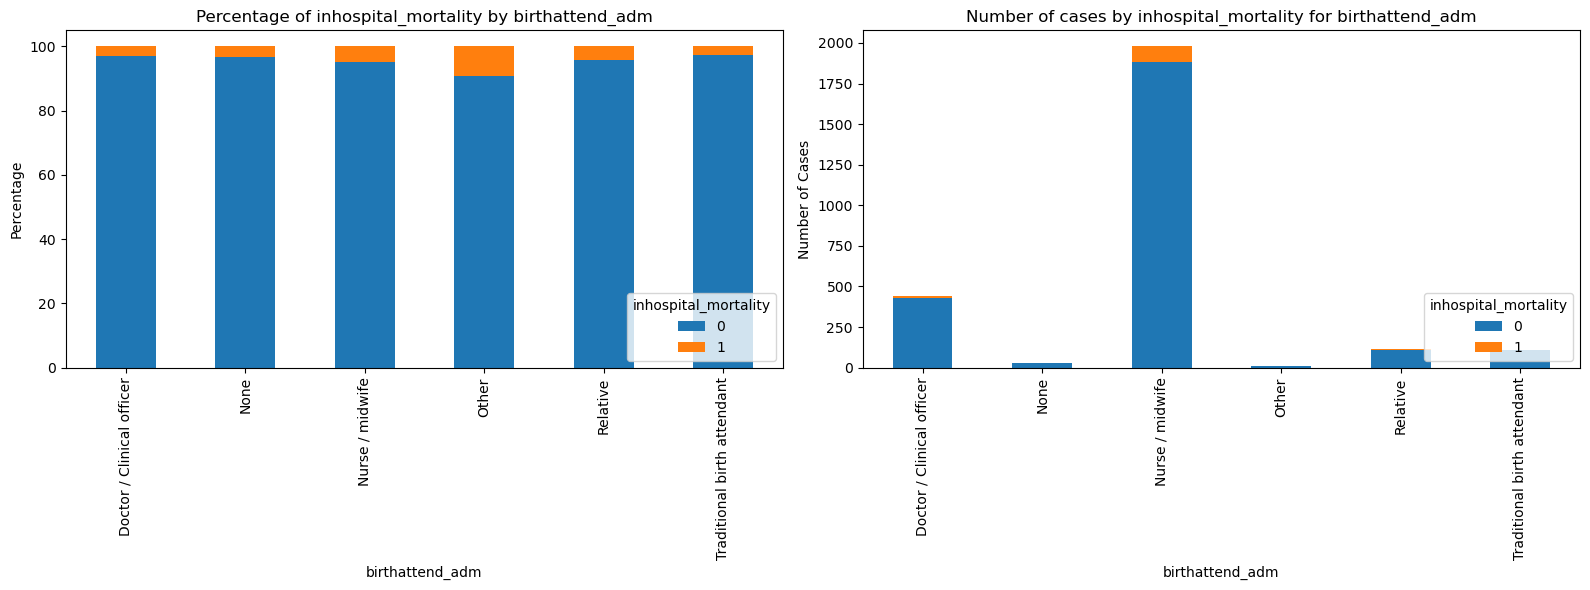

Plotting for column: duedateknown_adm


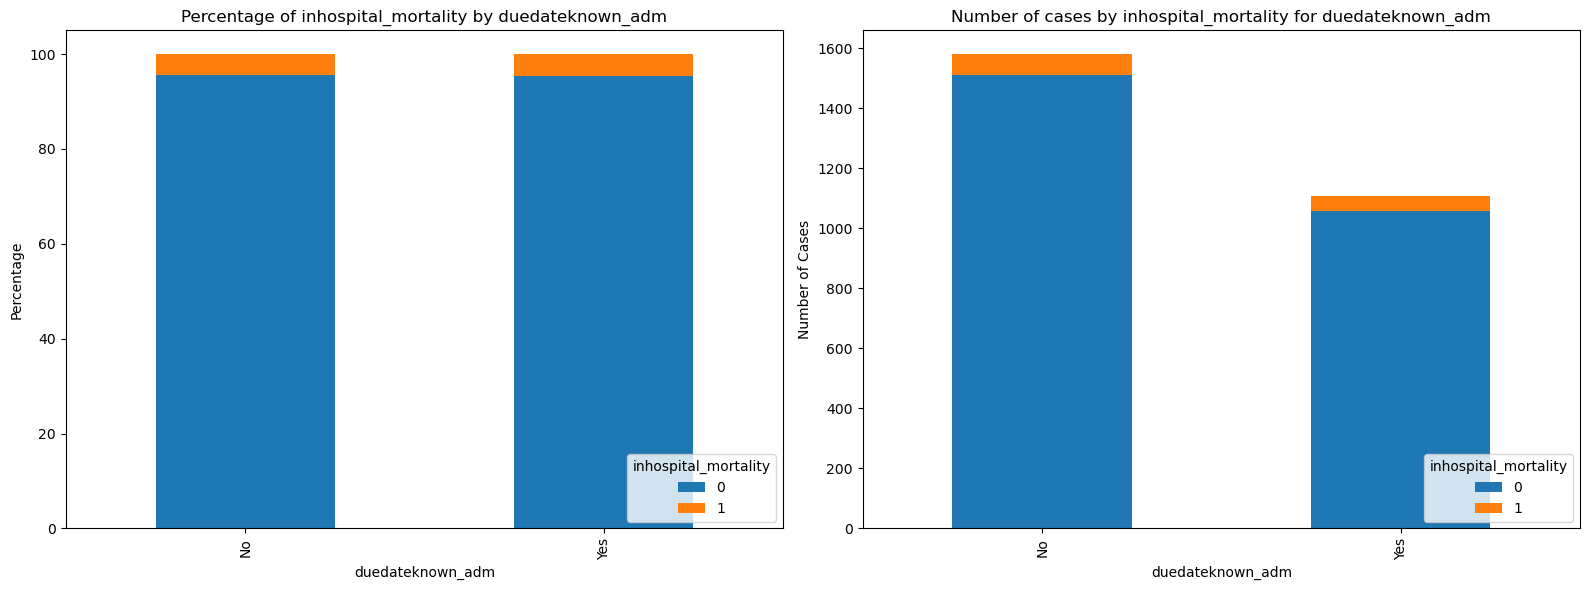

Plotting for column: birthdetail_adm___1


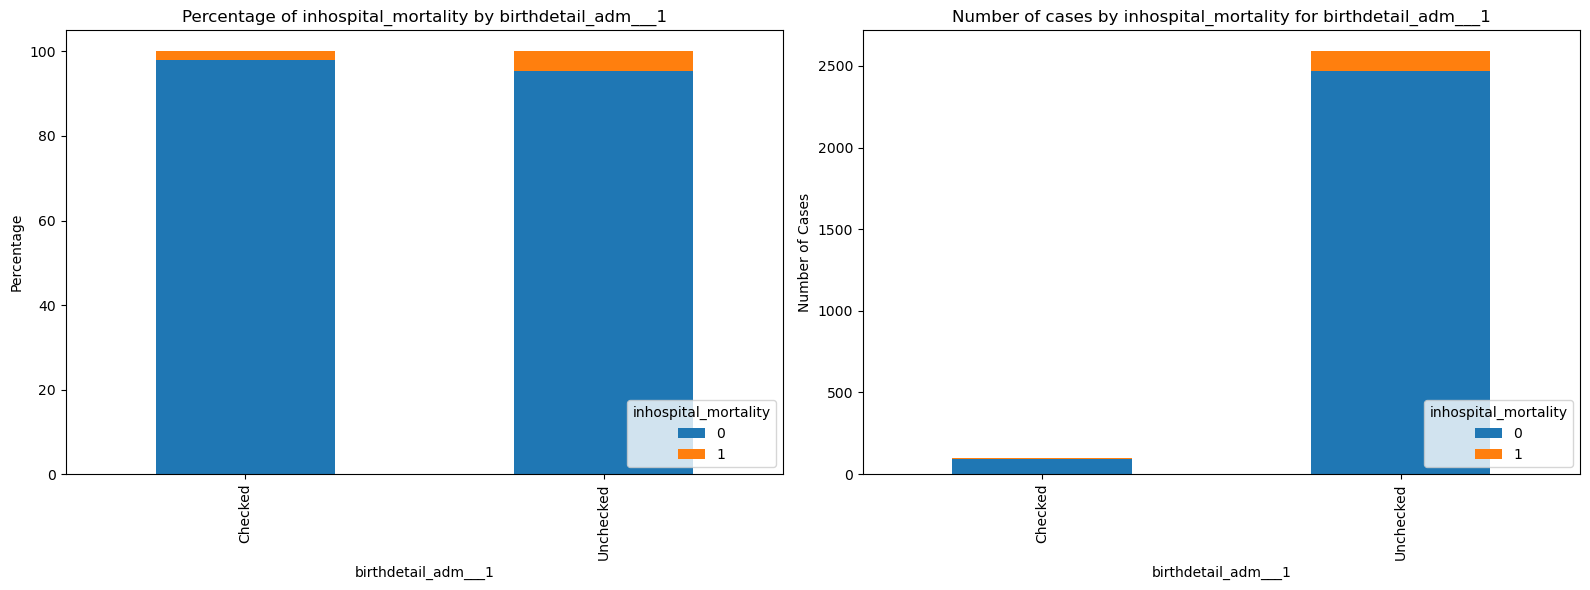

Plotting for column: birthdetail_adm___2


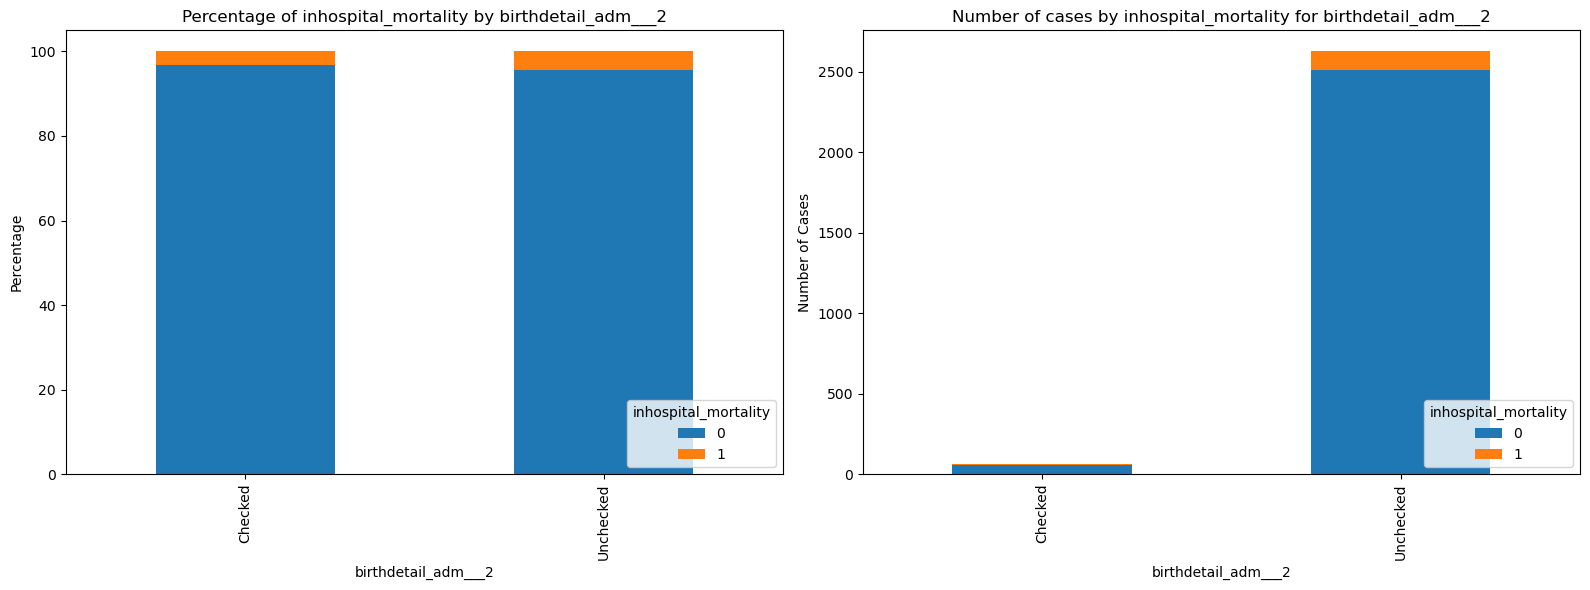

Plotting for column: birthdetail_adm___3


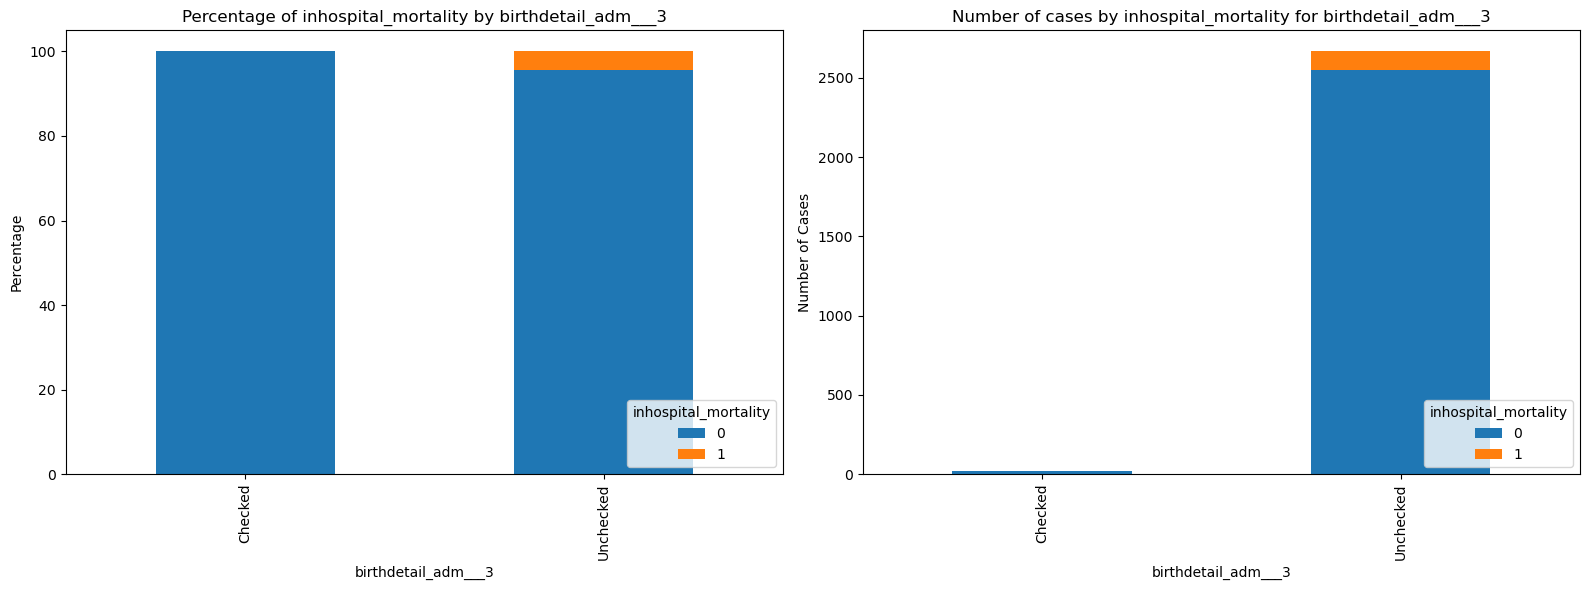

Plotting for column: birthdetail_adm___4


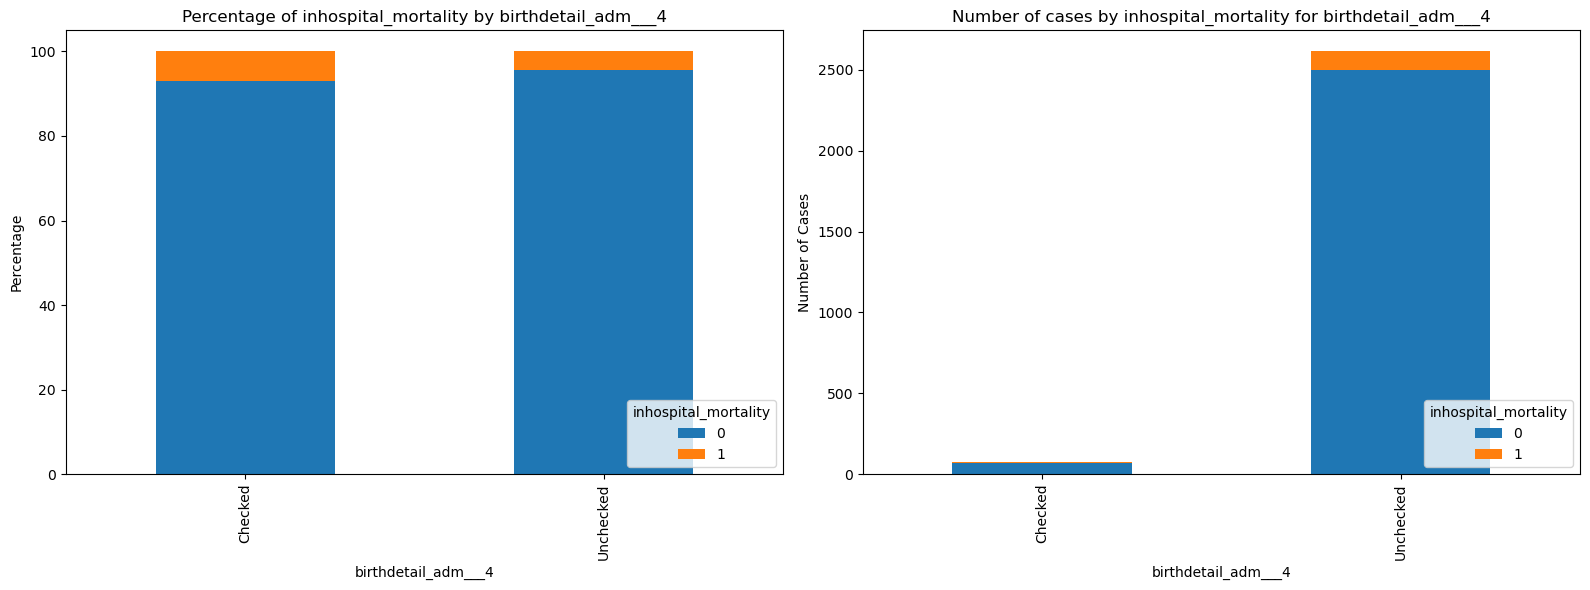

Plotting for column: birthdetail_adm___5


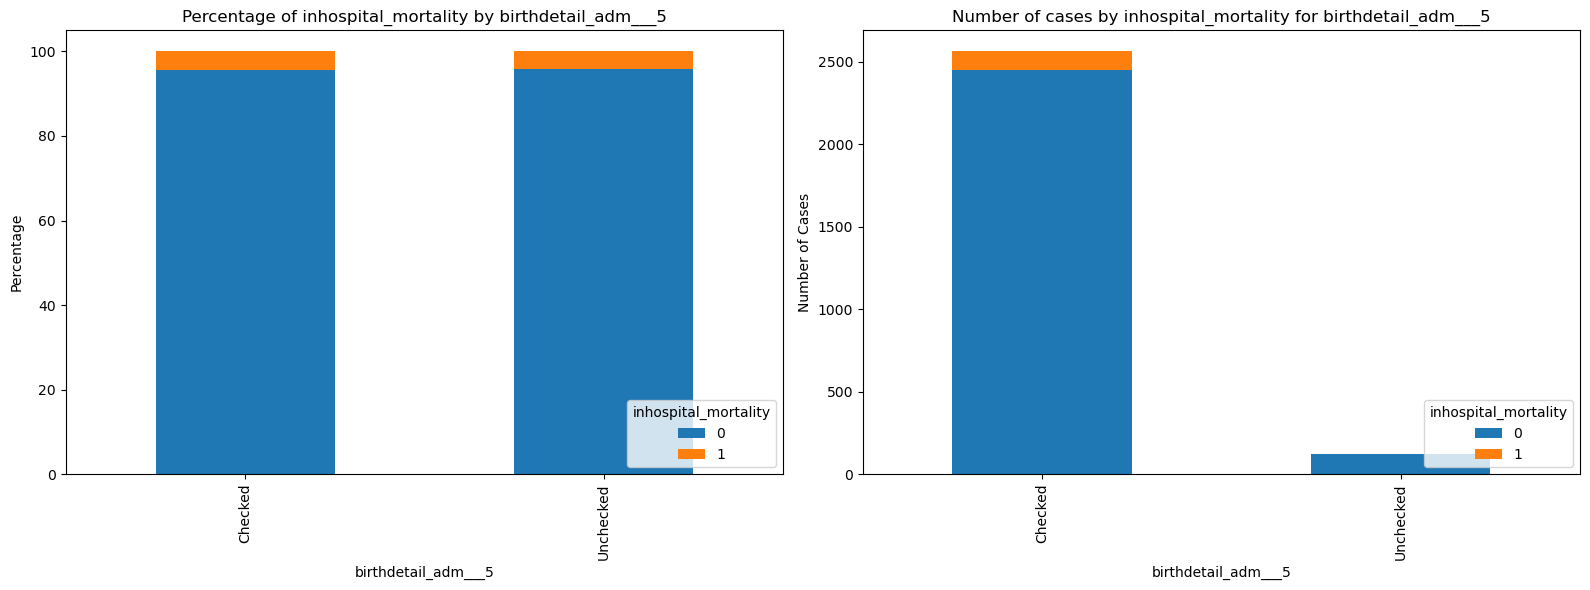

Plotting for column: birthdetail_adm___6


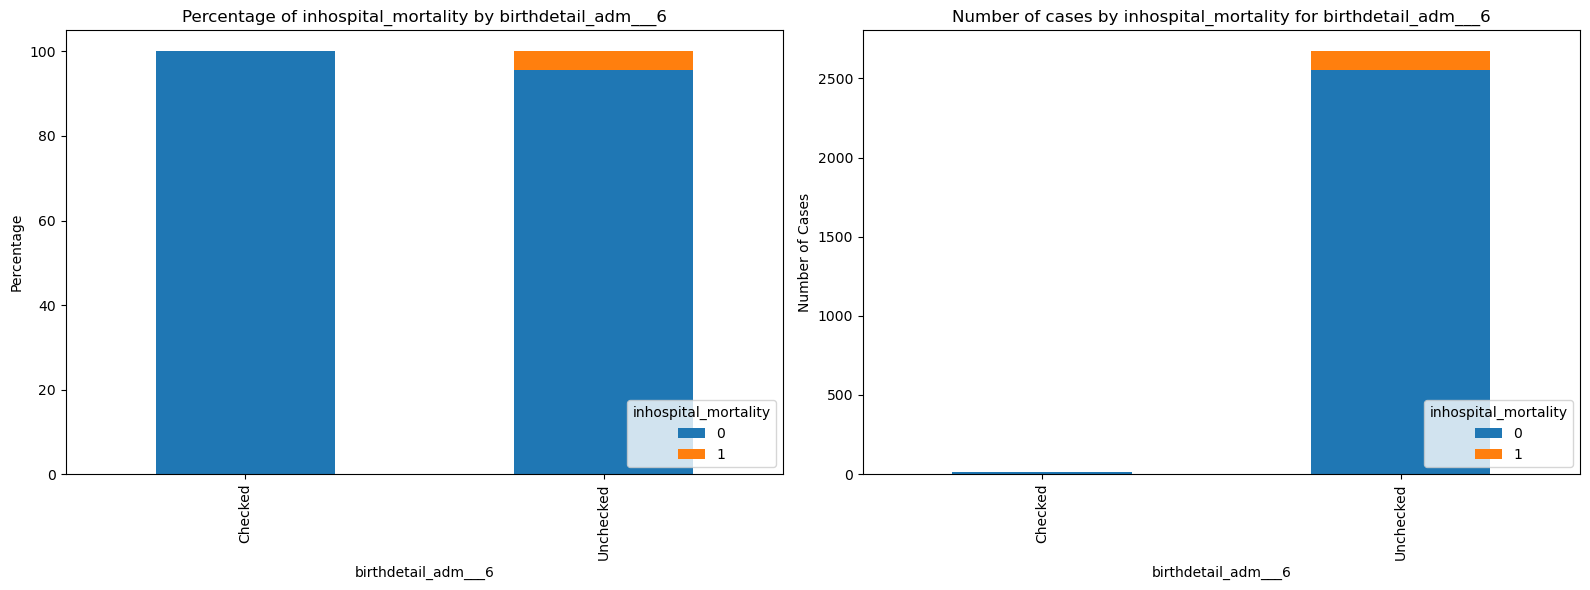

Plotting for column: travelmethod_adm


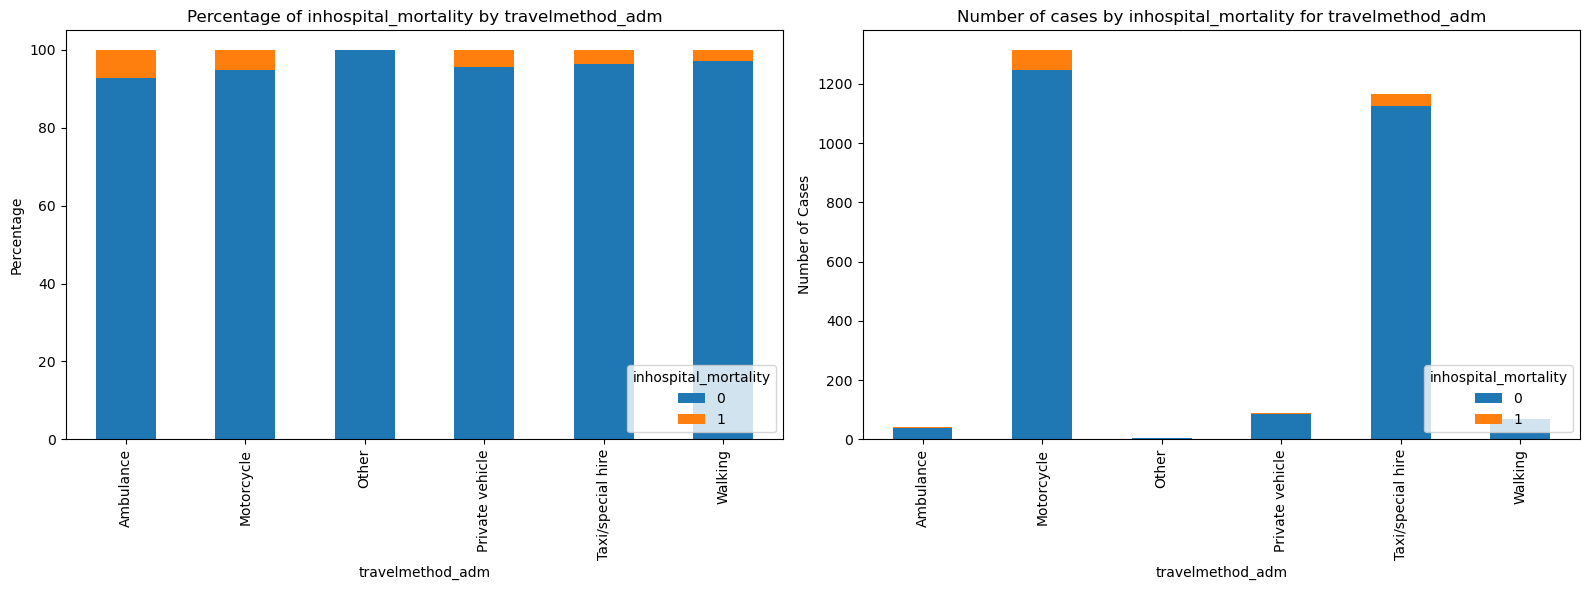

Plotting for column: traveldist_adm


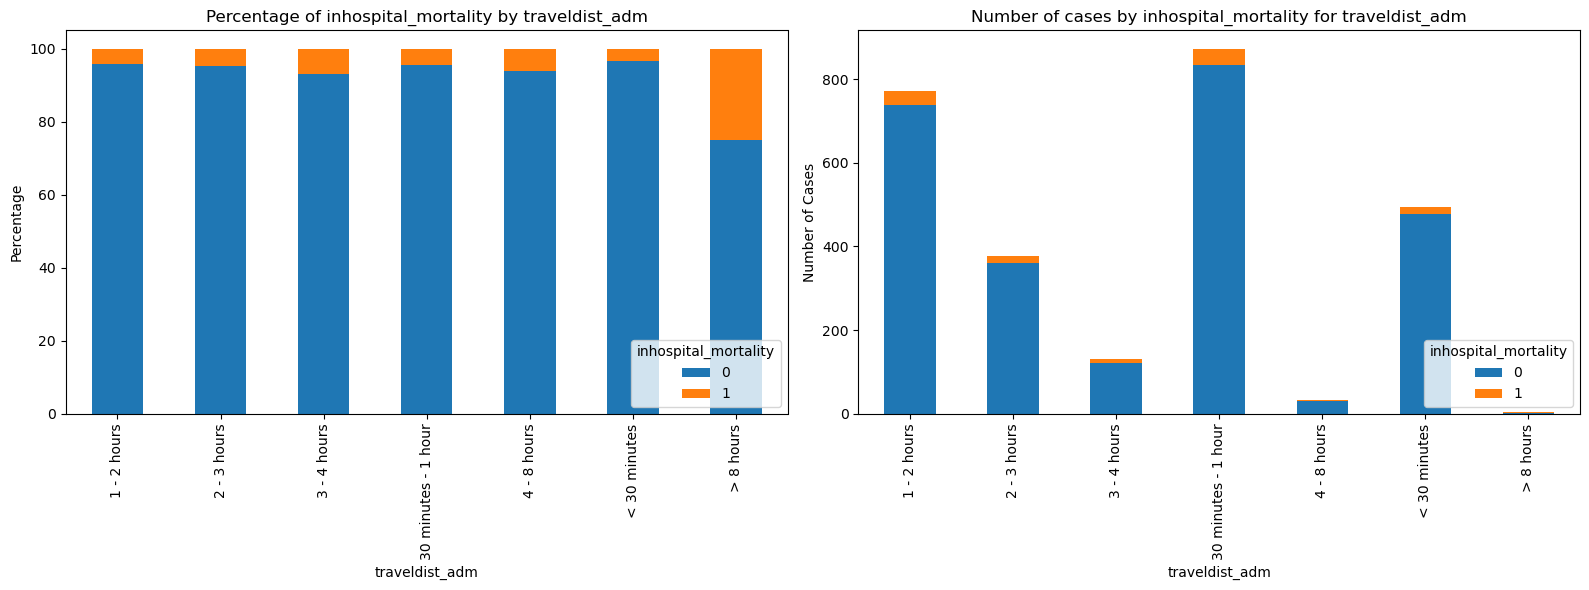

Plotting for column: badhealthduration_adm


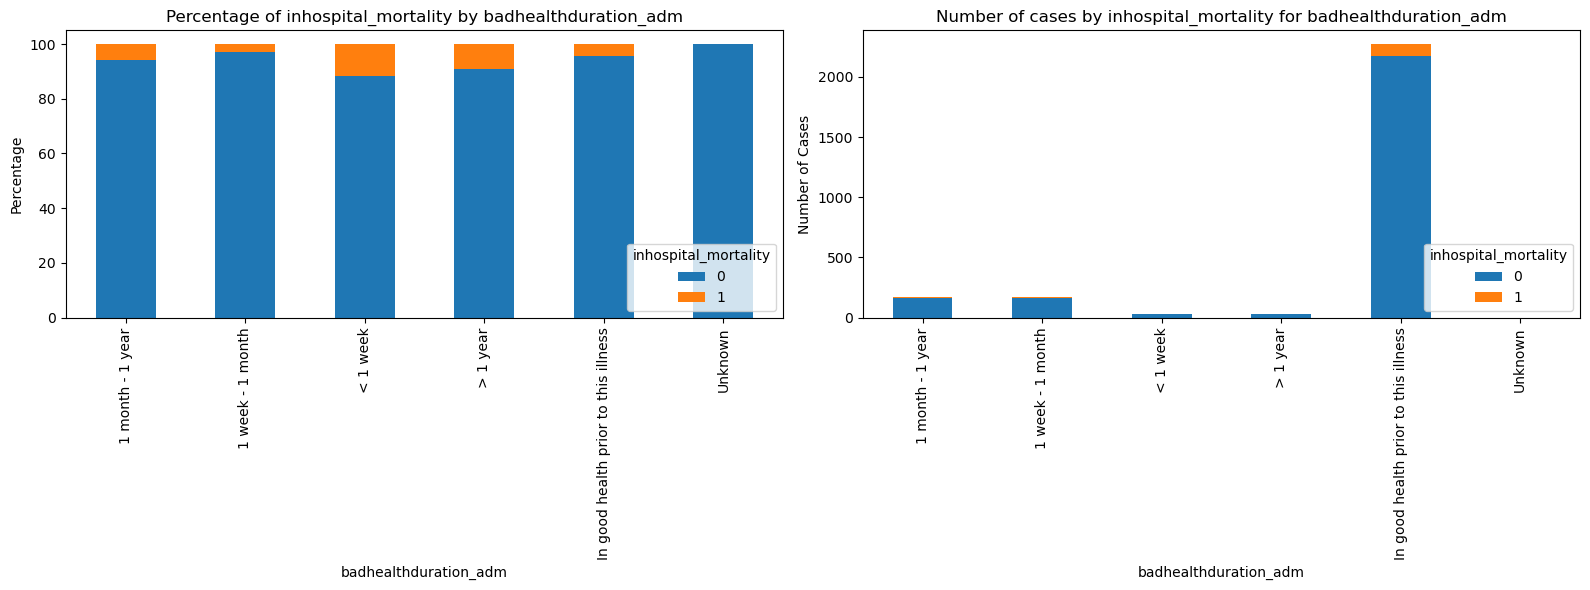

Plotting for column: caregiverage_adm


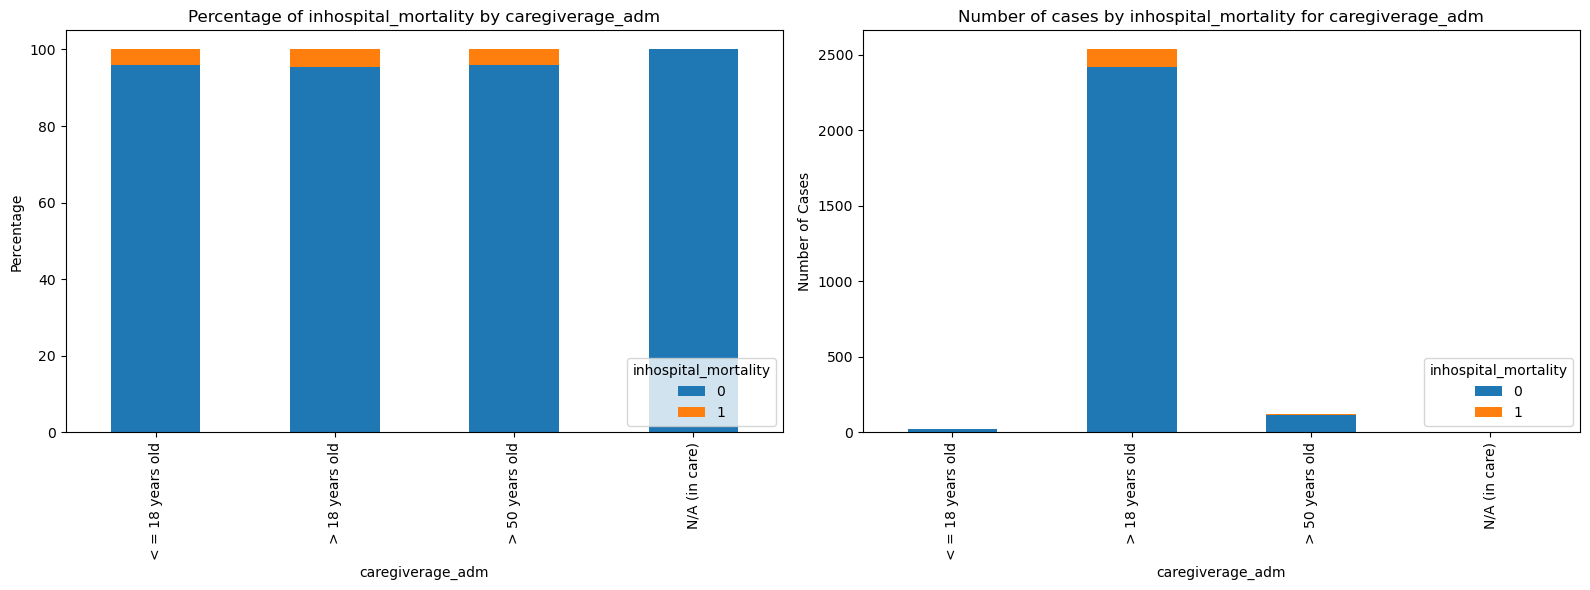

Plotting for column: caregivermarried_adm


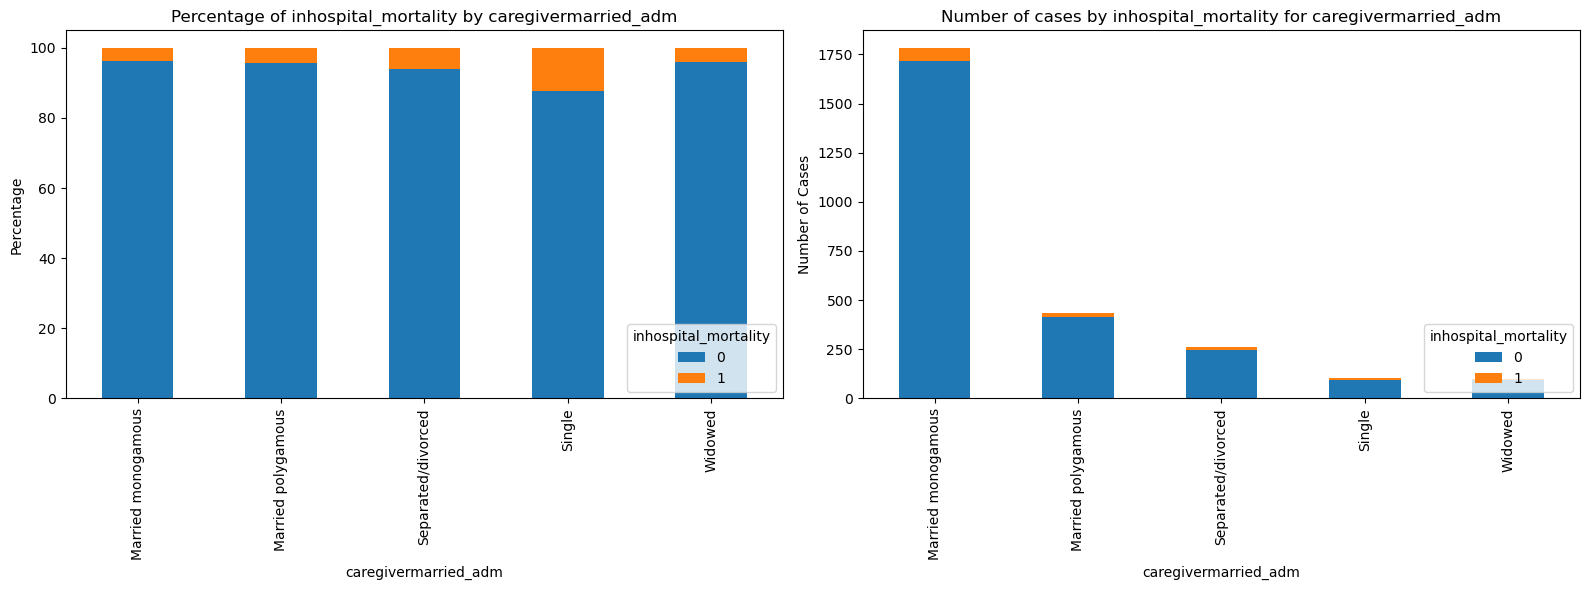

Plotting for column: momalive_adm


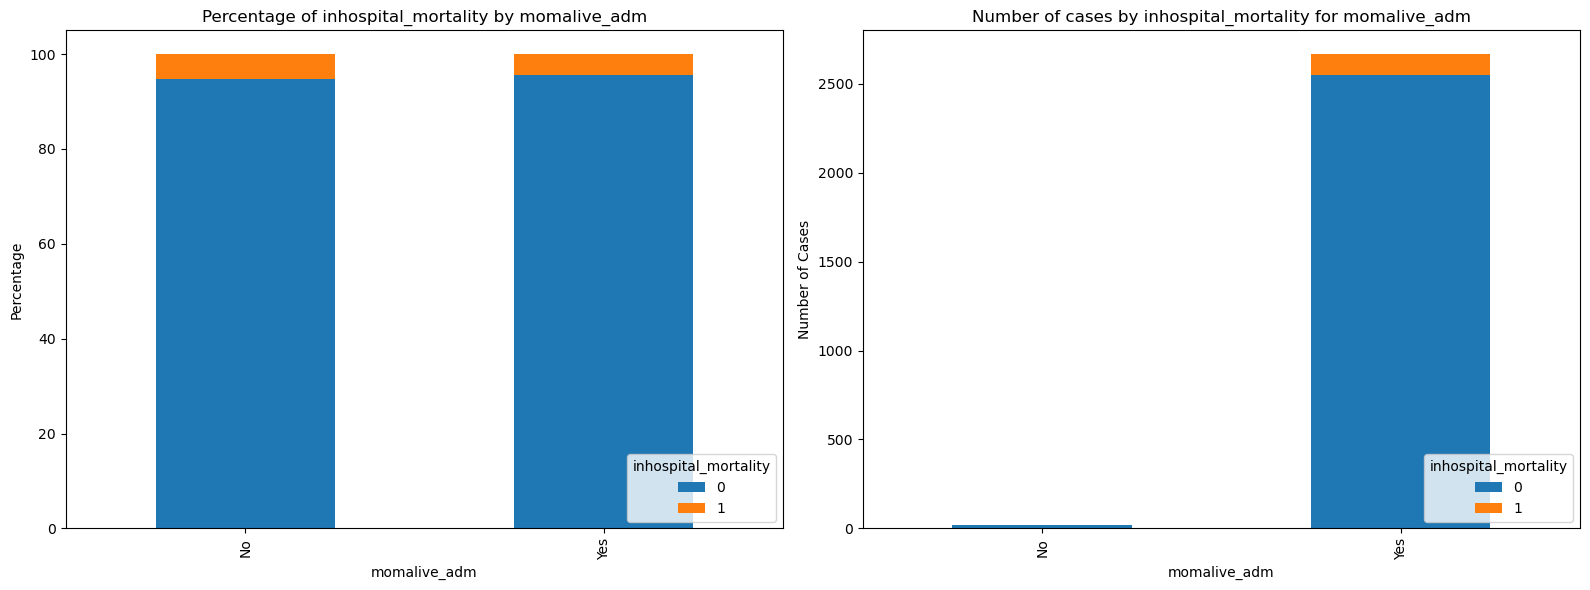

Plotting for column: momageknown_adm


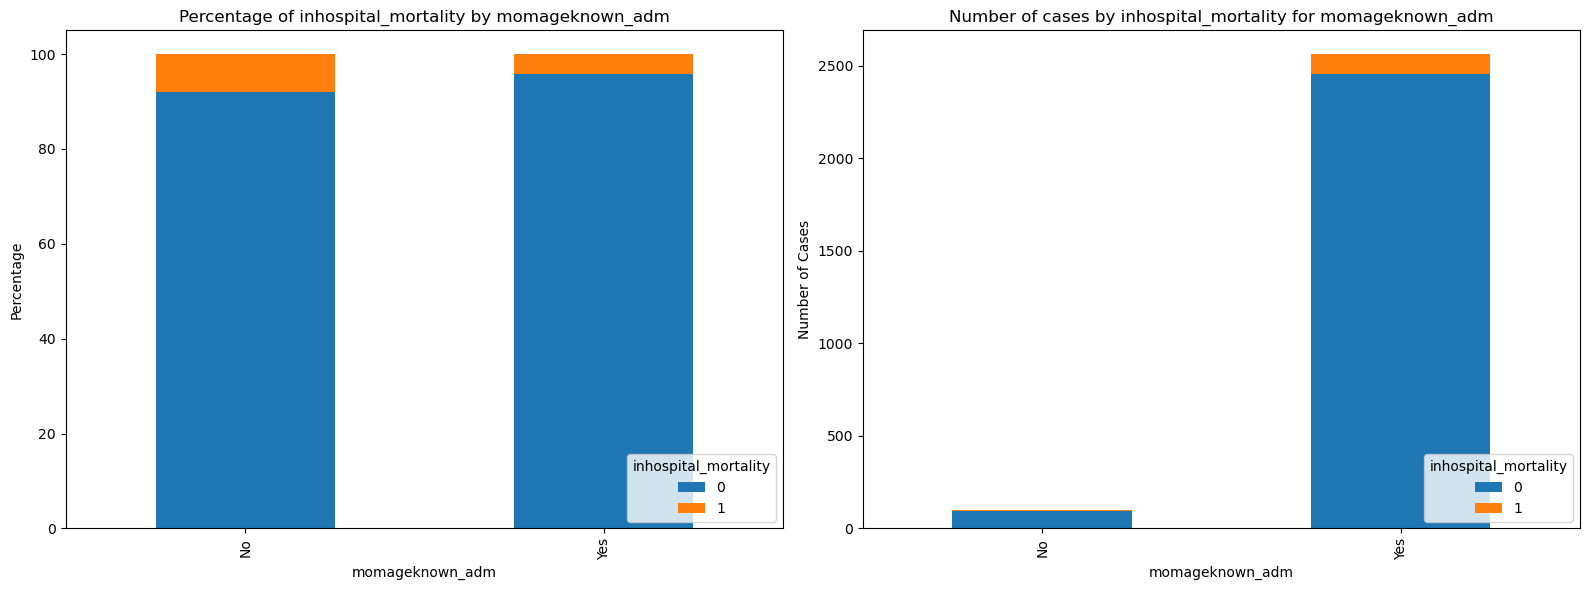

Plotting for column: momagefirstpregknown_adm


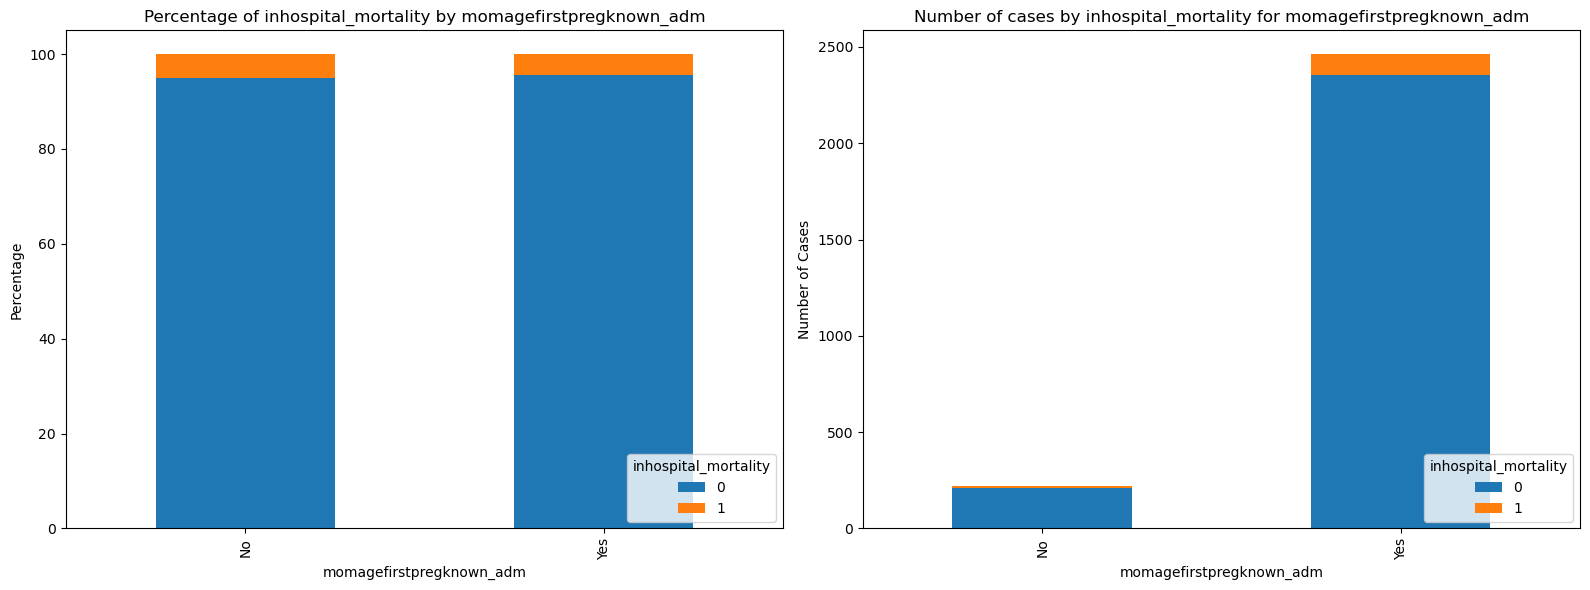

Plotting for column: momedu_adm


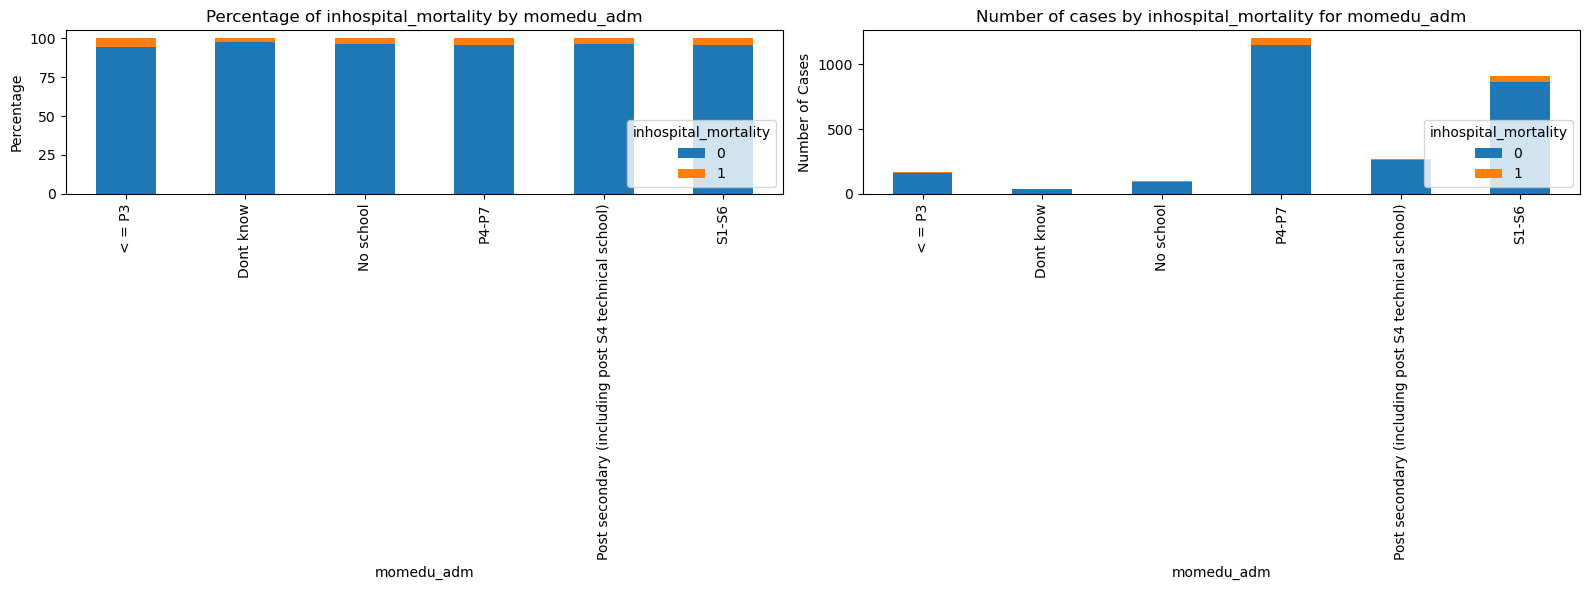

Plotting for column: momhiv_adm


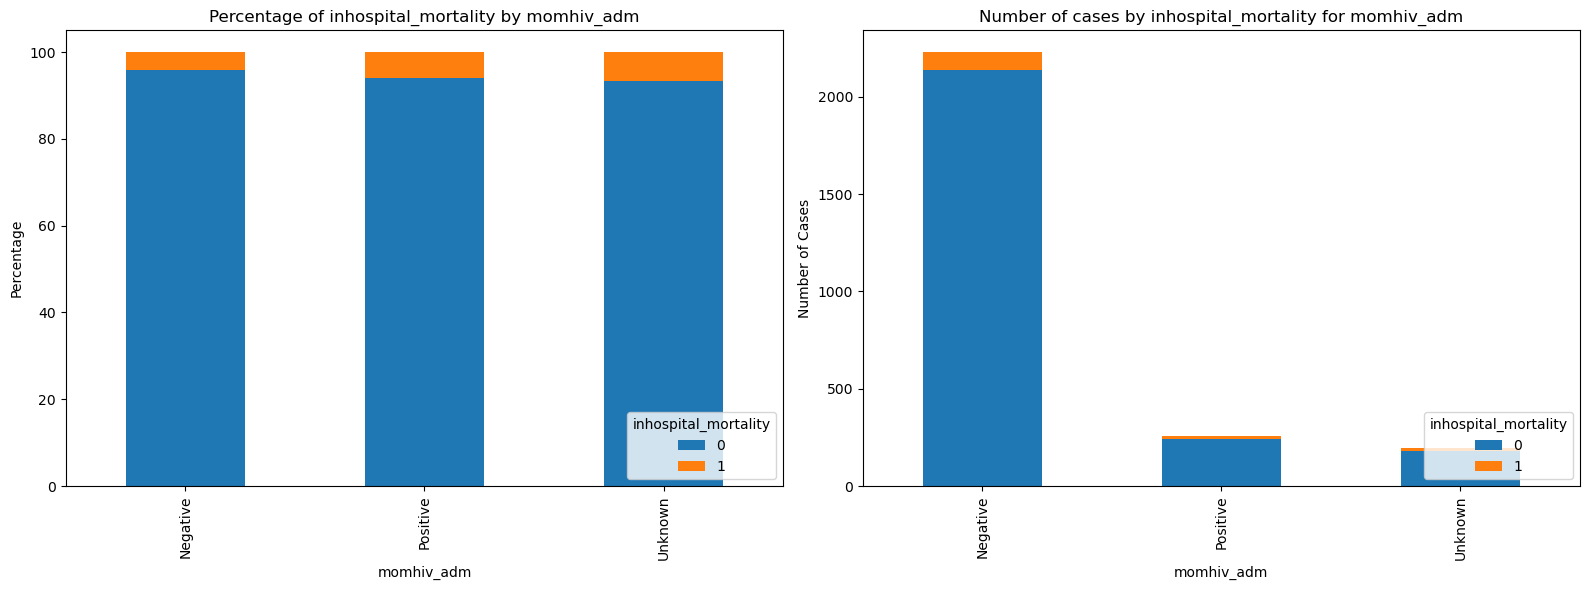

Plotting for column: watersource_adm


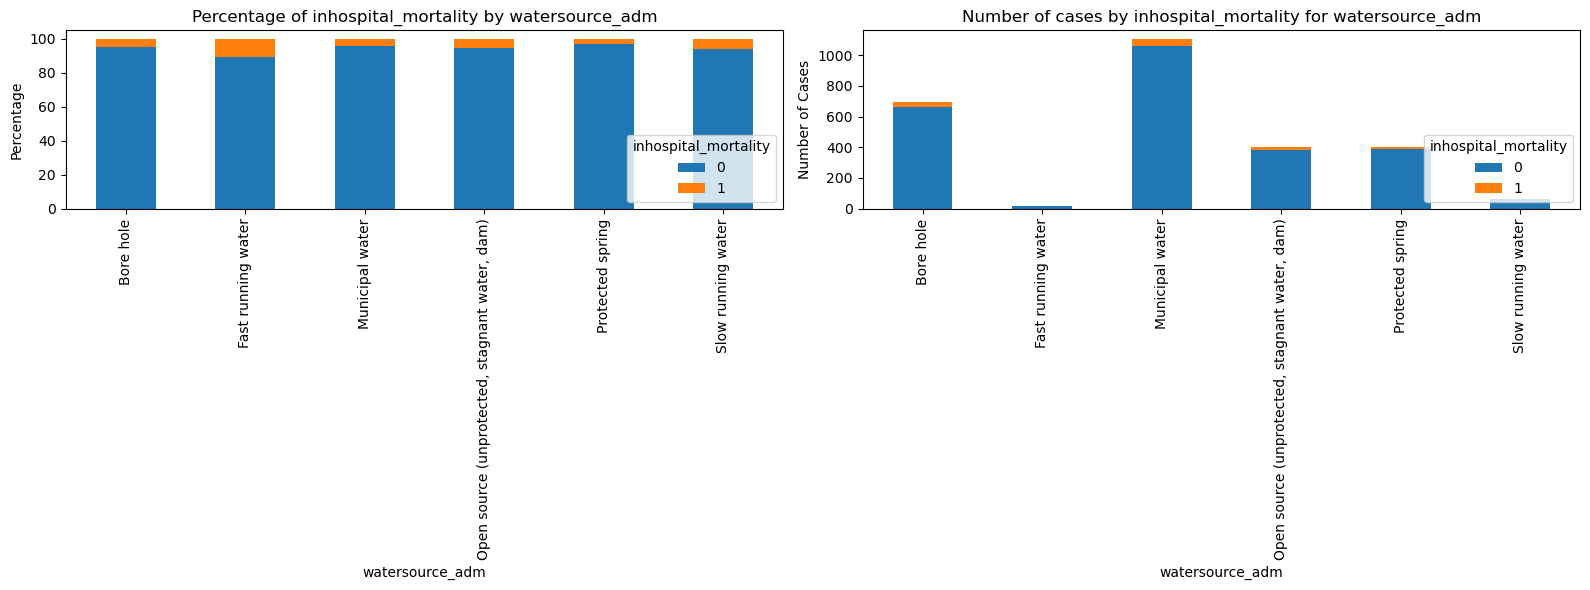

Plotting for column: waterpure_adm


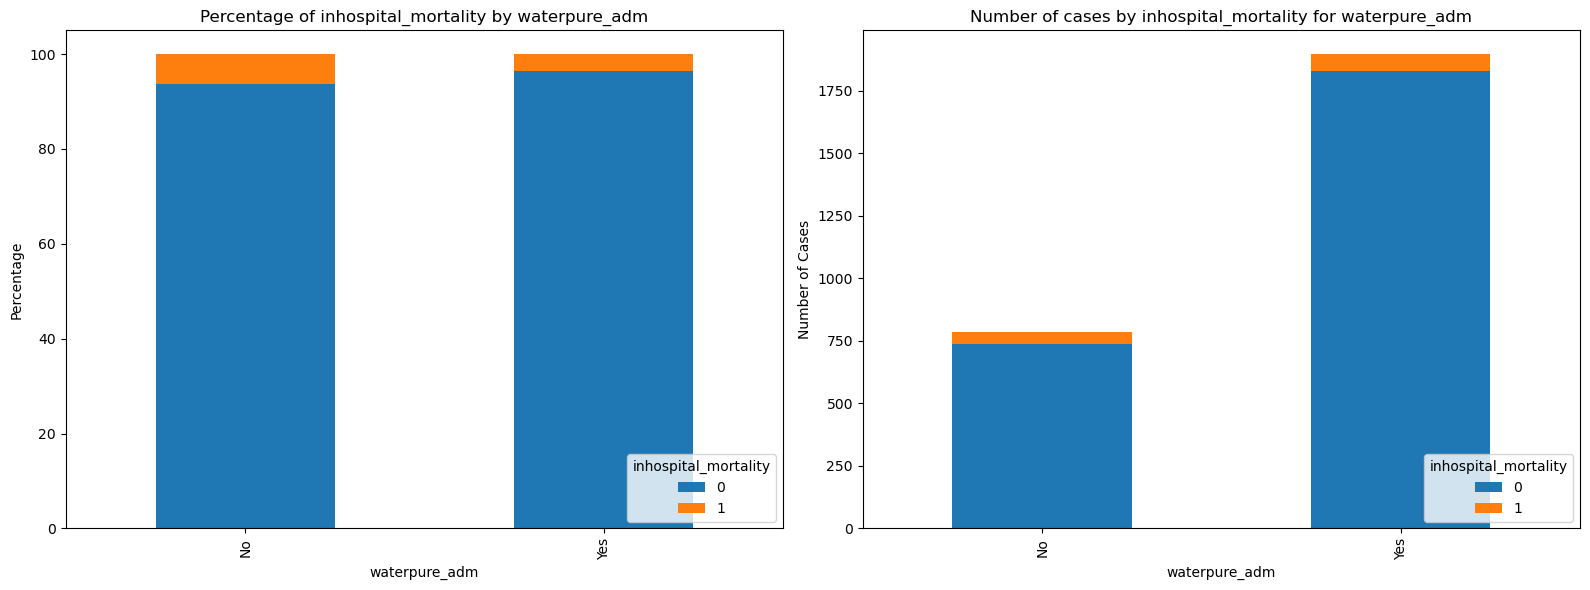

Plotting for column: cookfuel_adm___1


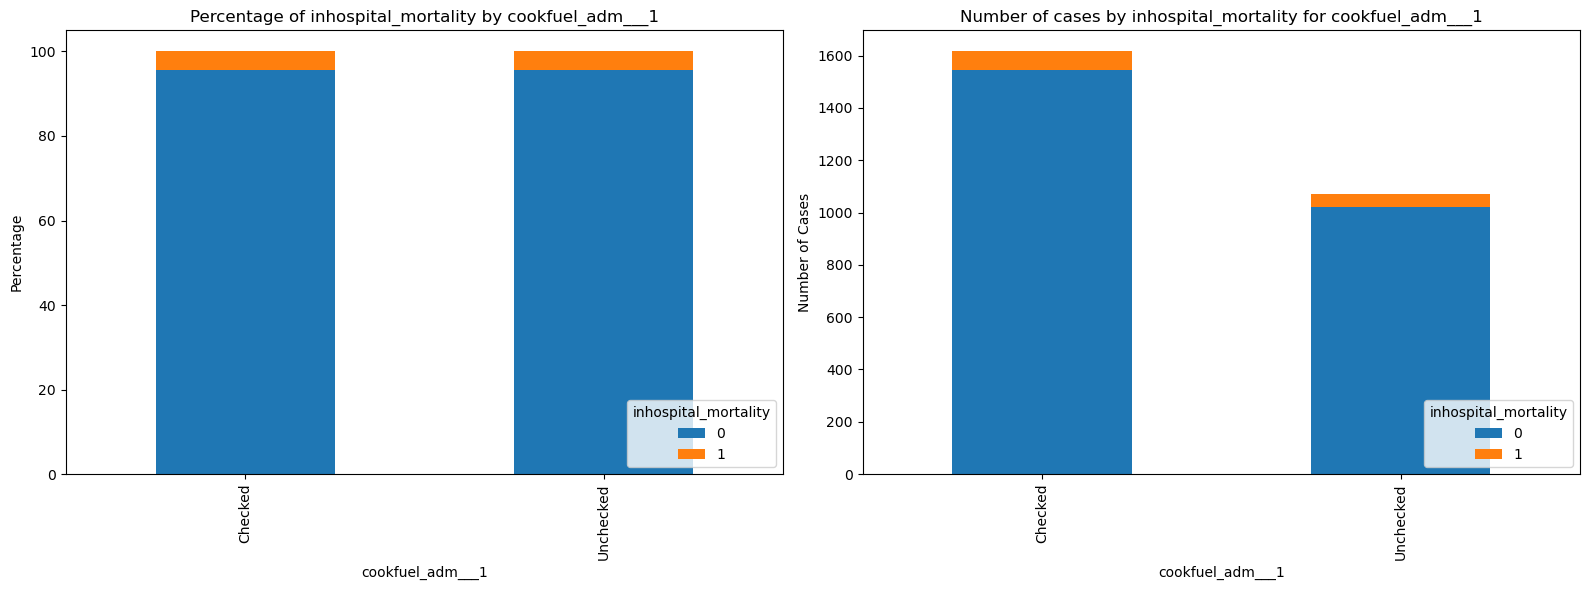

Plotting for column: cookfuel_adm___2


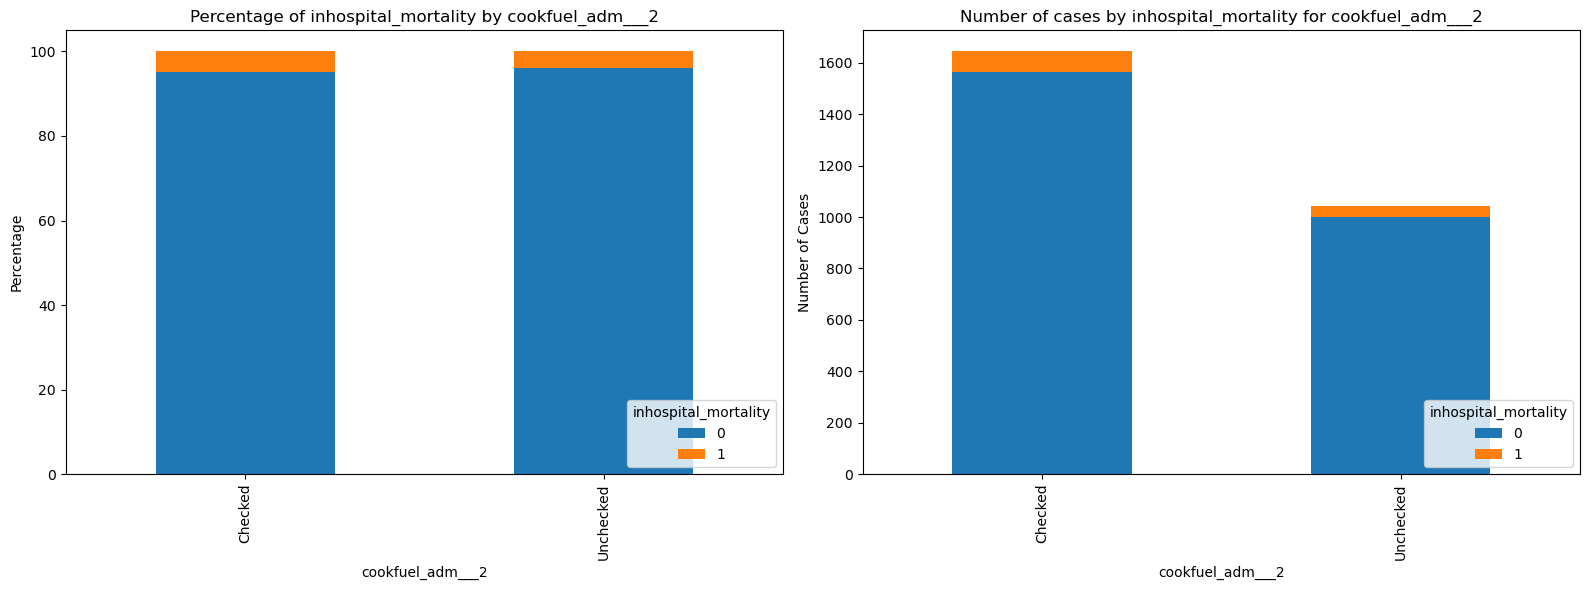

Plotting for column: cookfuel_adm___3


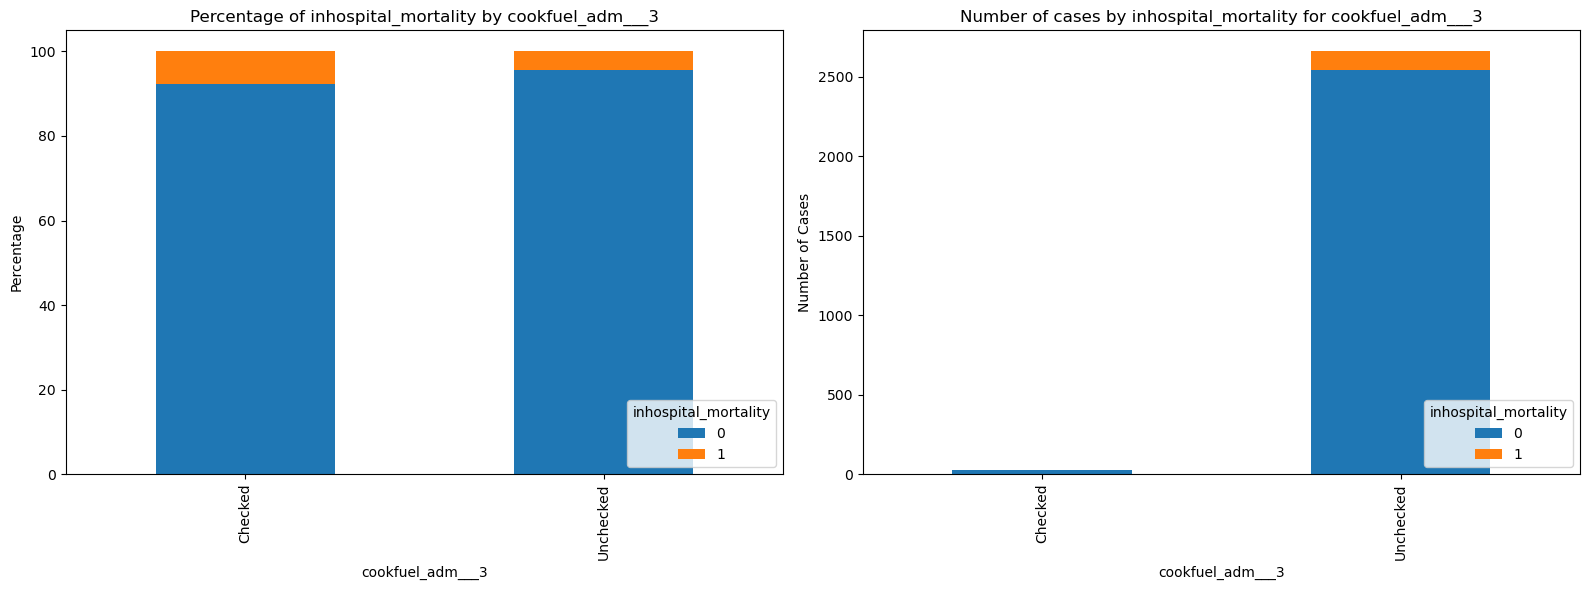

Plotting for column: cookfuel_adm___4


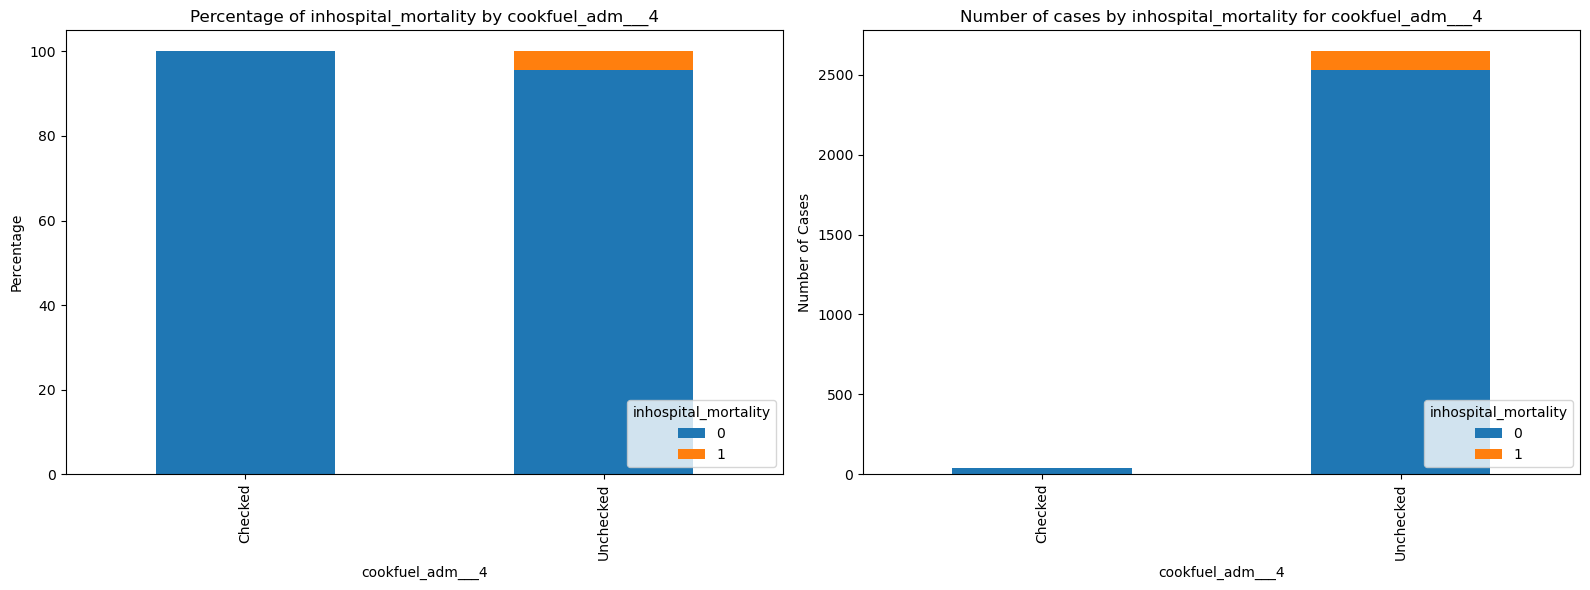

Plotting for column: cookfuel_adm___5


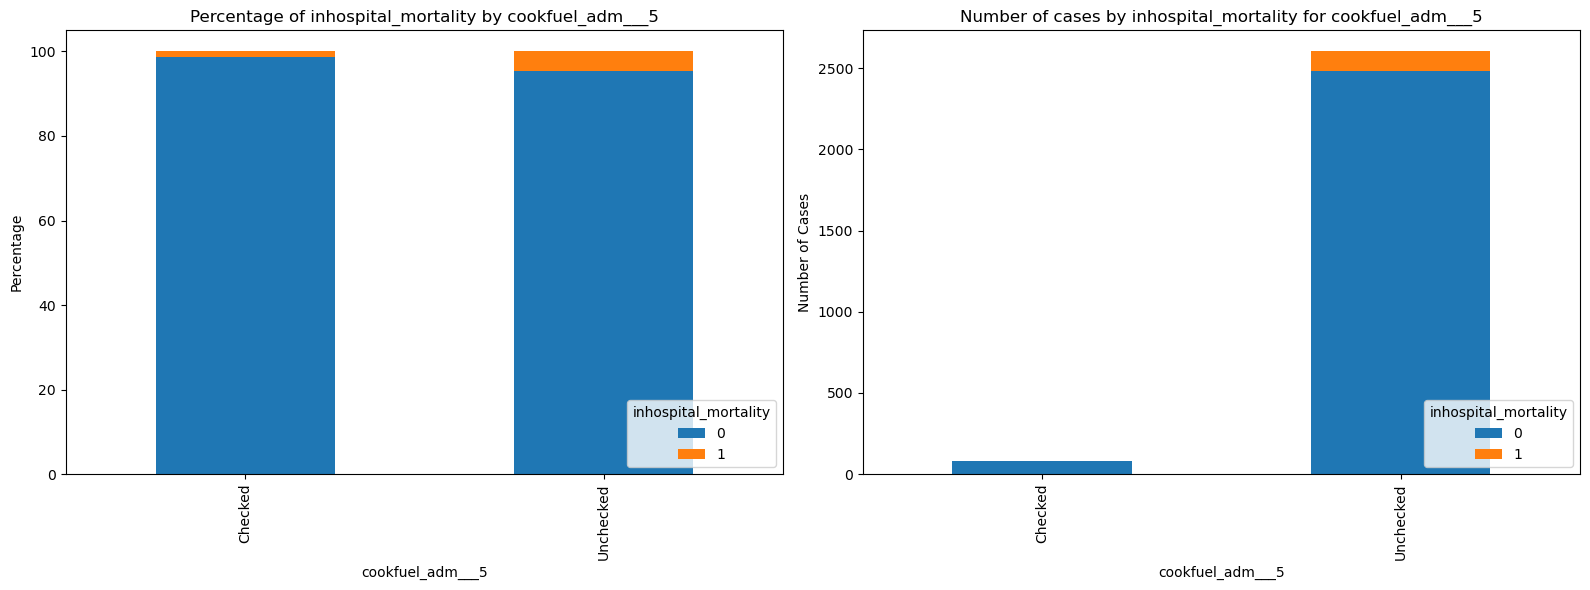

Plotting for column: cookfuel_adm___6


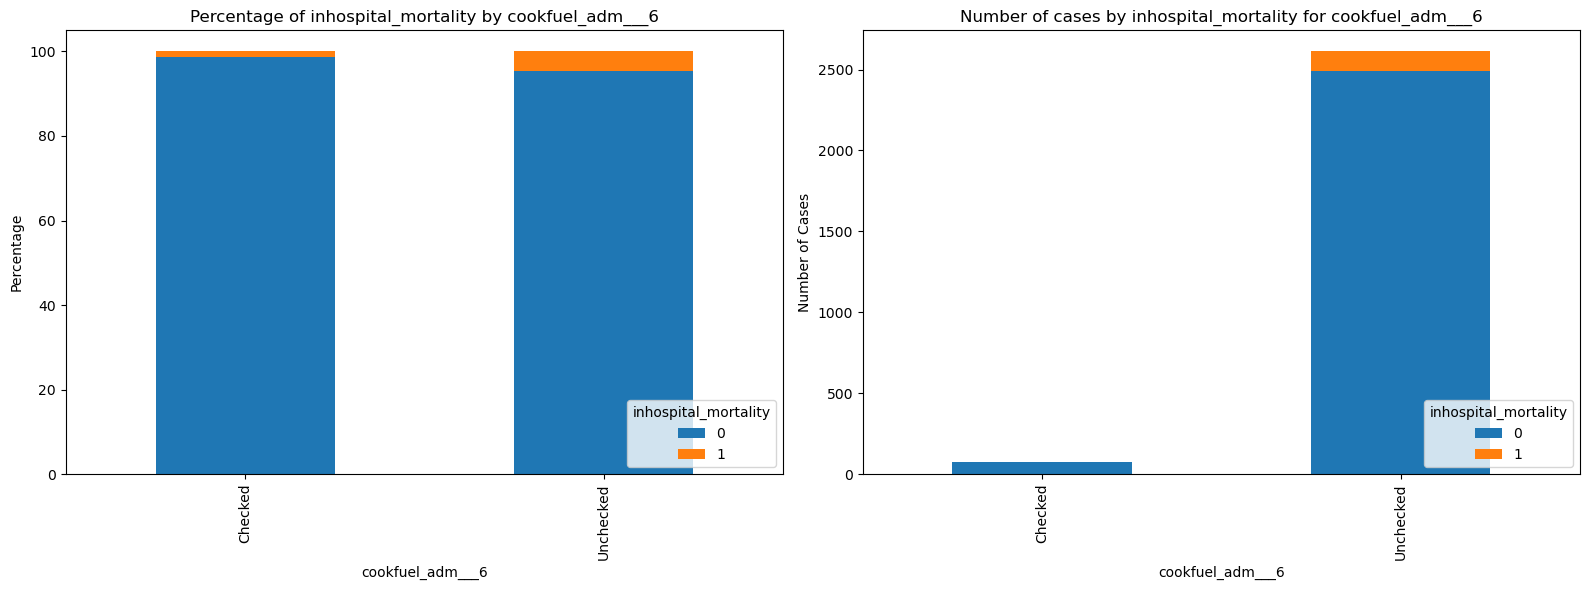

Plotting for column: cookfuel_adm___7


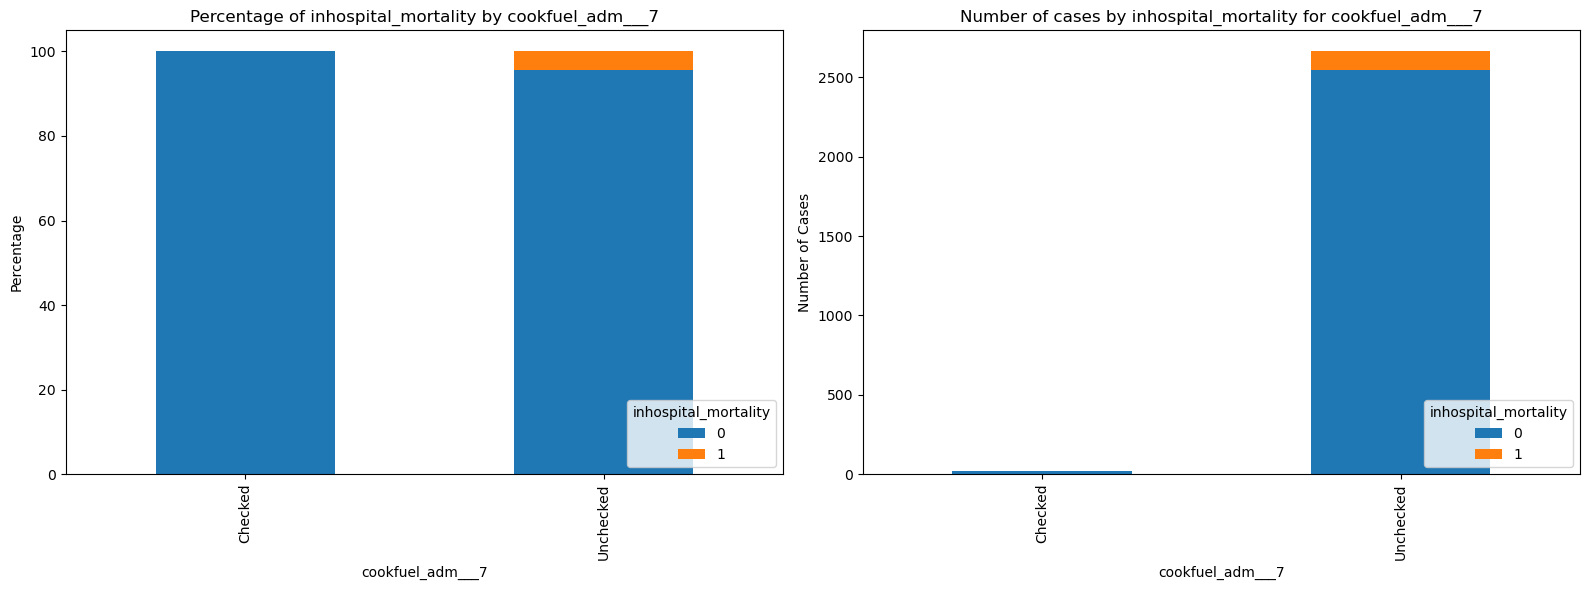

Plotting for column: cookfuel_adm___8


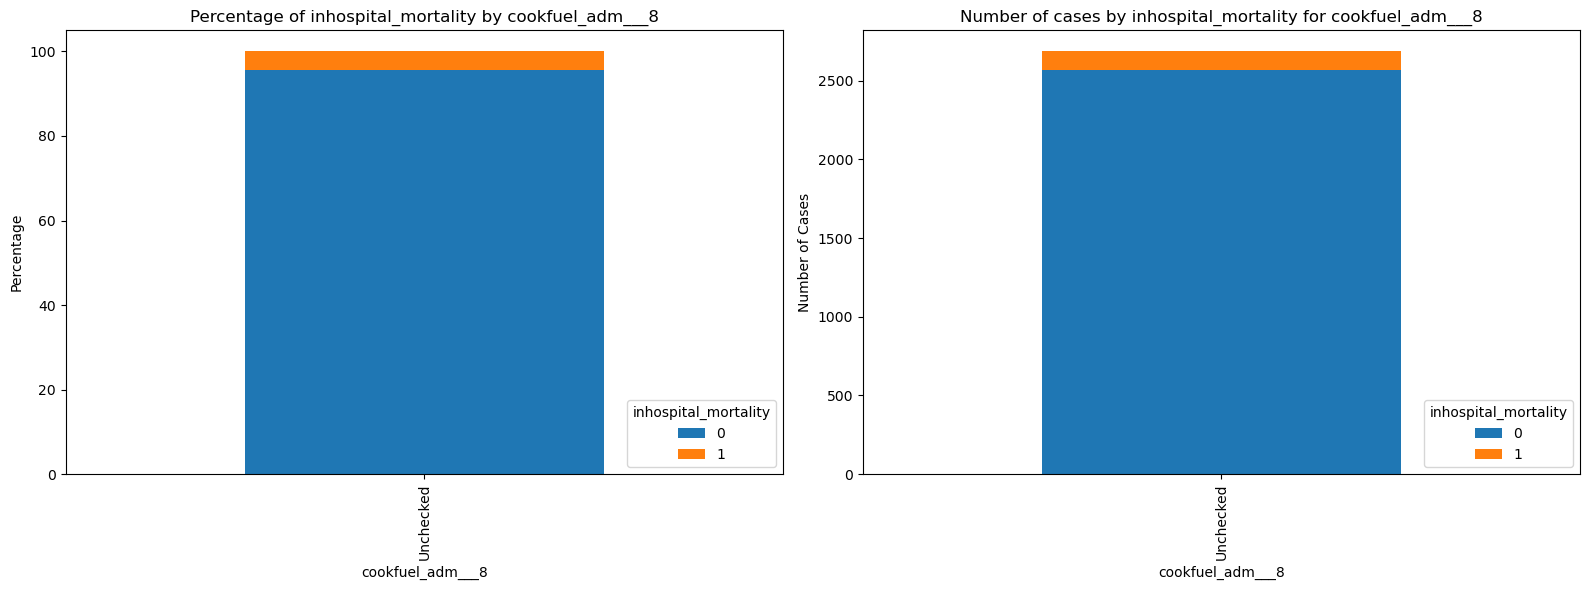

Plotting for column: cookloc_adm


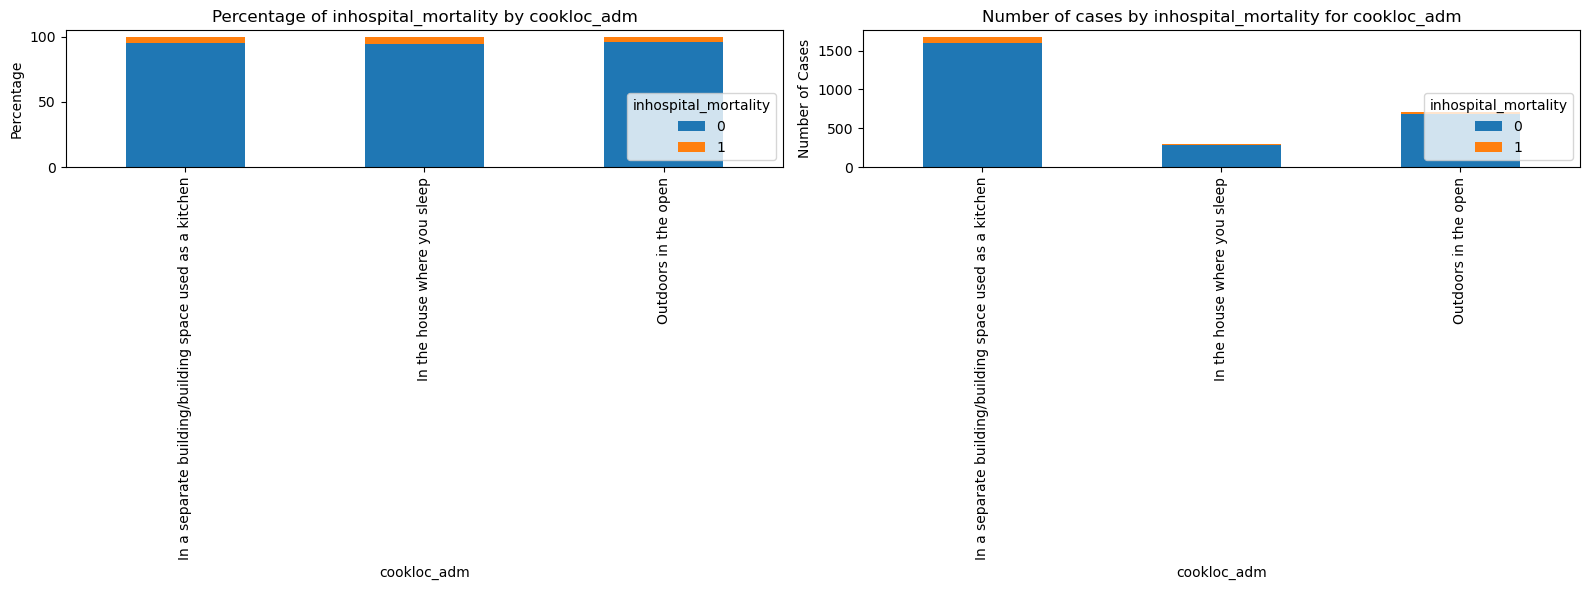

Plotting for column: lightfuel_adm


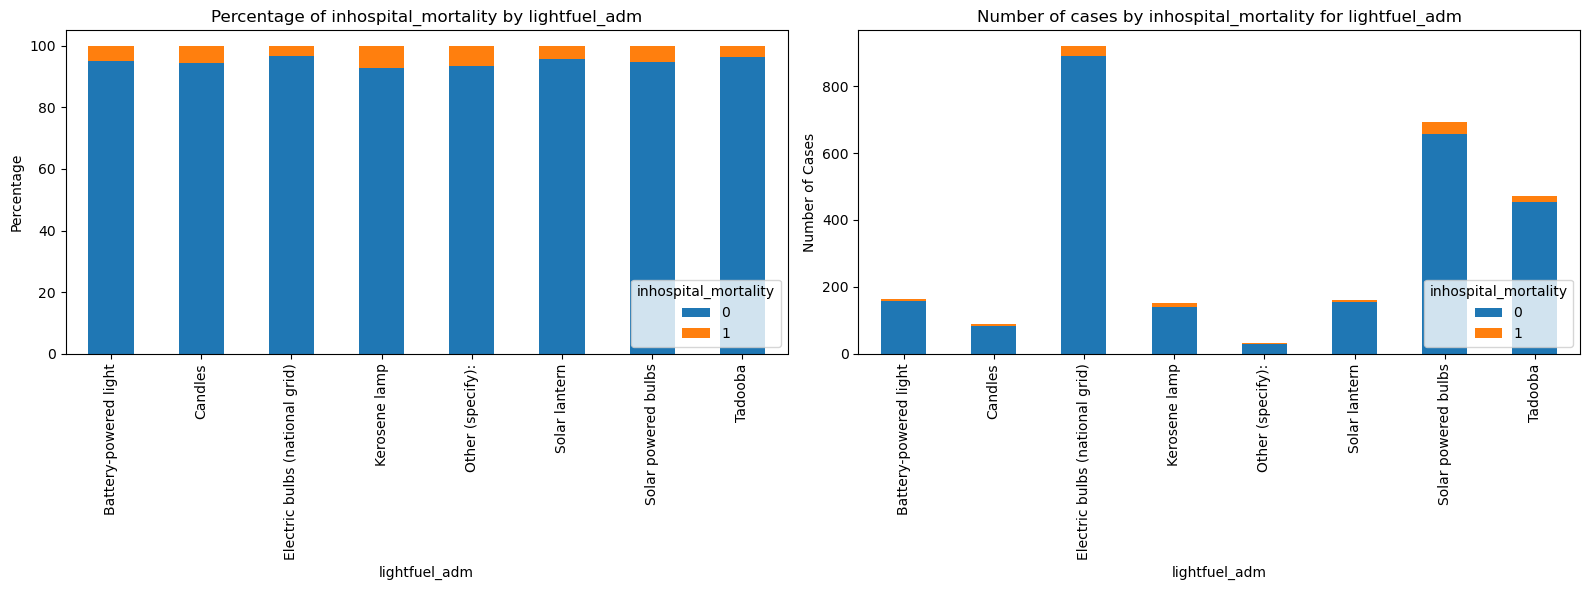

Plotting for column: tobacco_adm


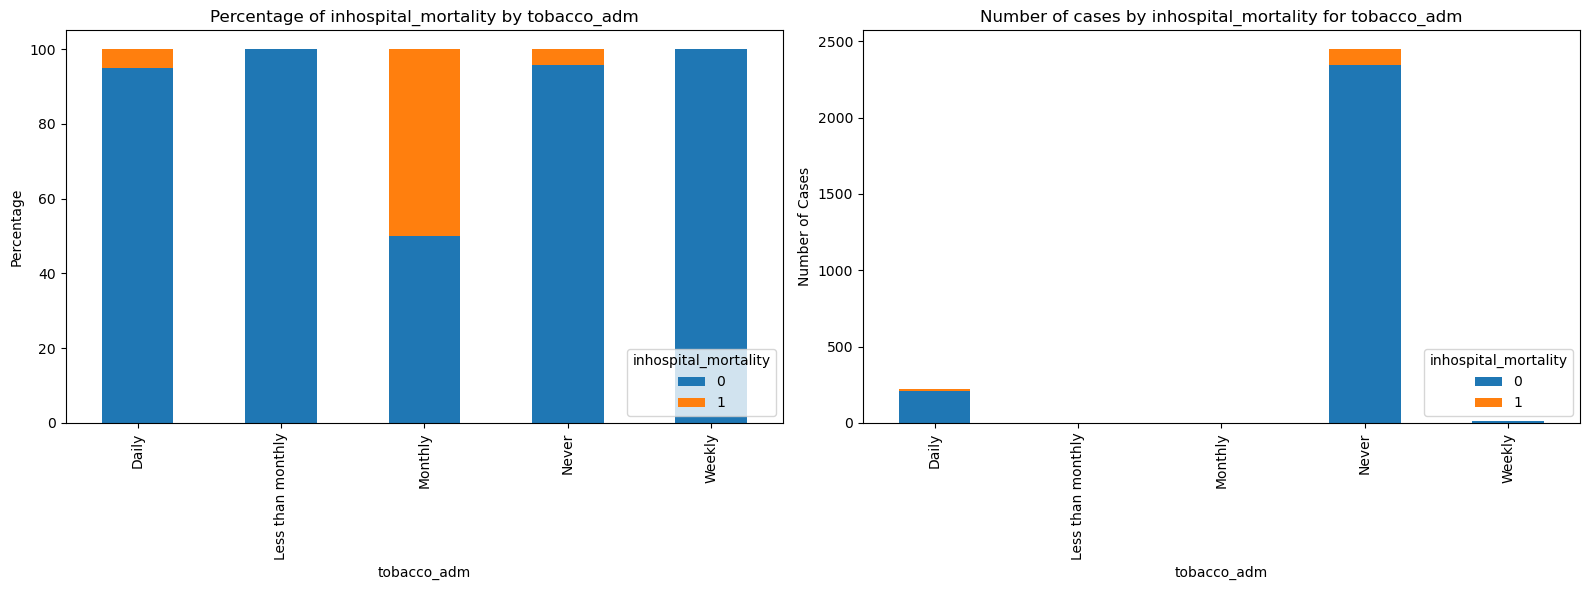

Plotting for column: bednet_adm


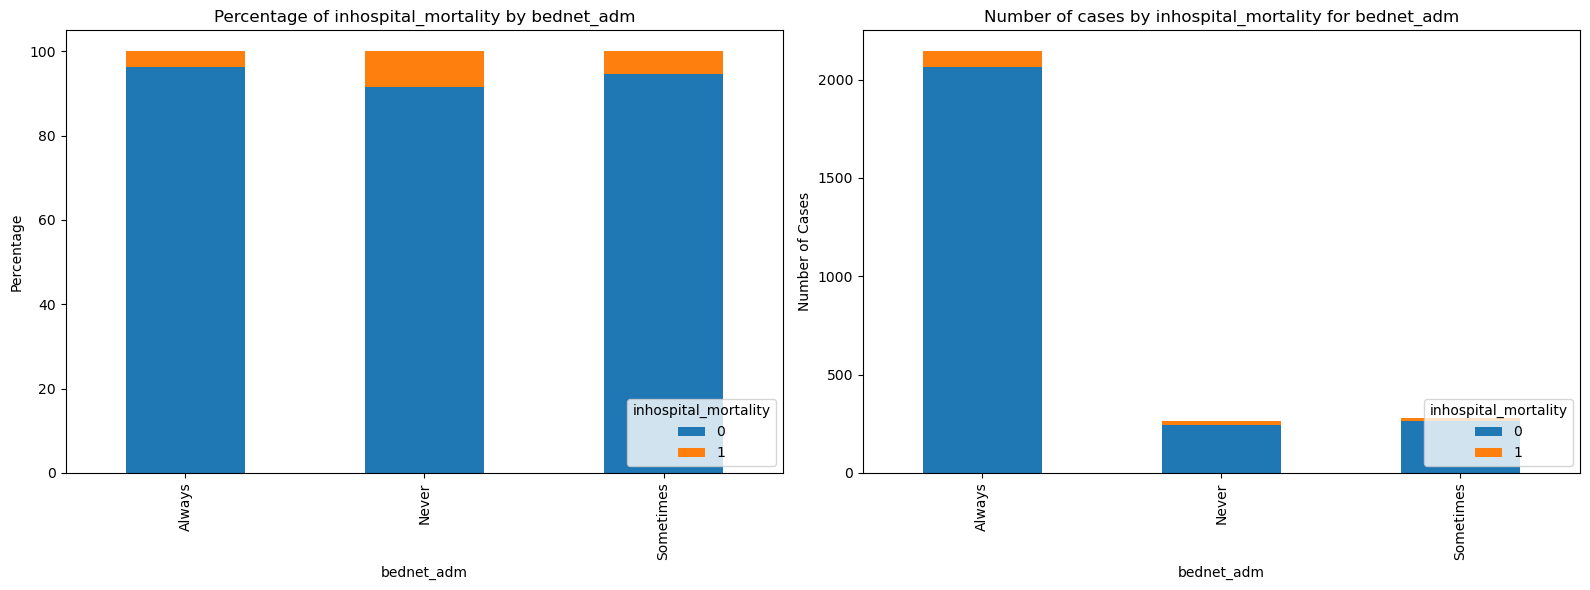

Plotting for column: hctpretransfusion_adm


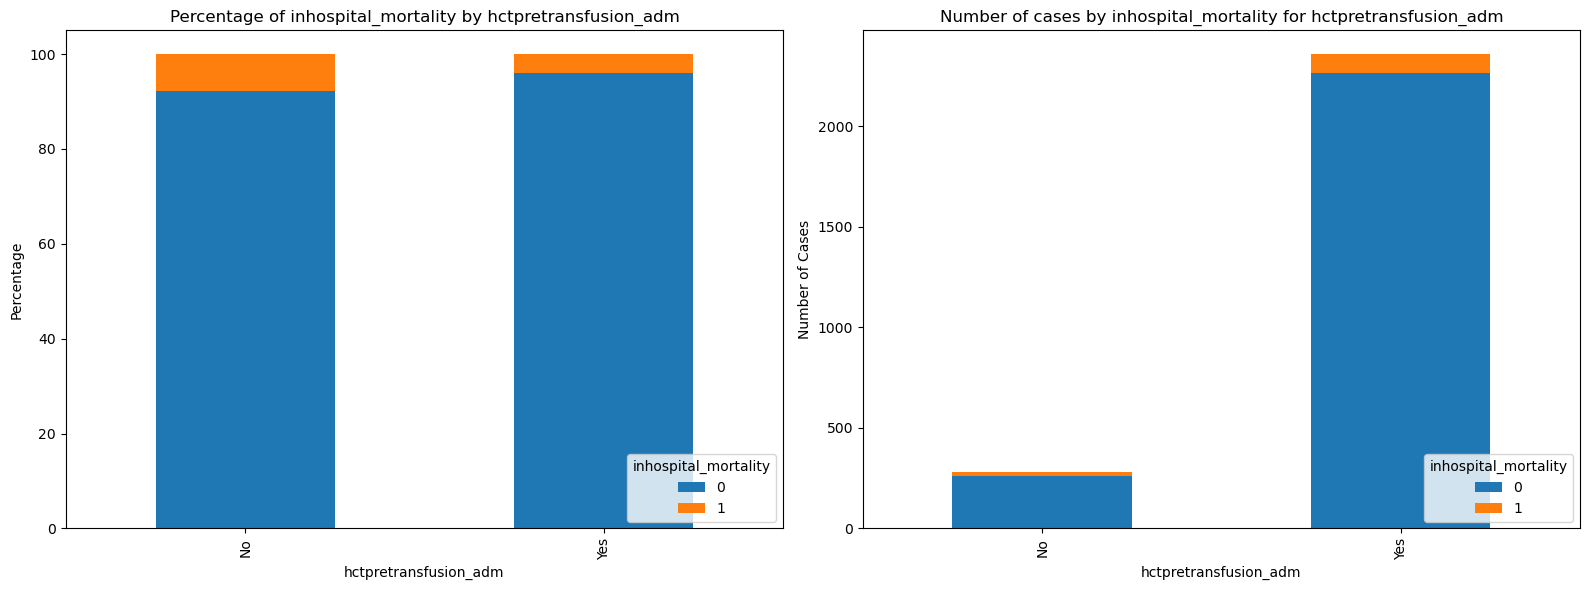

Plotting for column: hivstatus_adm


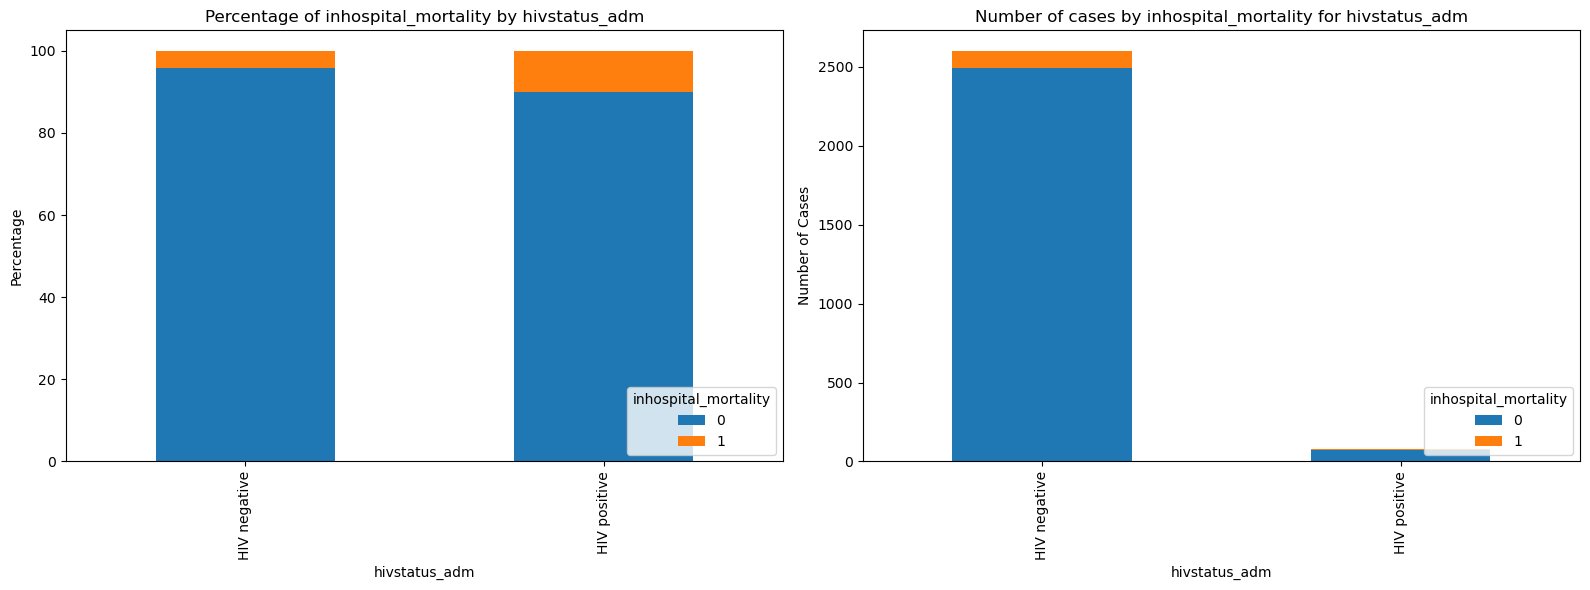

Plotting for column: malariastatuspos_adm


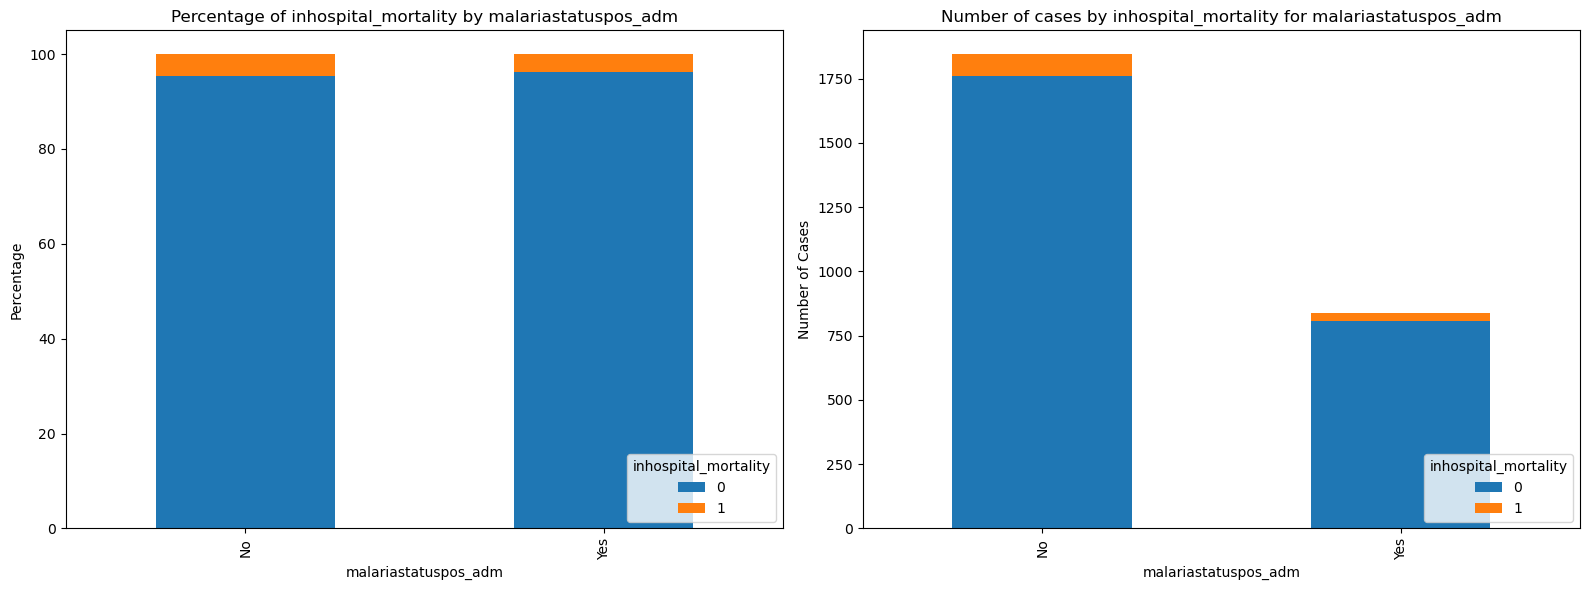

Plotting for column: caregiver_adm_new


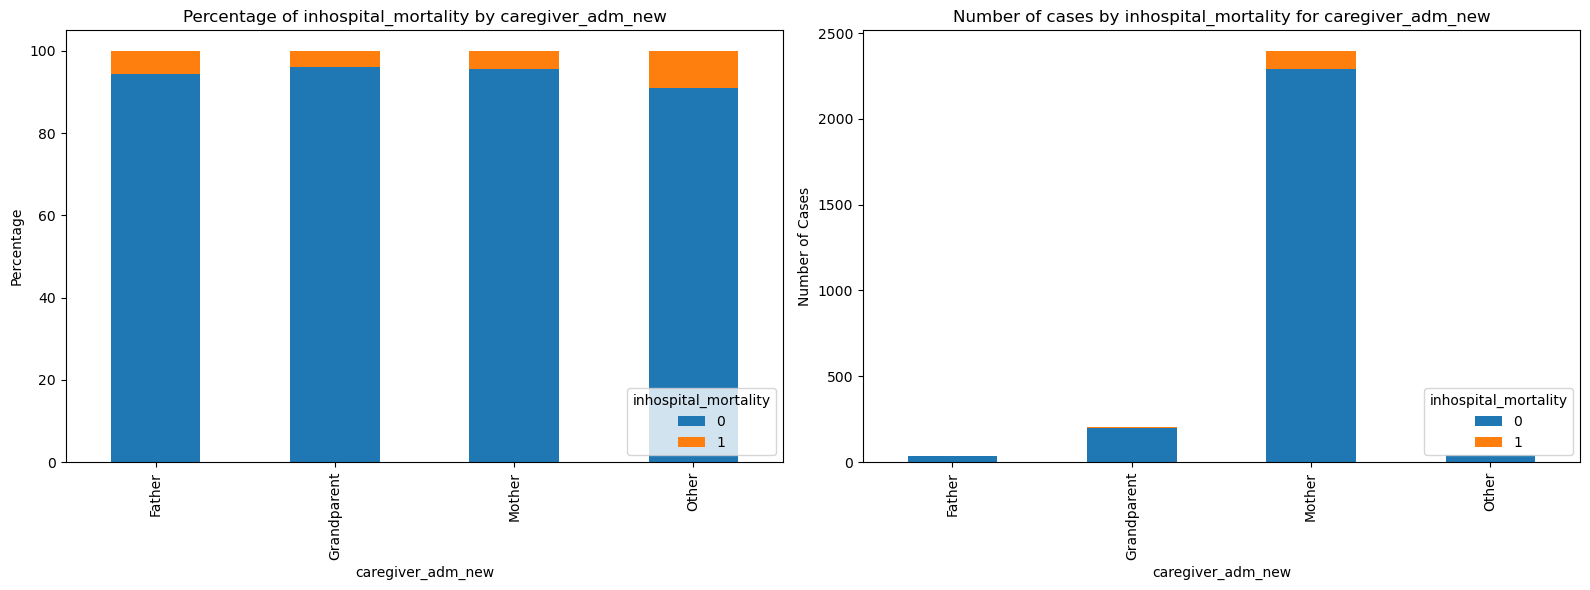

Plotting for column: inhospital_mortality


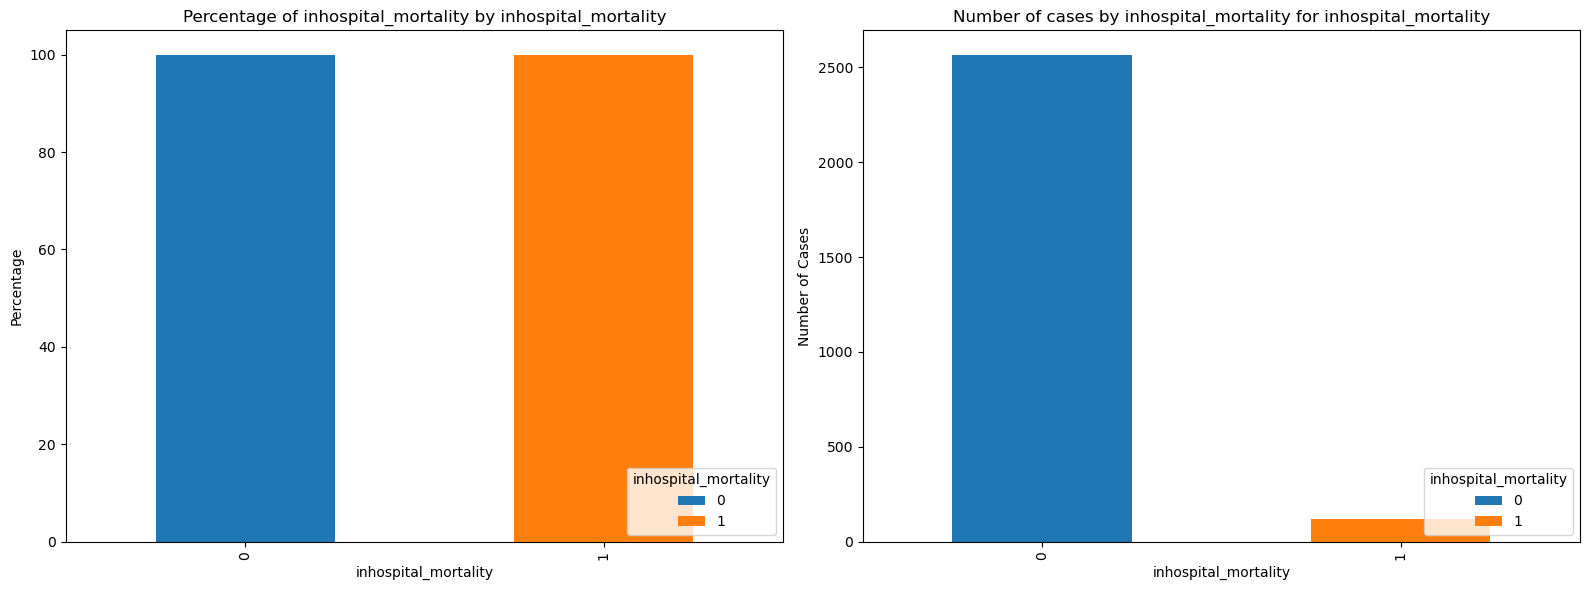

In [21]:
# Loop to visualize all the categorical columns
categorical_columns = clean_data.select_dtypes(include=['object', 'category']).columns

for column in categorical_columns:
    print(f"Plotting for column: {column}")
    plot_categorical_with_subplots(column)


#### Visualize the Numerical columns

Function to visualize the plots side to side.

In [22]:
def plots_numerical(column_name):
  
    # Figure with subplots
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # Plot histogram for a column
    axes[0].hist(clean_data[column_name])
    axes[0].set_title('Histogram of {}'.format(column_name))
    axes[0].set_xlabel(column_name)
    axes[0].set_ylabel('Frequency')

    # Create a boxplot based on attrition
    sns.boxplot(data=clean_data, x='inhospital_mortality', y=column_name, ax=axes[1])
    axes[1].set_title('Boxplot of {} by inhospital_mortality'.format(column_name))
    axes[1].set_xlabel('inhospital_mortality')
    axes[1].set_ylabel(column_name)

    # Create a violin plot to visualize selected column distribution by attrition
    sns.violinplot(data=clean_data, x='inhospital_mortality', y=column_name, ax=axes[2])
    axes[2].set_title('Distribution of {} by inhospital_mortality'.format(column_name))
    axes[2].set_xlabel('inhospital_mortality')
    axes[2].set_ylabel(column_name)

    # Adjust the spacing between subplots
    plt.tight_layout()

    # Show the plot
    plt.show()

Functions to perform statistical analysis 

In [23]:
# statistical significance functions
# testing normality
# H0:normal
# H1: not normal
def normality (column_name):
    stat, p = stats.shapiro(clean_data[column_name])
    if p < 0.05:
        return " for '{}'distirbution is not normal".format(column_name)
    else:
        return "for '{}'distirbution is normal".format(column_name)
    
#testing mean equality a t-test for equal variance, the hypotheses are:
# H<sub>0</sub>: averages are equal
# H<sub>a</sub>: averages are not equal
def mean_equal (column_name):
    mortality_average = clean_data[clean_data['inhospital_mortality']==1][column_name]
    alive_average = clean_data[clean_data['inhospital_mortality']==0][column_name]
    stat, p = stats.ttest_ind( mortality_average, alive_average)
    if p < 0.05:
        return "average are not equal"
    else:
        return "average are equal"
    
 # average equality for non equal variance   
def equalmean_inequalvariance(column_name):
    alive= clean_data[clean_data['inhospital_mortality']==0][column_name]
    mortality = clean_data[clean_data['inhospital_mortality']==1][column_name]
    stat, p = stats.ttest_ind(alive, mortality, equal_var=False)
    if p < 0.05:
        return "average are not equal"
    else:
        return "average are equal"
 # average equality for equal variance
def mean_equal_all (column_name):
    alive= clean_data[clean_data['inhospital_mortality']==0][column_name]
    mortality = clean_data[clean_data['inhospital_mortality']==1][column_name]
    stat, p = stats.levene(alive,mortality)
    if p < 0.05:
        return "variance is not equal".format(column_name), equalmean_inequalvariance(column_name)
    else:
        return "variance is equal".format(column_name), mean_equal(column_name)

In [24]:
def plots_statistical_analysis(column_name):
    plots_numerical(column_name)
    return normality(column_name),mean_equal_all(column_name)

Loop to visualize all the numerical columns

Analyzing column: agecalc_adm


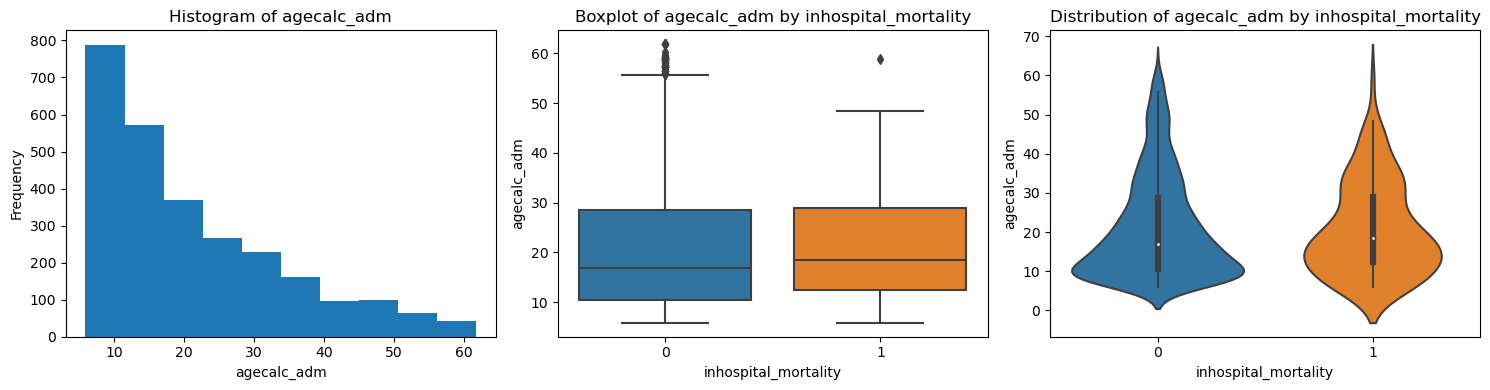

Normality Test Result for agecalc_adm:  for 'agecalc_adm'distirbution is not normal
Mean and Variance Equality Test Result for agecalc_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: height_cm_adm


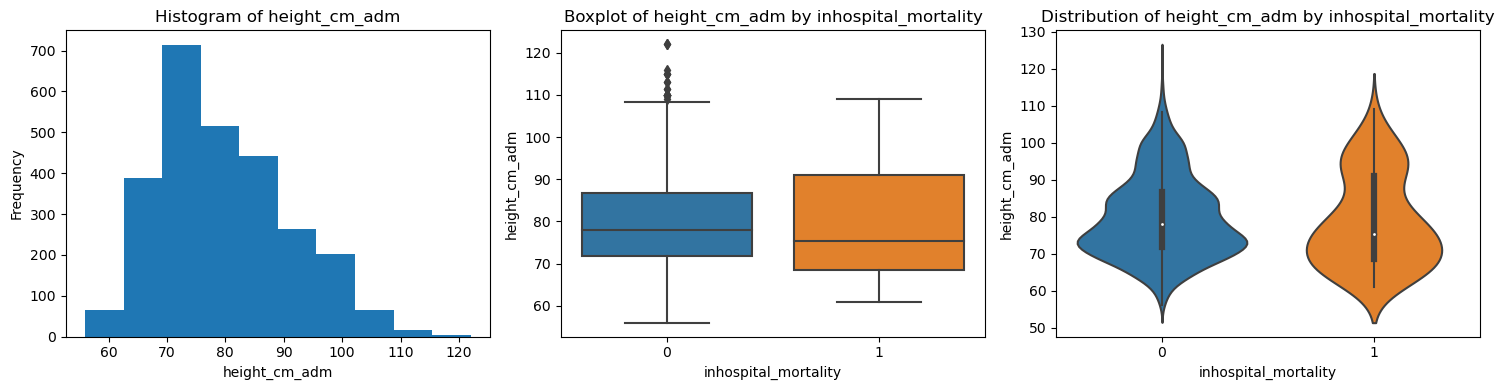

Normality Test Result for height_cm_adm: for 'height_cm_adm'distirbution is normal
Mean and Variance Equality Test Result for height_cm_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: weight_kg_adm


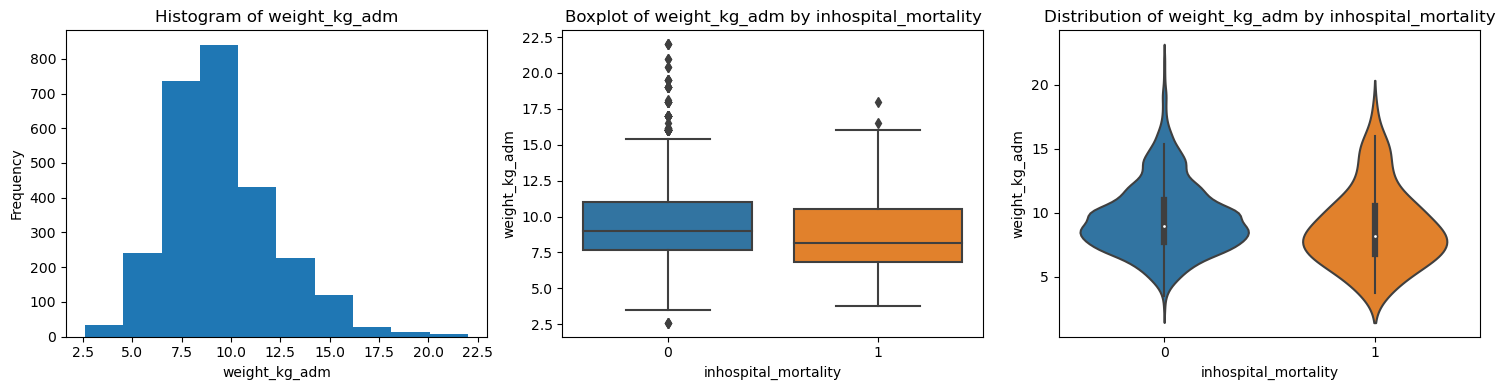

Normality Test Result for weight_kg_adm: for 'weight_kg_adm'distirbution is normal
Mean and Variance Equality Test Result for weight_kg_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: muac_mm_adm


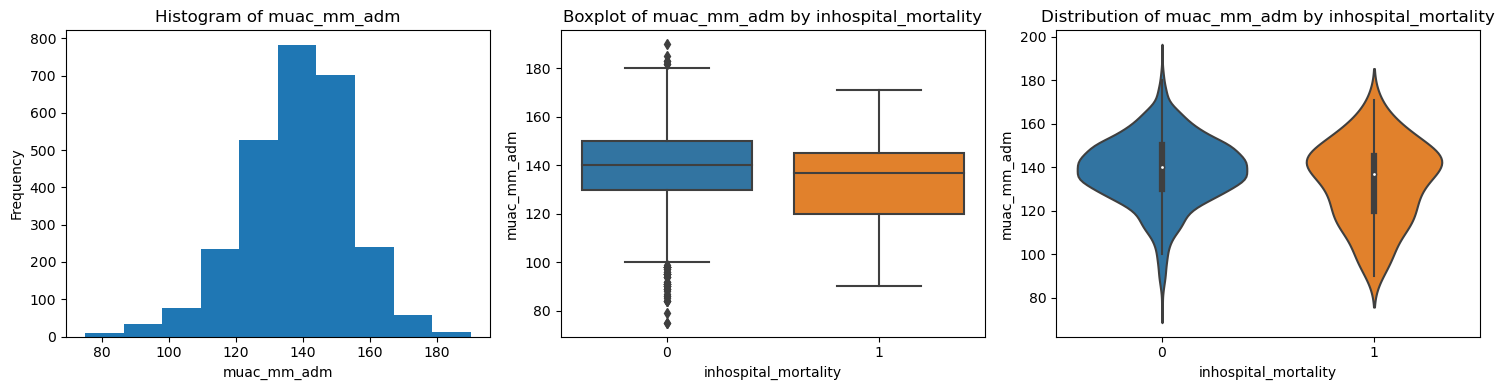

Normality Test Result for muac_mm_adm: for 'muac_mm_adm'distirbution is normal
Mean and Variance Equality Test Result for muac_mm_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: hr_bpm_adm


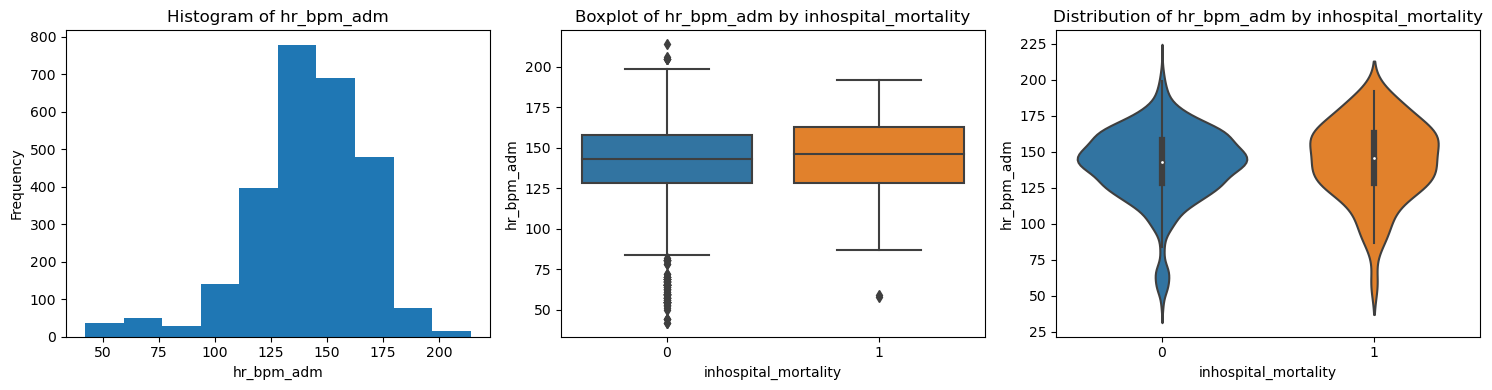

Normality Test Result for hr_bpm_adm: for 'hr_bpm_adm'distirbution is normal
Mean and Variance Equality Test Result for hr_bpm_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: rr_brpm_app_adm


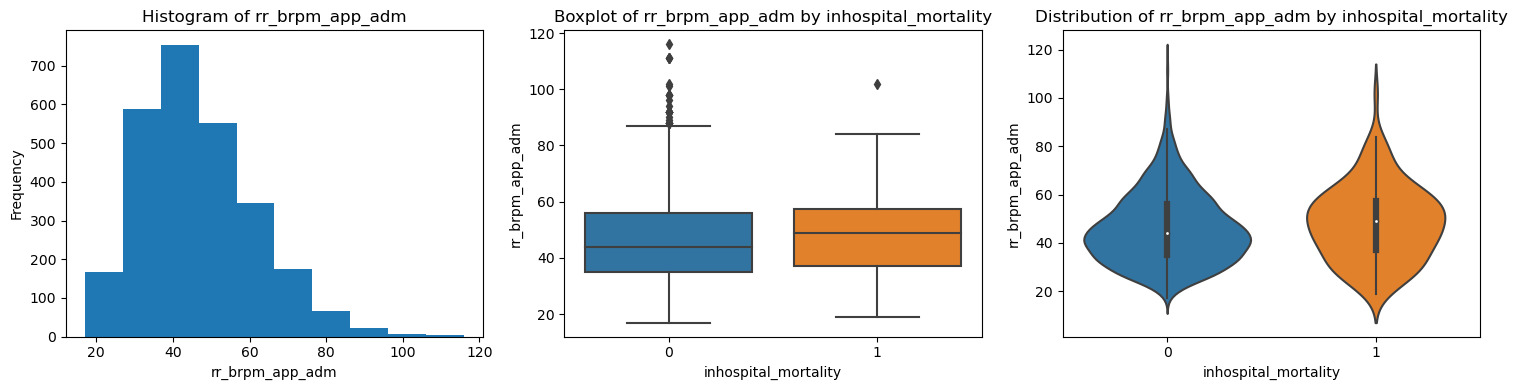

Normality Test Result for rr_brpm_app_adm: for 'rr_brpm_app_adm'distirbution is normal
Mean and Variance Equality Test Result for rr_brpm_app_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: sysbp_mmhg_adm


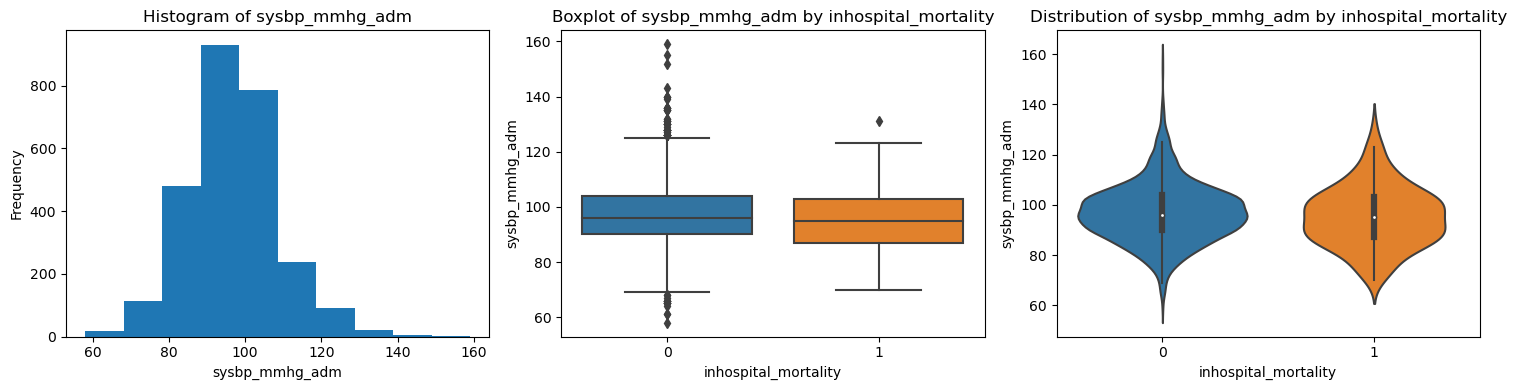

Normality Test Result for sysbp_mmhg_adm: for 'sysbp_mmhg_adm'distirbution is normal
Mean and Variance Equality Test Result for sysbp_mmhg_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: diasbp_mmhg_adm


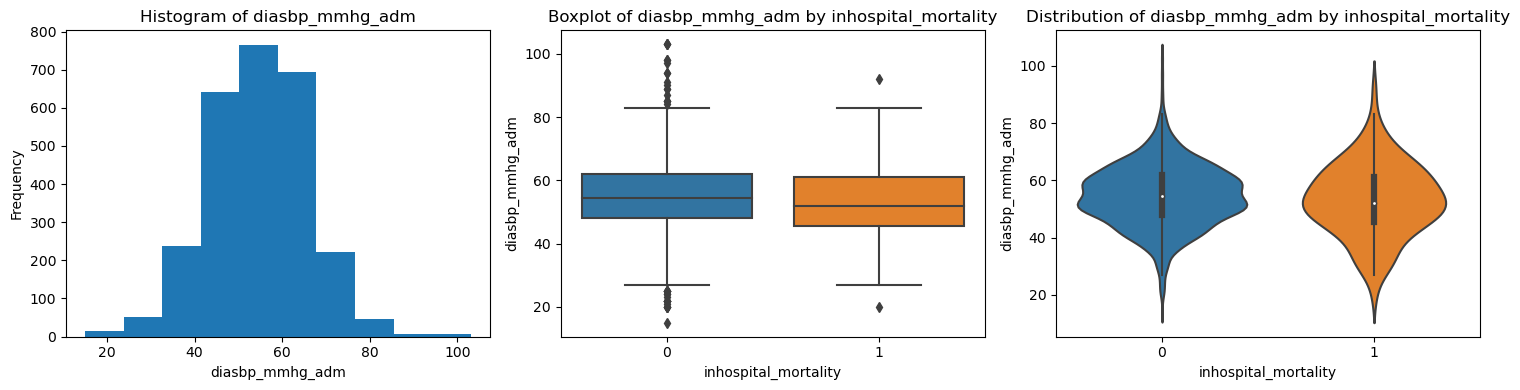

Normality Test Result for diasbp_mmhg_adm: for 'diasbp_mmhg_adm'distirbution is normal
Mean and Variance Equality Test Result for diasbp_mmhg_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: temp_c_adm


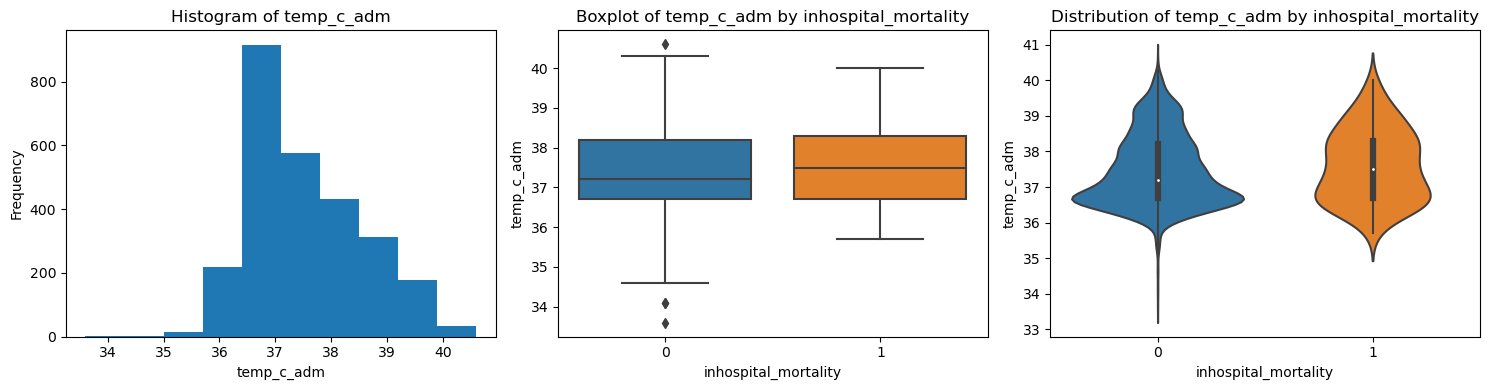

Normality Test Result for temp_c_adm: for 'temp_c_adm'distirbution is normal
Mean and Variance Equality Test Result for temp_c_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: spo2site1_pc_oxi_adm


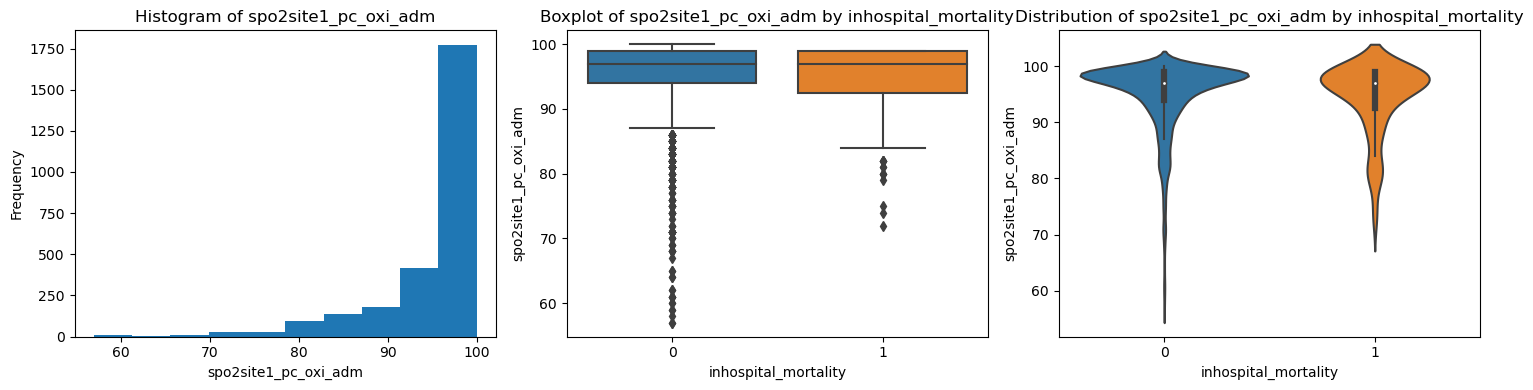

Normality Test Result for spo2site1_pc_oxi_adm: for 'spo2site1_pc_oxi_adm'distirbution is normal
Mean and Variance Equality Test Result for spo2site1_pc_oxi_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: spo2site2_pc_oxi_adm


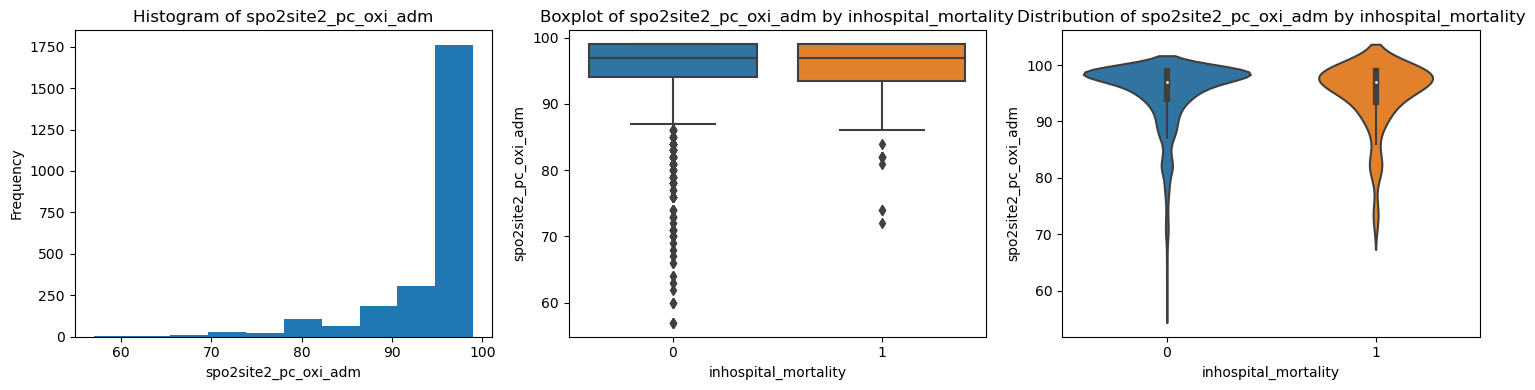

Normality Test Result for spo2site2_pc_oxi_adm: for 'spo2site2_pc_oxi_adm'distirbution is normal
Mean and Variance Equality Test Result for spo2site2_pc_oxi_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: spo2other_adm


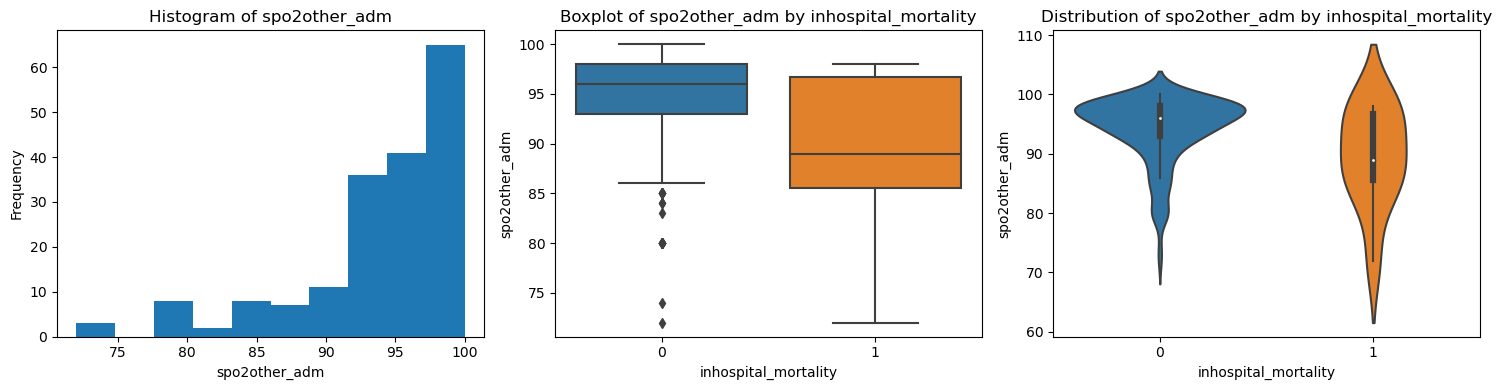

Normality Test Result for spo2other_adm: for 'spo2other_adm'distirbution is normal
Mean and Variance Equality Test Result for spo2other_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: momage_adm


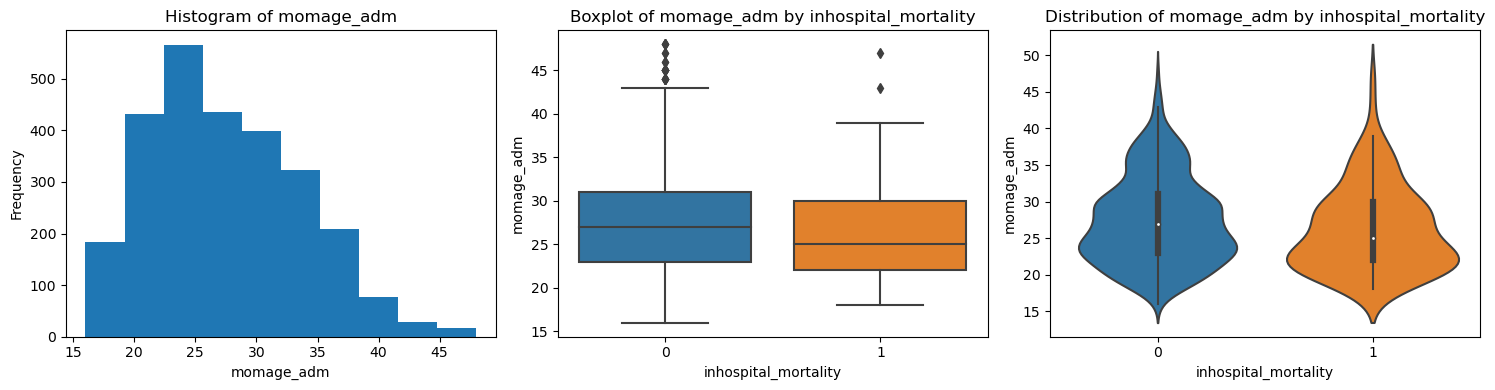

Normality Test Result for momage_adm: for 'momage_adm'distirbution is normal
Mean and Variance Equality Test Result for momage_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: momagefirstpreg_adm


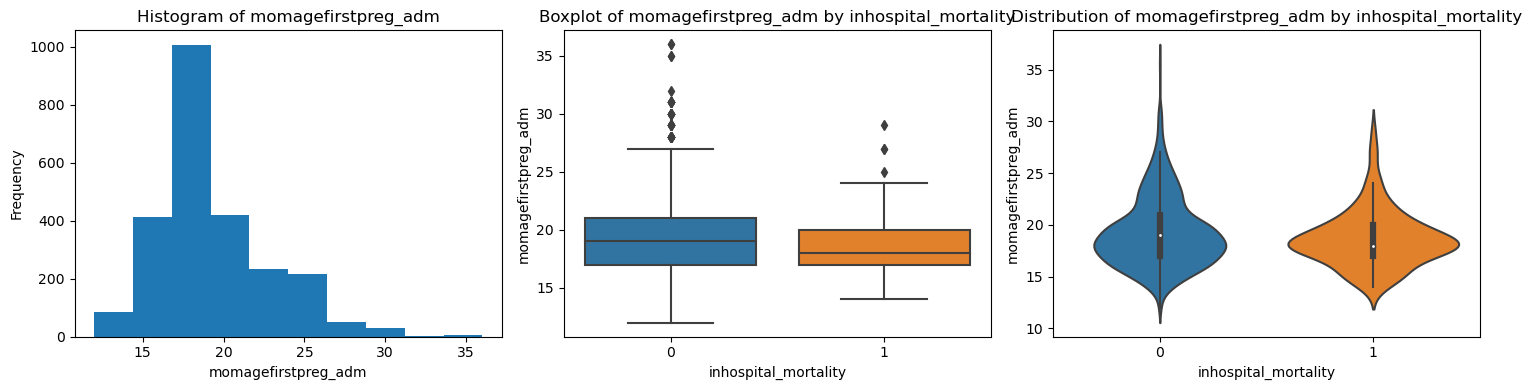

Normality Test Result for momagefirstpreg_adm: for 'momagefirstpreg_adm'distirbution is normal
Mean and Variance Equality Test Result for momagefirstpreg_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: householdsize_adm


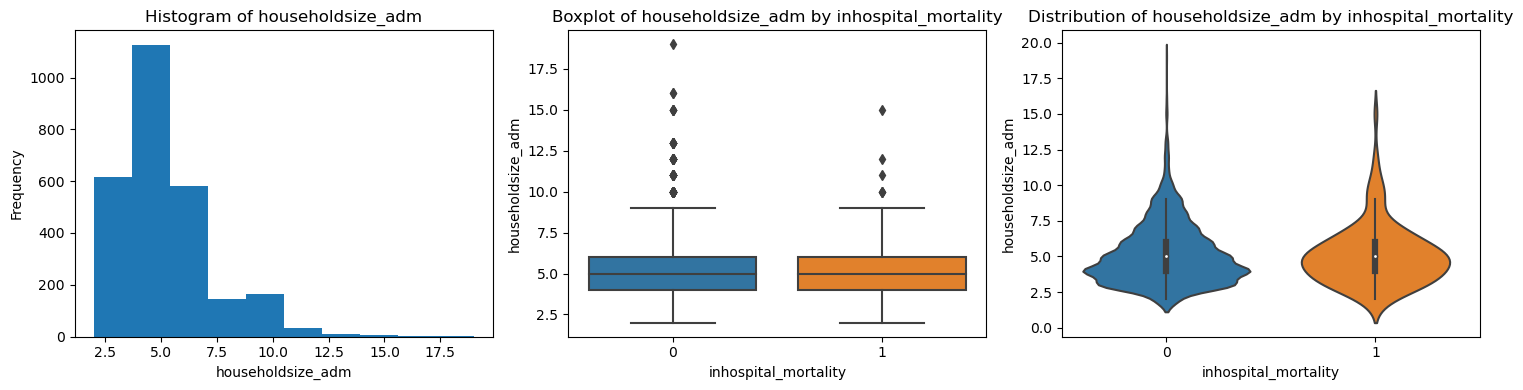

Normality Test Result for householdsize_adm: for 'householdsize_adm'distirbution is normal
Mean and Variance Equality Test Result for householdsize_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: alivechildren_adm


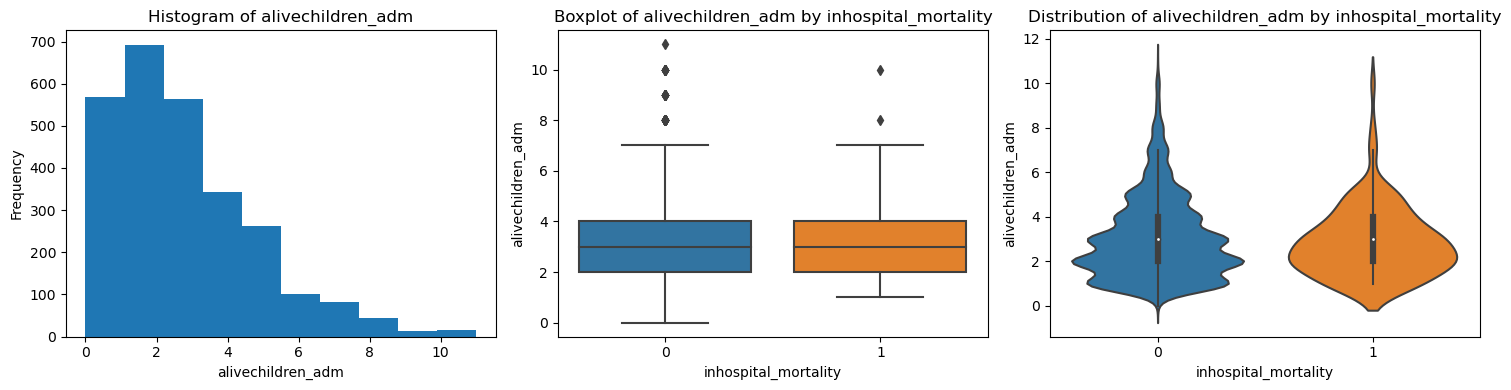

Normality Test Result for alivechildren_adm: for 'alivechildren_adm'distirbution is normal
Mean and Variance Equality Test Result for alivechildren_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: deadchildren_adm


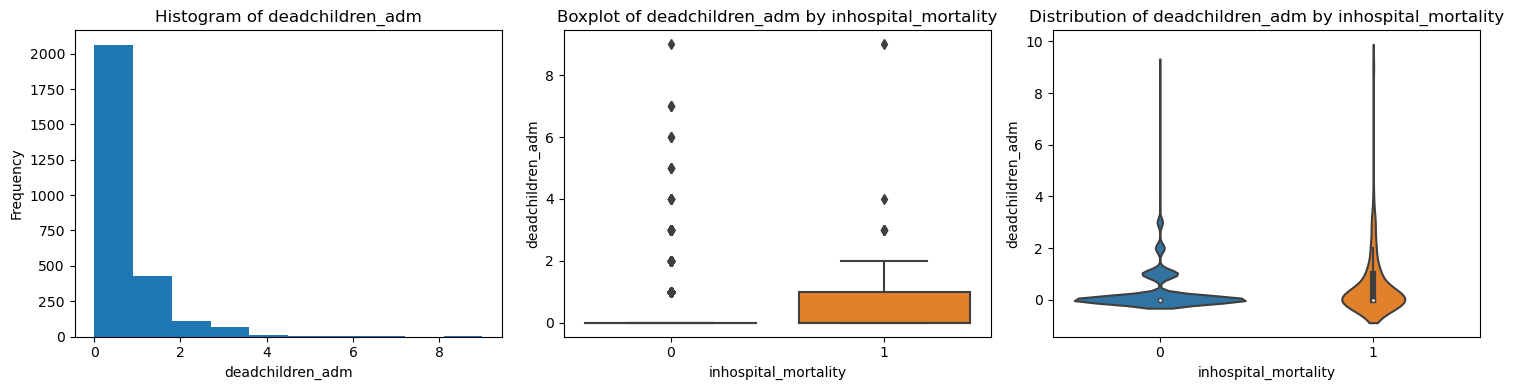

Normality Test Result for deadchildren_adm: for 'deadchildren_adm'distirbution is normal
Mean and Variance Equality Test Result for deadchildren_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: hematocrit_gpdl_adm


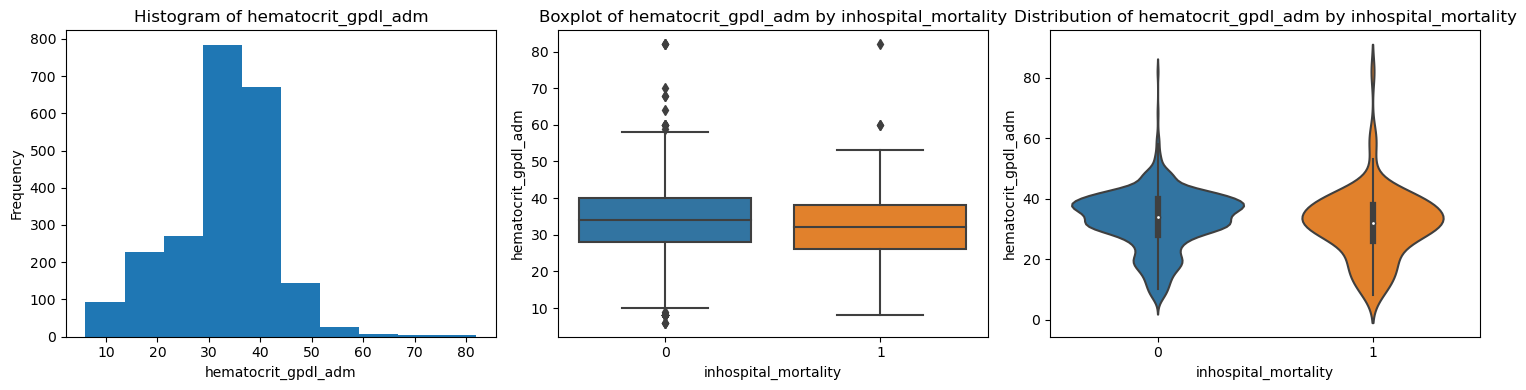

Normality Test Result for hematocrit_gpdl_adm: for 'hematocrit_gpdl_adm'distirbution is normal
Mean and Variance Equality Test Result for hematocrit_gpdl_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: lactate_mmolpl_adm


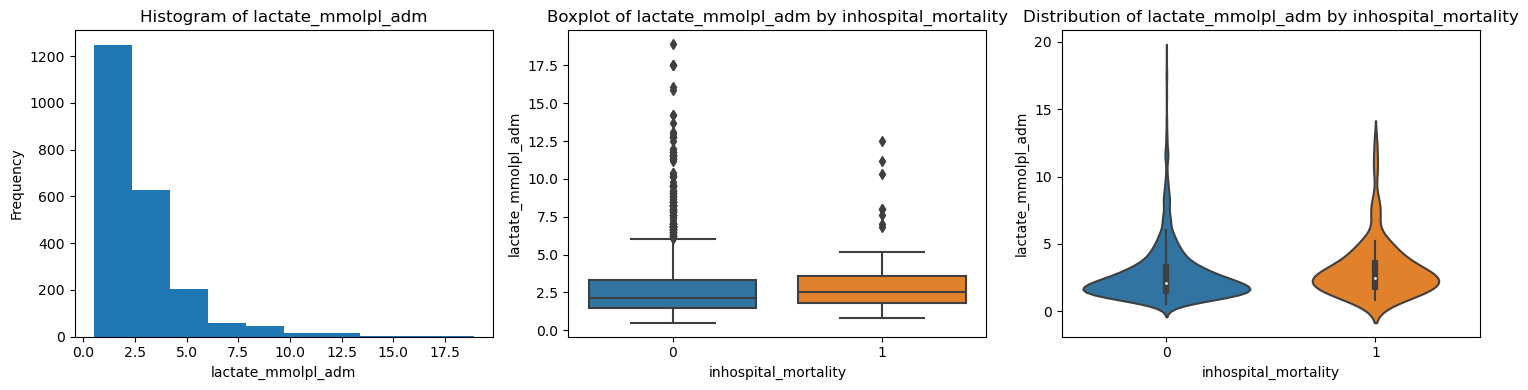

Normality Test Result for lactate_mmolpl_adm: for 'lactate_mmolpl_adm'distirbution is normal
Mean and Variance Equality Test Result for lactate_mmolpl_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: lactate2_mmolpl_adm


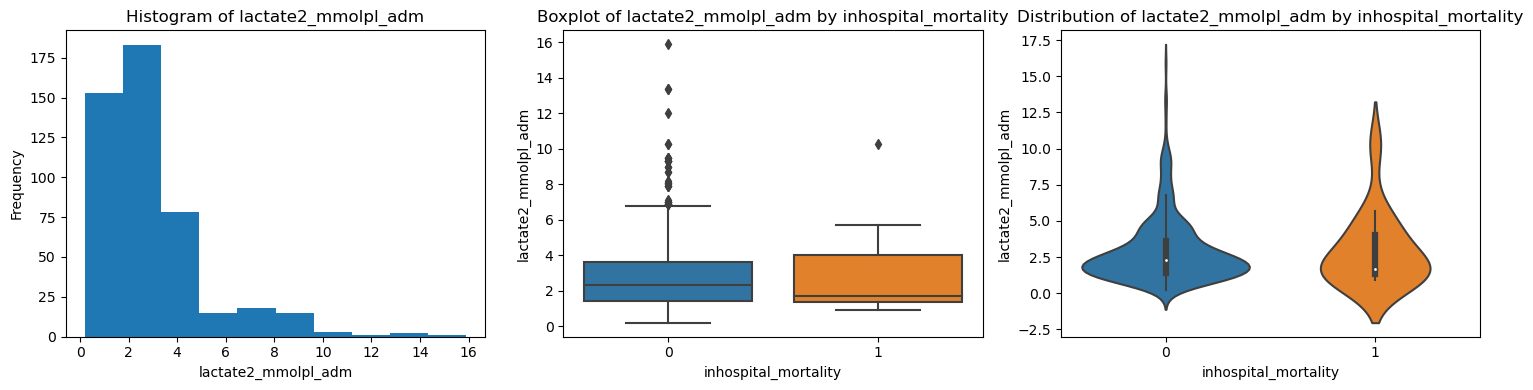

Normality Test Result for lactate2_mmolpl_adm: for 'lactate2_mmolpl_adm'distirbution is normal
Mean and Variance Equality Test Result for lactate2_mmolpl_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: glucose_mmolpl_adm


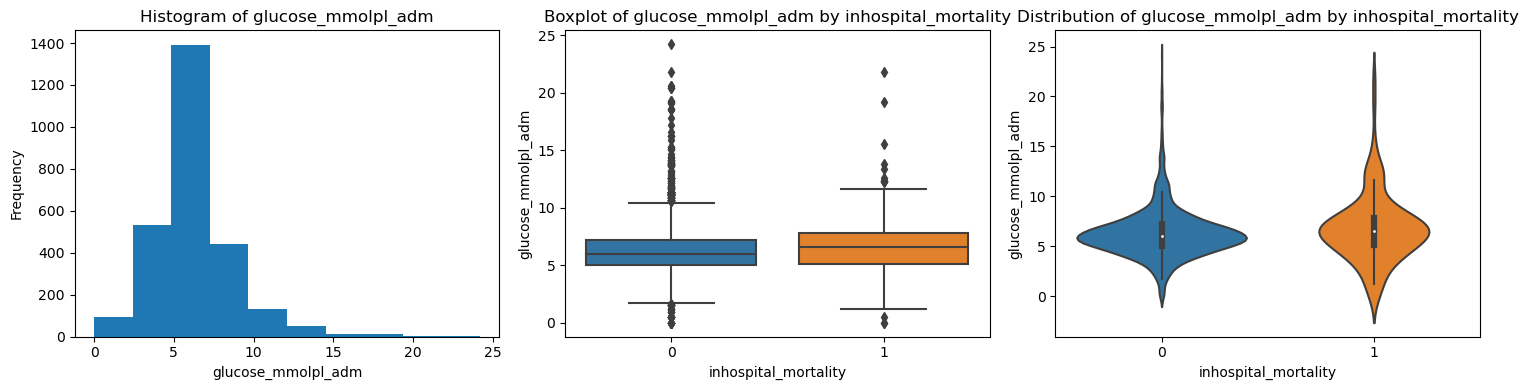

Normality Test Result for glucose_mmolpl_adm: for 'glucose_mmolpl_adm'distirbution is normal
Mean and Variance Equality Test Result for glucose_mmolpl_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: sqi1_perc_oxi_adm


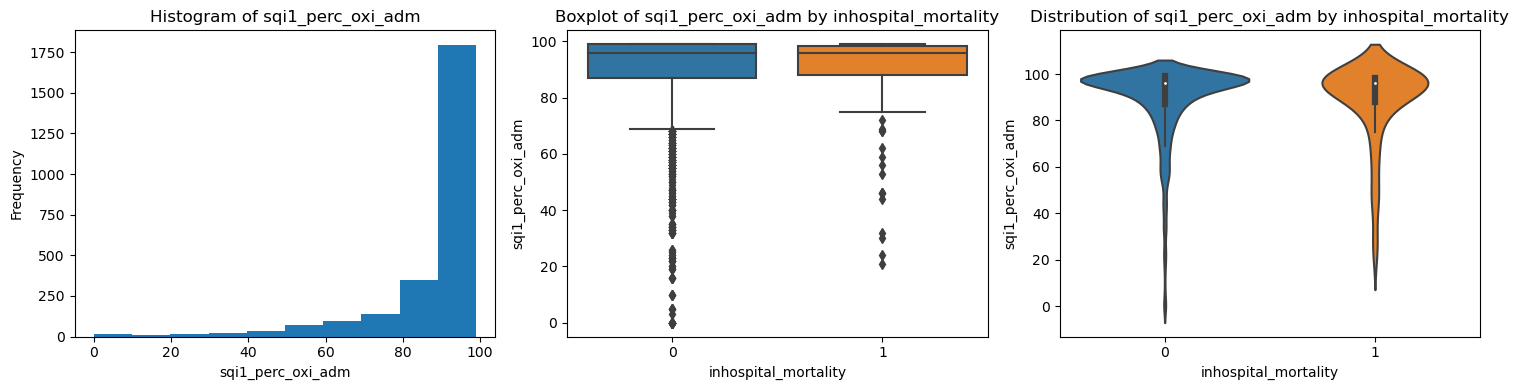

Normality Test Result for sqi1_perc_oxi_adm: for 'sqi1_perc_oxi_adm'distirbution is normal
Mean and Variance Equality Test Result for sqi1_perc_oxi_adm: ('variance is equal', 'average are equal')

--------------------------------------------------

Analyzing column: sqi2_perc_oxi_adm


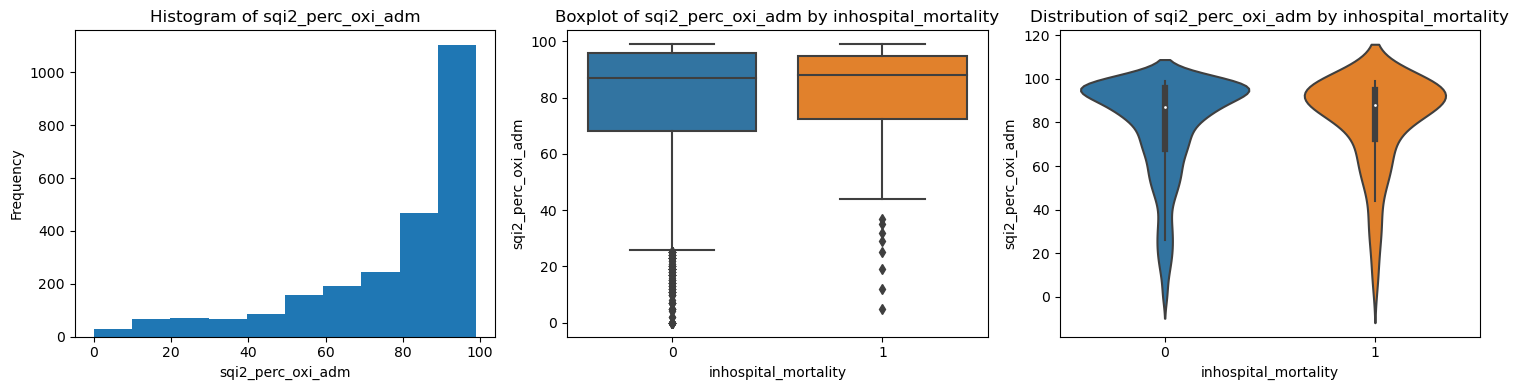

Normality Test Result for sqi2_perc_oxi_adm: for 'sqi2_perc_oxi_adm'distirbution is normal
Mean and Variance Equality Test Result for sqi2_perc_oxi_adm: ('variance is equal', 'average are equal')

--------------------------------------------------



In [25]:
# Select numerical columns
numerical_columns = clean_data.select_dtypes(include=['float64', 'int64']).columns

# Loop through each numerical column to apply the analysis
for column in numerical_columns:
    print(f"Analyzing column: {column}")
    
    # Call the plots_statistical_analysis function
    normality_result, mean_equal_result = plots_statistical_analysis(column)
    
    # Print the results for the current column
    print(f"Normality Test Result for {column}: {normality_result}")
    print(f"Mean and Variance Equality Test Result for {column}: {mean_equal_result}")
    print("\n" + "-" * 50 + "\n")


### **New dataset: Intervention columns removed, outcome 'inhospital_mortality' datatype fixed, and 'studyid_adm' and 'length' removed. Pending deal with missing data**

In [26]:
# Save the dataset
# clean_data.to_csv('clean_dataset.csv', index=False)